# 0) Table of Contents

1. [Data loading and basic sanity checks](#sec-1)
    - [Step 1.1 - Clean column names](#sec-1-1)
    - [Step 1.2 - Standardize data types of columns](#sec-1-2)
    - [Step 1.3 - Deduplication](#sec-1-3)
    - [Step 1.4 - Creating Merged Df](#sec-1-4)
2. [Data quality checks](#sec-2)
    - [Step 2.1 - Feature Stats](#sec-2-1)
    - [Step 2.2 - Value Counts and Number of Groups](#sec-2-2)
    - [Step 2.3 - Missing Values](#sec-2-3)
    - [Step 2.4 - Fixing invalid / implausible values](#sec-2-4)
    - [Step 2.5 - Feature Engineering of Base features (to help in EDA later)](#sec-2-5)
    - [Sanity Check](#sec-2-6)
    - [Step 2.6 - Missing Value Analysis](#sec-2-7)
    - [Step 2.7 - Feature Stats 2.0](#sec-2-8)
3. [Target variable distribution and class imbalance](#sec-3)
    - [Step 3.1 - Target class distribution](#sec-3-1)
4. [Bias / imbalance checks (diagnosis)](#sec-4)
    - [Step 4.1 — Label rate by operational subgroup](#sec-4-1)
    - [Step 4.2 — Label rate by missingness, low-support flags & leakage scan](#sec-4-2)
5. [Univariate EDA (numerical variables)](#sec-5)
    - [Step 5.1 — Distribution profiles and histograms](#sec-5-1)
    - [Step 5.2 — Box/violin, QQ plots and multi-rule outlier scan](#sec-5-2)
6. [Univariate EDA (categorical variables)](#sec-6)
    - [Step 6.1 — Category distributions and target association](#sec-6-1)
7. [Bivariate EDA (Feature ↔ Target)](#sec-7)
    - [Layer 0 — Quick context](#sec-7-1)
    - [Layer 1 — Wide scan (all features)](#sec-7-2)
    - [Layer 2 — Deep dives (shortlist)](#sec-7-3)
8. [Bivariate EDA (Feature ↔ Feature)](#sec-8)
    - [Step 8.1 — Numeric ↔ Numeric](#sec-8-1)
    - [Step 8.2 — Categorical ↔ Categorical](#sec-8-2)
    - [Step 8.3 — Numeric ↔ Categorical](#sec-8-3)
9. [Missing values handling](#sec-9)
    - [Step 9.1 — Missingness distribution and patterns](#sec-9-1)
    - [Step 9.2 — Standardized imputation (simple + advanced)](#sec-9-2)
10. [Outlier handling](#sec-10)
    - [Step 10.1 — Numeric detection and data-error correction](#sec-10-1)
    - [Step 10.2 — Numeric treatment (winsorise + skew transforms)](#sec-10-2)
    - [Step 10.3 — Categorical outliers (rare-level grouping)](#sec-10-3)
11. [Bivariate EDA revisited (post-cleaning)](#sec-11)
    - [Step 11.1 — Relationships after cleaning](#sec-11-1)
12. [Feature engineering (informed by EDA)](#sec-12)
    - [Step 12.1 — Removal, creation, combination and binning](#sec-12-1)
    - [Step 12.2 — Encoding, dimensionality reduction (PCA) and final matrix](#sec-12-2)
13. [Post-feature checks](#sec-13)
    - [Step 13.1 — New-feature signal, distributions and predictive ranking](#sec-13-1)
14. [Linking EDA to modelling decisions](#sec-14)
    - [14.1 — Decision register: EDA finding → modelling decision](#sec-14-1)
    - [14.2 — Algorithm selection, and how imbalance & skew shaped it](#sec-14-2)
15. [Define evaluation metric and validation strategy](#sec-15)
    - [15.1 — Metric selection](#sec-15-1)
    - [15.2 — Decision-threshold policy and cross-model consistency](#sec-15-2)
    - [15.3 — Validation strategy](#sec-15-3)

<a id="sec-1"></a>

# 1) Data loading and basic sanity checks

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas.api.types as ptypes
from datetime import datetime
from tabulate import tabulate
import sqlite3
import pandas as pd
from sqlalchemy import create_engine, text
import requests
import sqlite3
import pandas as pd
from typing import Dict, Optional

pd.set_option('display.max_columns', None)
# pd.reset_option('display.max_columns')

In [2]:
def inspect_and_load_db(url: str, db_path: str) -> Optional[Dict[str, pd.DataFrame]]:
    """
    Downloads a SQLite database from a URL and loads all tables into pandas DataFrames.

    This function fetches a SQLite file from the specified URL, saves it locally, 
    inspects the database schema to find all user-defined tables, and reads 
    each table into a separate pandas DataFrame.

    Args:
        url (str): The URL pointing to the SQLite database file to download.
        db_path (str): The local file path where the database will be saved.

    Returns:
        Optional[Dict[str, pd.DataFrame]]: A dictionary where the keys are table names (str) 
        and the values are the corresponding data (pandas.DataFrame). 
        Returns None if no tables are found in the database.

    Raises:
        requests.HTTPError: If the HTTP request to download the file fails.
        sqlite3.Error: If there is an issue interacting with the SQLite database.
    """
    # 1. Download the DB file (using chunks to handle large files efficiently)
    print(f"Downloading database from {url}...")
    response = requests.get(url, stream=True)
    response.raise_for_status()
    
    with open(db_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=8192):
            file.write(chunk)
            
    print(f"Saved database to local file: '{db_path}'\n")

    # 2. Connect and check table names safely using a context manager
    with sqlite3.connect(db_path) as conn:
        cursor = conn.cursor()
        
        # Query to fetch all user-defined tables
        cursor.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%';")
        tables = [row[0] for row in cursor.fetchall()]
        
        if not tables:
            print("The database downloaded successfully, but it contains no tables.")
            return None

        print(f"Tables found in database: {tables}")
        print("-" * 60)

        # 3. Load ALL tables into a dictionary
        db_data = {}
        for table in tables:
            print(f"Loading data from table: '{table}'...")
            db_data[table] = pd.read_sql(f"SELECT * FROM {table}", conn)
    
    # Context manager automatically handles conn.close() for us
    return db_data

In [3]:
url = "https://techassessment.blob.core.windows.net/aiap24-assessment-data/delivery.db"  # Your URL
db_path = "data/delivery.db"
df_dict =inspect_and_load_db(url, db_path)

Saved database to local file: 'data/delivery.db'

Tables found in database: ['deliveries', 'feedback']
------------------------------------------------------------
Loading data from table: 'deliveries'...
Loading data from table: 'feedback'...


In [4]:
# 1. Create a folder to store all the CSVs (optional, but keeps things organized)
output_folder = "data"
os.makedirs(output_folder, exist_ok=True)

# 2. Loop through the dictionary and save each one
# (Assuming 'df_dict' is the dictionary returned by the inspect_and_load_db function)
for table_name, df in df_dict.items():
    # Construct the file path (e.g., "exported_tables/users.csv")
    file_path = os.path.join(output_folder, f"{table_name}.csv")
    
    # Save the DataFrame to CSV
    # index=False prevents pandas from writing row numbers (0, 1, 2...) into the file
    df.to_csv(file_path, index=False)
    
    print(f"Successfully saved '{table_name}' to {file_path}")

print("\nAll tables have been exported!")

Successfully saved 'deliveries' to data\deliveries.csv
Successfully saved 'feedback' to data\feedback.csv

All tables have been exported!


In [5]:
# Loop through the dictionary
for table_name, df in df_dict.items():
    # Dynamically create a global variable (df) with the table's name
    globals()[table_name] = df
    print(f"Created df: {table_name}")

Created df: deliveries
Created df: feedback


In [6]:
display(deliveries.head(5))
display(feedback.head(5))

,delivery_id,branch,client_id,booking_datetime,pickup_datetime,promised_delivery_datetime,delivery_datetime,distance_km,parcel_weight_kg,parcel_value_sgd,parcel_category,delivery_priority,num_stops_on_route,driver_id,driver_experience_months,vehicle_type,payment_method,recipient_postal_code
0,D2026000000,North,C0000,2026-01-17 16:10:11.419632,2026-01-17 18:14:42.141079,2026-01-18 00:10:11.419632,2026-01-17 23:58:29.106853,5.86,0.585,102.05,standard,Standard,62.0,DRV0130,2.0,van,prepaid,57
1,D2026000001,North,C0007,2025-12-06 15:33:02.496777,2025-12-06 16:11:03.931680,2025-12-06 19:33:02.496777,2025-12-06 18:53:45.937422,3.10,3.292,105.17,standard,Express,NaN,DRV0087,33.0,van,cod,73
2,D2026000002,East,C0000,2026-04-20 16:32:08.934038,2026-04-20 19:54:14.157180,2026-04-21 00:32:08.934038,2026-04-21 00:06:28.451910,8.03,1.426,36.48,standard,Standard,35.0,DRV0040,35.0,van,cod,51
3,D2026000003,East,C0002,2026-05-11 12:15:01.850095,2026-05-11 14:44:34.713623,2026-05-11 20:15:01.850095,2026-05-11 21:29:30.086468,6.06,2.163,71.8,fragile,Standard,90.0,DRV0109,9.0,van,prepaid,49
4,D2026000004,North,C0009,2026-05-20 14:32:47.616722,2026-05-20 15:50:24.743132,2026-05-20 18:32:47.616722,2026-05-20 17:46:23.101404,4.65,0.7,18.05,standard,Express,54.0,DRV0085,24.0,bike,prepaid,73


,feedback_id,delivery_id,rating,comment,feedback_datetime
0,F01000000,D2026000001,5.0,"On time as always, thanks! Driver very polite,...",2025-12-07 02:17:46.889241
1,F01000001,D2026000003,3.0,Delivery was acceptable.,2026-05-12 11:00:52.289329
2,F01000002,D2026000011,5.0,"Great experience, no complaints.",2026-04-11 08:19:49.177079
3,F01000003,D2026000012,5.0,,2025-12-31 11:57:23.657124
4,F01000004,D2026000013,4.0,,2026-02-24 04:52:01.214870


In [7]:
def value_counts(df, top_n=15, drop_singletons=True):
    """
    Generates a frequency summary for all columns, calculating counts, percentages, and unique values.
    Key parameters: df (DataFrame to analyze), top_n (number of top categories to keep), drop_singletons (boolean to remove categories with a count of 1).
    Returns: A dictionary containing summary DataFrames and unique count integers for each column.
    """
    report = {}
    for col in df.columns:
        counts = df[col].value_counts(dropna=False)
        percents = df[col].value_counts(dropna=False, normalize=True) * 100

        summary = pd.DataFrame({
            'count': counts,
            'percent': percents.round(2)
        })

        # keep track of true uniques
        num_unique_excl_nan = df[col].nunique(dropna=True)
        num_unique_incl_nan = df[col].nunique(dropna=False)

        # 🔑 Optionally drop categories that occur only once
        if drop_singletons:
            summary = summary[summary['count'] > 1]

        report[col] = {
            "summary": summary.head(top_n),
            "unique_excl_nan": num_unique_excl_nan,
            "unique_incl_nan": num_unique_incl_nan
        }

    return report


def print_value_counts_report(df, name, n=15, drop_singletons=True):
    """
    Prints a formatted console report displaying the most frequent categories for each column.
    Key parameters: df (DataFrame to analyze), name (title for the report), n (number of top categories to display), drop_singletons (boolean to hide single-occurrence items).
    Returns: None (outputs the compiled text directly to the console).
    """
    print(f"\n🟩🟩🟩🟩🟩🟩🟩 {name} 🟩🟩🟩🟩🟩🟩🟩\n")

    report = value_counts(df, n, drop_singletons)

    print(f'Showing only top {n} categories for each column')
    
    if drop_singletons:
        print('⚠️ Singleton categories (count = 1) are not shown ⚠️')

    for col, info in report.items():
        print(f"\n 🗂️🗂️🗂️ Column: {col} 🗂️🗂️🗂️\n")
        print(f"Unique categories (excl. NaN) = {info.get('unique_excl_nan')}")
        print(f"Unique categories (incl. NaN) = {info.get('unique_incl_nan')}\n")
        print(info.get("summary"))


def missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculates the total number and percentage of missing (NaN) values present in each column.
    Key parameters: df (the pandas DataFrame to evaluate for missing data).
    Returns: A pandas DataFrame with 'Missing Values' and 'Missing %' columns, sorted descending, excluding fully populated columns.
    """
    if len(df) == 0:
        print("Warning: The DataFrame is empty.")
        return pd.DataFrame(columns=['Missing Values', 'Missing %'])

    missing_count = df.isnull().sum()
    missing_percent = (missing_count / len(df)) * 100
    
    summary_df = pd.DataFrame({
        'Missing Values': missing_count,
        'Missing %': missing_percent.round(2)
    })
    
    return summary_df[summary_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)


def df_report(df: pd.DataFrame, name: str = "Dataset", n: int = 15, drop_singletons=True):
    """
    Generates a comprehensive EDA summary, printing the dataset's shape, schema info, value counts, and missing values.
    Key parameters: df (DataFrame to analyze), name (title for the report), n (number of top value counts to show), drop_singletons (boolean to hide single-occurrence items).
    Returns: None (orchestrates and prints the results of other helper functions to the console).
    """
    # 1. Print shapes 
    print(f'\n📊📊📊📊📊 {name.upper()} DF REPORT 📊📊📊📊📊\n')
    print(f'DataFrame shape ➡️➡️➡️ {df.shape}\n')

    # 2. Print info
    print('➡️➡️➡️  DataFrame info  ⬅️⬅️⬅️\n')
    df.info()

    # 3. Print value counts
    print_value_counts_report(df, name=name, n=n, drop_singletons=drop_singletons)

    # 4. Print missing summary
    print('\n ❓❓❓❓❓ Missing values summary ❓❓❓❓❓\n')
    print(missing_values(df))

In [8]:
# Create a dictionary mapping the string name to the DataFrame variable
dfs_dict = {
    "Feedback": feedback,
    "Deliveries": deliveries
}

# Loop through the dictionary and run the report
for name, df in dfs_dict.items():
    df_report(df, name=name, n=15, drop_singletons=True)
    print(f"\n🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁\n")


📊📊📊📊📊 FEEDBACK DF REPORT 📊📊📊📊📊

DataFrame shape ➡️➡️➡️ (54972, 5)

➡️➡️➡️  DataFrame info  ⬅️⬅️⬅️

<class 'pandas.DataFrame'>
RangeIndex: 54972 entries, 0 to 54971
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   feedback_id        54972 non-null  str    
 1   delivery_id        54972 non-null  str    
 2   rating             52731 non-null  float64
 3   comment            52778 non-null  str    
 4   feedback_datetime  54972 non-null  str    
dtypes: float64(1), str(4)
memory usage: 6.1 MB

🟩🟩🟩🟩🟩🟩🟩 Feedback 🟩🟩🟩🟩🟩🟩🟩

Showing only top 15 categories for each column
⚠️ Singleton categories (count = 1) are not shown ⚠️

 🗂️🗂️🗂️ Column: feedback_id 🗂️🗂️🗂️

Unique categories (excl. NaN) = 54699
Unique categories (incl. NaN) = 54699

             count  percent
feedback_id                
F01000173        2      0.0
F01000363        2      0.0
F01000502        2      0.0
F01000520        2      0.0
F01000675 

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Establish the structure, quality, and modelling relevance of the `deliveries` and `feedback` tables after loading them from the database.
- Identify early data-quality issues such as missing values, duplicated identifiers, inconsistent categories, and invalid numeric placeholders before deeper EDA and preprocessing.

##### B) Insights

- The database contains two main tables: 
  - `deliveries` with 150,750 rows and 18 columns, and 
  - `feedback` with 54,972 rows and 5 columns. 
  - The sample records show that `feedback` links back to `deliveries` through `delivery_id`, 
    - making it suitable for a joined analysis where delivery operations can be connected to customer satisfaction outcomes.
- `deliveries` has 150,000 unique `delivery_id` values despite 150,750 rows 
- `feedback` has 54,699 unique `feedback_id` and `delivery_id` values despite 54,972 rows. 
  - This indicates duplicated identifier records in both tables, which creates a risk of double-counting deliveries or feedback if the data is aggregated or merged without deduplication.

- Missingness in `feedback`: 
  - Blank comments are the most frequent comment value at 9,261 rows (16.85%), showing that absence of text appears both as null values and empty strings
    - this inconsistency can bias text-based or sentiment-based features if not standardized.
    
- Missingness in `deliveries` appears across multiple operational fields at a similar level of about 3.91% to 4.07% . 
  - Because the missing rates cluster tightly, they may reflect a systematic data capture issue rather than isolated random gaps.
- Several numeric fields in `deliveries` are stored as strings, including `parcel_weight_kg`, `parcel_value_sgd`, `num_stops_on_route`, and `driver_experience_months`. 
  - This creates a direct preprocessing requirement because numeric summaries, transformations, and modelling algorithms will treat these incorrectly unless they are converted safely.
- Invalid sentinel values are present in numeric-like columns: 
  - `parcel_weight_kg` has `-1.0` in 2,178 rows (1.44%) and `parcel_value_sgd` has `-1.0` in 2,245 rows (1.49%). 
    - These values are not plausible for weight or parcel value and should be treated as invalid data rather than genuine measurements.
- Several categorical fields contain inconsistent labels that represent the same real-world category. Examples include:
  -  `branch` values such as `Central`, `Cnetral`, `west`, `EAST`, and `Noth`; 
  - `parcel_category` values such as `standard`, `Standard`, `over-sized`, and `refrig.`; 
  - `vehicle_type` values such as `van`, `VAN`, `bike`, and `Bike`. 
    - This creates artificial cardinality and can weaken group-level analysis or one-hot encoded model features.
- Several datetime fileds are stored as strings and should be converted to datetime type for datetime operations


##### C) Preprocessing Decisions

- Deduplicate both tables before merging or aggregation. 
  - Since both `delivery_id` and `feedback_id` show fewer unique values than total rows 
    - duplicate handling is necessary to avoid inflated counts and biased customer-feedback summaries.
- Convert numeric-like string columns in `deliveries` to numeric types using safe coercion. 
  - This should be applied to `parcel_weight_kg`, `parcel_value_sgd`, `num_stops_on_route`, and `driver_experience_months` so that invalid values can be detected, numeric distributions can be analysed, and models receive proper numerical inputs.
- Keep `recipient_postal_code` as string, not integer
  - because it is an identifier/location code rather than a numeric measurement.
- Convert certain ID columns to pandas string dtype. 
  - They are identifiers/categorical text, so string is more appropriate than generic Python object/str.
- Standardize categorical labels before modelling. 
  - Case normalization, spelling correction, and label mapping should be applied to fields such as `branch`, `parcel_category`, and `vehicle_type` 
    - because the value-count reports show inconsistent labels that likely represent the same categories.


##### D) Actionable Feature Engineering

- Create cleaned categorical features for `branch`, `parcel_category`, and `vehicle_type` after correcting spelling and casing variants. 
  - This reduces artificial category fragmentation and improves interpretability of segment-level analysis.


##### E) Actionable Model Development


- Include tree-based models as strong candidates because the data contains mixed numeric and categorical operational features, non-linear delivery effects, missingness indicators, and potential interactions among distance, stops, priority, vehicle type, and driver experience.
- Include a regularized logistic model as a transparent baseline after numeric conversion, categorical encoding, and missing-value handling. This provides an interpretable benchmark and helps assess whether more complex models add meaningful value.
- Use validation that respects the joined unit of analysis, likely at the `delivery_id` level, to prevent duplicated deliveries or multiple feedback rows from leaking across train and validation splits.
- Evaluate both overall performance and segment-level performance by branch, priority, vehicle type, and payment method. The EDA shows operational imbalance across these categories, so aggregate metrics alone may hide weak performance on smaller but important groups.


##### F) Conclusions

- The dataset features large, joinable records with duplicate IDs, inconsistent categories, invalid placeholders, and 4% systematic missingness. 
- These initial EDA findings directly justify a preprocessing pipeline focused on deduplication, type casting, category standardization, and the extraction of time-based features. 
- To handle the resulting skewed distributions and operational imbalances, the modeling phase will utilize group-aware validation, specialized metrics, and a blend of interpretable baselines with tree-based models.


#### 📌📌📌 **Next Immediate Step(s)** 📌📌📌

- Clean the data before deeper EDA by: 
  - standardizing categorical labels
  - converting numeric-like string columns to numeric types, 
  - converting datetime liek colums to datetype type and round off to nearest sec
  - convert str type columns to string types for ensuring data integrity and preventing silent bugs during modeling pipeline.
  - deduplicating both tables 
- Create a joined analysis table using `delivery_id` so delivery-level features can be linked to feedback outcomes. 
- Re-check missingness, duplicates, and key value counts for validation

<a id="sec-1-1"></a>

### Step 1.1 - Clean column names

- Remove whitespaces and lowercase categories

In [9]:
def clean_category_names(df, columns):
    """
    Cleans selected categorical columns by stripping whitespace and lowercasing values.
    Use this before value counts, grouping, encoding, or modelling to reduce duplicate labels.
    Key parameters: df is the input DataFrame; columns is a list of categorical column names.
    Returns a copied DataFrame with cleaned category values in the selected columns.
    """
    cleaned_df = df.copy()

    for column in columns:
        # Convert to pandas string dtype so string operations handle missing values safely.
        cleaned_df[column] = cleaned_df[column].astype("string").str.strip().str.lower()

    return cleaned_df

In [10]:
cols_to_clean = ["branch", "parcel_category","delivery_priority" , "vehicle_type"]
deliveries = clean_category_names(deliveries, cols_to_clean)

- cnetral is assummed to be a spelling error during logging and assumed to be central
- noth is assumed to be a spelling error during logging and assumed to be north
- refrig. is assumed to be a spelling error during logging and assumed to be refrigerated
- over-sized is assumed to be a spelling error during logging and assumed to be oversized

In [11]:
deliveries["branch"] = deliveries["branch"].replace({
    "cnetral": "central",
    "noth": "north"
})

deliveries["parcel_category"] = deliveries["parcel_category"].replace({
    "refrig.": "refrigerated",
    "over-sized": "oversized"
})

In [12]:
def round_datetime_columns(df, columns):
    """
    Converts selected columns to pandas datetime and rounds them to the nearest second.
    Use this when timestamps should remain datetime objects for time-based calculations.
    Key parameters: df is the input DataFrame; columns contains datetime column names.
    Returns a copied DataFrame with rounded datetime values.
    """
    rounded_df = df.copy()

    for column in columns:
        # Keep as datetime, but remove fractional seconds from the actual values.
        rounded_df[column] = pd.to_datetime(
            rounded_df[column],
            errors="coerce"
        ).dt.round("s")

    return rounded_df

<a id="sec-1-2"></a>

### Step 1.2 - Standardize data types of columns 

- Converting columns to their appropriate datatype

In [13]:
datetime_cols_feedback = ["feedback_datetime"]
datetime_cols_delivery = ["booking_datetime", "pickup_datetime", "promised_delivery_datetime", "delivery_datetime"]
int_cols = ["driver_experience_months", "num_stops_on_route"]
float_cols = ["parcel_weight_kg", "parcel_value_sgd"]
string_cols_delivery = ["delivery_id", "client_id", "driver_id", "payment_method", "recipient_postal_code"]
string_cols_feedback = ["feedback_id","delivery_id","comment"]

# Convert datetime columns from str to datetime rounded to nearest sec
deliveries = round_datetime_columns(deliveries, datetime_cols_delivery)
feedback = round_datetime_columns(feedback,datetime_cols_feedback )

# Convert count-like numeric columns to nullable integers
for col in int_cols:
    deliveries[col] = pd.to_numeric(deliveries[col], errors="coerce").astype("Int64")

feedback["rating"] = pd.to_numeric(feedback["rating"], errors="coerce").astype("Int64")

# Convert continuous numeric columns to float
for col in float_cols:
    deliveries[col] = pd.to_numeric(deliveries[col], errors="coerce")

# Convert str type columns to string type
deliveries[string_cols_delivery] = deliveries[string_cols_delivery].astype("string")
feedback[string_cols_feedback] = feedback[string_cols_feedback].astype("string")

<a id="sec-1-3"></a>

### Step 1.3 - Deduplication

- Just a check to see if repeated delivery_id/feedback_id records are not conflicting records, meaning they are exact duplicate rows.

In [14]:
# Shows all rows that are duplicates of an earlier row
df1 = deliveries[deliveries.duplicated()]
df2 = deliveries[deliveries.duplicated(subset=["delivery_id"])]
if(df1.equals(df2)):
    print("full-row duplicates and delivery_id duplicates are identical for deliveries")
else:
    print("full-row duplicates and delivery_id duplicates are not identical for deliveries")

df3 = feedback[feedback.duplicated()]
df4 = feedback[feedback.duplicated(subset=["feedback_id"])]
df5 = feedback[feedback.duplicated(subset=["delivery_id"])]
if(df3.equals(df4) & df3.equals(df5)):
    print("full-row duplicates and feedback_id duplicates and delivery_id duplicates are identical for feedback")
else:
    print("full-row duplicates and feedback_id duplicates and delivery_id duplicates are not identical for feedback")


full-row duplicates and delivery_id duplicates are identical for deliveries
full-row duplicates and feedback_id duplicates and delivery_id duplicates are identical for feedback


- Repeated delivery_id/feedback_id records are not conflicting records, meaning they are exact duplicate rows.


In [15]:
def drop_dupes_with_report(df, subset=None, keep="first"):
    """
    Drops duplicate rows from a DataFrame and prints duplicate counts before and after.
    Use subset to check duplicates by selected columns, or None for exact full-row duplicates.
    Key parameters: df is the input DataFrame, subset defines duplicate-check columns, keep controls which duplicate to retain.
    Returns a cleaned DataFrame with duplicates removed.
    """
    # Count "extra copies" of duplicates before dropping
    before = int(df.duplicated(subset=subset, keep="first").sum())
    print(f"Duplicates (extra copies) BEFORE drop: {before}")

    # Drop duplicates (returns a new DataFrame)
    df_clean = df.drop_duplicates(subset=subset, keep=keep)

    # Count again (should be 0 if keep is 'first' or 'last')
    after = int(df_clean.duplicated(subset=subset, keep="first").sum())
    print(f"Duplicates (extra copies) AFTER drop:  {after}")

    return df_clean

In [16]:
print("---> Deliveries")
deliveries = drop_dupes_with_report(deliveries)
deliveries = deliveries.reset_index(drop=True)
print("---> Feedback")
feedback = drop_dupes_with_report(feedback)
feedback = feedback.reset_index(drop=True)

---> Deliveries
Duplicates (extra copies) BEFORE drop: 750
Duplicates (extra copies) AFTER drop:  0
---> Feedback
Duplicates (extra copies) BEFORE drop: 273
Duplicates (extra copies) AFTER drop:  0


<a id="sec-1-4"></a>

### Step 1.4 - Creating Merged Df

In [17]:
delivery_feedback1 = deliveries.merge(
    feedback,
    on="delivery_id",
    how="left"
)

delivery_feedback2 = deliveries.merge(
    feedback,
    on="delivery_id",
    how="left",
    validate="one_to_one"
)

delivery_feedback3 = deliveries.merge(
    feedback,
    on="delivery_id",
    how="left",
    validate="one_to_many"
)

if delivery_feedback1.equals(delivery_feedback2) & delivery_feedback1.equals(delivery_feedback3) & delivery_feedback2.equals(delivery_feedback3):
    print("All three delivery_feedback DataFrames are identical")
else:
    print("At least one of the delivery_feedback DataFrames is different")

All three delivery_feedback DataFrames are identical


- The identical outputs confirm that the delivery_id key is unique enough in both tables after deduplication for a one-to-one merge.
- This means joining deliveries and feedback on delivery_id does not inflate the dataset through many-to-one or one-to-many matches.
- Therefore, the final joined table can be created using a left join with validate="one_to_one" to preserve all delivery records while safely attaching feedback where available.

In [18]:
delivery_feedback = deliveries.merge(
    feedback,
    on="delivery_id",
    how="left",
    validate="one_to_many"
)

- Check if no duplicates in Merged df

In [19]:
print("---> Delivery Feedback")
delivery_feedback = drop_dupes_with_report(delivery_feedback)
delivery_feedback = delivery_feedback.reset_index(drop=True)

---> Delivery Feedback
Duplicates (extra copies) BEFORE drop: 0
Duplicates (extra copies) AFTER drop:  0


In [20]:
# Create a dictionary mapping the string name to the DataFrame variable
dfs_dict = {
    "Feedback": feedback,
    "Deliveries": deliveries,
    "Delivery_Feedback": delivery_feedback
}

# Loop through the dictionary and run the report
for name, df in dfs_dict.items():
    df_report(df, name=name, n=15, drop_singletons=True)
    print(f"\n🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁\n")


📊📊📊📊📊 FEEDBACK DF REPORT 📊📊📊📊📊

DataFrame shape ➡️➡️➡️ (54699, 5)

➡️➡️➡️  DataFrame info  ⬅️⬅️⬅️

<class 'pandas.DataFrame'>
RangeIndex: 54699 entries, 0 to 54698
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   feedback_id        54699 non-null  string        
 1   delivery_id        54699 non-null  string        
 2   rating             52476 non-null  Int64         
 3   comment            52513 non-null  string        
 4   feedback_datetime  54699 non-null  datetime64[us]
dtypes: Int64(1), datetime64[us](1), string(3)
memory usage: 4.8 MB

🟩🟩🟩🟩🟩🟩🟩 Feedback 🟩🟩🟩🟩🟩🟩🟩



Showing only top 15 categories for each column
⚠️ Singleton categories (count = 1) are not shown ⚠️

 🗂️🗂️🗂️ Column: feedback_id 🗂️🗂️🗂️

Unique categories (excl. NaN) = 54699
Unique categories (incl. NaN) = 54699

Empty DataFrame
Columns: [count, percent]
Index: []

 🗂️🗂️🗂️ Column: delivery_id 🗂️🗂️🗂️

Unique categories (excl. NaN) = 54699
Unique categories (incl. NaN) = 54699

Empty DataFrame
Columns: [count, percent]
Index: []

 🗂️🗂️🗂️ Column: rating 🗂️🗂️🗂️

Unique categories (excl. NaN) = 5
Unique categories (incl. NaN) = 6

        count  percent
rating                
5       28867    52.77
4       15737    28.77
3        4196     7.67
<NA>     2223     4.06
2        2103     3.84
1        1573     2.88

 🗂️🗂️🗂️ Column: comment 🗂️🗂️🗂️

Unique categories (excl. NaN) = 878
Unique categories (incl. NaN) = 879

                                                    count  percent
comment                                                           
                                           

#### 📝📝📝 **COMMENTS** 📝📝📝

* Post-validation checks confirm that `feedback_id` and `delivery_id` are completely deduplicated across all individual and merged tables.
* Categorical lables are now clean
* Columns are of appropraite data types
* Key fields in the `deliveries` table maintain a baseline operational missingness of approximately 4%, while customer ratings remain highly skewed toward positive scores.
* Because nearly 65% of deliveries lack associated feedback, treat feedback for validation purposes only

#### 📌📌📌 **Next Immediate Step(s)** 📌📌📌

- Proceed mainly with EDA on dliveries dataset
  - table which onctains only deliveries data
  - to understand operational patterns for all 150,000 deliveries, including deliveries without feedback.
  
- Other 2 datasets may be used incase validation is needed
  - Use delivery_feedback  to link delivery factors to customer outcomes if needed
  - Use feedback to validate ratings/comments agasint deliveries (those that received feedback)

<a id="sec-2"></a>

# 2) Data quality checks

<a id="sec-2-1"></a>

### Step 2.1 - Feature Stats

In [21]:
def numeric_profile(
    df,
    num_cols,
    percentiles=(0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99),
    sort_by=("missing_pct", "skew"),
    ascending=(False, False)
):
    """
    Creates a summary profile for selected numeric columns.
    Use this to inspect missingness, spread, skewness, zero frequency, and outlier severity.
    Key parameters: df is the input DataFrame, num_cols are numeric columns, percentiles controls quantile cutoffs.
    Returns a sorted DataFrame containing numeric summary statistics.
    """
    # Generate standard descriptive statistics.
    summary = (
        df[num_cols]
        .describe(percentiles=list(percentiles))
        .T
        .rename(columns={"50%": "median"})
    )

    # Add missingness, skewness, and zero-value diagnostics.
    summary["missing_pct"] = (df[num_cols].isna().mean() * 100).round(2)
    summary["skew"] = df[num_cols].skew(numeric_only=True).round(3)
    summary["zero_pct"] = ((df[num_cols] == 0).mean() * 100).round(2)

    # Compare maximum value against the 99th percentile to flag extreme tails.
    p99_col = "99%"
    if p99_col in summary.columns:
        summary["max_over_p99"] = (
            summary["max"] / summary[p99_col].replace(0, np.nan)
        ).round(2)

    # Keep only columns that exist in the summary.
    pct_cols = [f"{int(p * 100)}%" for p in percentiles if f"{int(p * 100)}%" in summary.columns]
    selected_cols = [
        "count", "missing_pct", "mean", "std", "min",
        *pct_cols, "median", "max", "skew", "zero_pct", "max_over_p99"
    ]
    selected_cols = [col for col in selected_cols if col in summary.columns]

    return summary[selected_cols].sort_values(
        list(sort_by),
        ascending=list(ascending)
    )

def categorical_profile(df, cols=None):
    """
    Creates a summary profile for selected categorical columns.
    Use this to inspect cardinality, missingness, dominant categories, and class concentration.
    Key parameters: df is the input DataFrame; cols optionally specifies categorical columns to profile.
    Returns a sorted DataFrame with one summary row per categorical column.
    """
    if cols is None:
        cols = df.select_dtypes(
            include=["object", "category", "string", "bool"]
        ).columns.tolist()

    rows = []
    n_rows = len(df)

    for col in cols:
        # Convert to string dtype so missing values are handled consistently.
        series = df[col].astype("string")
        value_counts = series.fillna("<<MISSING>>").value_counts(dropna=False)

        rows.append({
            "col": col,
            "n_unique": int(series.nunique(dropna=False)),
            "missing_pct": round(series.isna().mean() * 100, 2),
            "top_category": str(value_counts.index[0]) if len(value_counts) > 0 else None,
            "top_pct": round((value_counts.iloc[0] / n_rows) * 100, 2) if n_rows > 0 else 0.0,
        })

    return pd.DataFrame(rows).sort_values(
        ["top_pct", "n_unique"],
        ascending=[False, False]
    )

def top_k(df, col, k=10, ascending=False):
    """
    Returns the top k rows after sorting a DataFrame by one column.
    Use this to quickly inspect the largest or smallest values in a summary table.
    Key parameters: df is the input DataFrame, col is the sorting column, k is the number of rows.
    Returns a sorted DataFrame containing the first k rows.
    """
    # Sort by the selected column and return the requested number of rows.
    return df.sort_values(col, ascending=ascending).head(k)

def run_basic_profile(df, num_cols, cat_cols, dataset_name="Dataset"):
    """
    Runs numeric and categorical profiling for a selected dataset.
    Use this to compare missingness, skewness, zero frequency, outliers, and category concentration.
    Key parameters: df is the input DataFrame, num_cols/cat_cols define columns to profile, dataset_name labels the output.
    Returns numeric and categorical summary DataFrames; returns empty DataFrames if a column list is empty.
    """
    print(f"\n\n 📊📊📊📊📊 {dataset_name.upper()} 📊📊📊📊📊")

    # Create empty defaults in case either column list has no columns.
    numeric_summary = pd.DataFrame()
    categorical_summary = pd.DataFrame()

    if num_cols:
        # Profile numerical variables only when numeric columns are available.
        numeric_summary = numeric_profile(df, num_cols)
        print("\n 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 ")
        display(numeric_summary)

        print("\n 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩")
        display(top_k(numeric_summary, "skew", ascending=False))

        print("\n 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩")
        display(top_k(numeric_summary, "zero_pct", ascending=False))

        print("\n 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩")
        display(top_k(numeric_summary, "max_over_p99", ascending=False))
    else:
        print("\nNo numeric columns provided for profiling.")

    if cat_cols:
        # Profile categorical variables only when categorical columns are available.
        categorical_summary = categorical_profile(df, cat_cols)
        print("\n 🟦🟦🟦 Categorical Variables stats 🟦🟦🟦 ")
        display(categorical_summary)
    else:
        print("\nNo categorical columns provided for profiling.")

    return numeric_summary, categorical_summary


In [22]:
cols_deliveries = deliveries.columns.tolist()
cols_feedback = feedback.columns.tolist()
cols_delivery_feedback = delivery_feedback.columns.tolist()

print(cols_deliveries)
print(cols_feedback)
print(cols_delivery_feedback)

['delivery_id', 'branch', 'client_id', 'booking_datetime', 'pickup_datetime', 'promised_delivery_datetime', 'delivery_datetime', 'distance_km', 'parcel_weight_kg', 'parcel_value_sgd', 'parcel_category', 'delivery_priority', 'num_stops_on_route', 'driver_id', 'driver_experience_months', 'vehicle_type', 'payment_method', 'recipient_postal_code']
['feedback_id', 'delivery_id', 'rating', 'comment', 'feedback_datetime']
['delivery_id', 'branch', 'client_id', 'booking_datetime', 'pickup_datetime', 'promised_delivery_datetime', 'delivery_datetime', 'distance_km', 'parcel_weight_kg', 'parcel_value_sgd', 'parcel_category', 'delivery_priority', 'num_stops_on_route', 'driver_id', 'driver_experience_months', 'vehicle_type', 'payment_method', 'recipient_postal_code', 'feedback_id', 'rating', 'comment', 'feedback_datetime']


In [23]:
num_cols_delivery_feedback = ["distance_km", "parcel_weight_kg" , "parcel_value_sgd", "num_stops_on_route", "driver_experience_months", "rating"]
num_cols_deliveries = ["distance_km", "parcel_weight_kg" , "parcel_value_sgd", "num_stops_on_route", "driver_experience_months"]
num_cols_feedback = ["rating"]

cat_cols_delivery_feedback  = ["branch", "parcel_category", "delivery_priority", "vehicle_type", "payment_method"]
cat_cols_deliveries = ["branch", "parcel_category", "delivery_priority", "vehicle_type", "payment_method"]
cat_cols_feedback = []

In [24]:
num_summary_delivery_feedback, cat_summary_delivery_feedback = run_basic_profile(
    delivery_feedback,
    num_cols_delivery_feedback,
    cat_cols_delivery_feedback,
    dataset_name="Delivery Feedback"
)



 📊📊📊📊📊 DELIVERY FEEDBACK 📊📊📊📊📊

 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,65.02,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69



 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0
rating,52476.0,65.02,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
rating,52476.0,65.02,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69



 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
rating,52476.0,65.02,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0



 🟦🟦🟦 Categorical Variables stats 🟦🟦🟦 


,col,n_unique,missing_pct,top_category,top_pct
4,payment_method,3,4.00,prepaid,84.39
1,parcel_category,4,0.00,standard,74.92
3,vehicle_type,4,4.06,van,55.70
2,delivery_priority,4,0.00,standard,55.20
0,branch,4,0.00,central,30.00


In [25]:
num_summary_deliveries, cat_summary_deliveries = run_basic_profile(
    deliveries,
    num_cols_deliveries,
    cat_cols_deliveries,
    dataset_name="Deliveries"
)



 📊📊📊📊📊 DELIVERIES 📊📊📊📊📊

 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69



 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0



 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69



 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,144027.0,3.98,80.783104,124.972485,-1.0,-1.0,6.12,20.465,92.81,271.331,573.4676,43.66,5000.0,7.51,0.0,8.72
parcel_weight_kg,144127.0,3.92,2.187451,2.452973,-1.0,-1.0,0.293,0.788,2.717,6.521,12.056,1.467,30.0,3.629,0.0,2.49
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
driver_experience_months,144131.0,3.91,17.663403,16.651141,-1.0,-1.0,3.0,7.0,22.0,50.0,86.0,13.0,120.0,2.516,0.05,1.4
num_stops_on_route,143894.0,4.07,44.207597,17.599968,-1.0,-1.0,19.0,32.0,55.0,76.0,90.0,43.0,90.0,0.295,0.0,1.0



 🟦🟦🟦 Categorical Variables stats 🟦🟦🟦 


,col,n_unique,missing_pct,top_category,top_pct
4,payment_method,3,4.00,prepaid,84.39
1,parcel_category,4,0.00,standard,74.92
3,vehicle_type,4,4.06,van,55.70
2,delivery_priority,4,0.00,standard,55.20
0,branch,4,0.00,central,30.00


In [26]:
num_summary_feedback, cat_summary_feedback = run_basic_profile(
    feedback,
    num_cols_feedback,
    cat_cols_feedback,
    dataset_name="Feedback"
)



 📊📊📊📊📊 FEEDBACK 📊📊📊📊📊

 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



No categorical columns provided for profiling.


#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Profile the numerical and categorical features across `delivery_feedback`, `deliveries`, and `feedback` to understand missingness, skewness, outliers, zero-frequency patterns, and categorical concentration after cleaning and joining.
- Validate whether the delviereis dataset is suitable for deeper EDA and modelling, while confirming which issues still require preprocessing before feature engineering.

##### B) Insights

- The profiling step produced numerical summary tables containing count, missing percentage, mean, standard deviation, percentiles, median, maximum, skewness, zero percentage, and `max_over_p99`; it also produced categorical summary tables containing number of unique categories, missing percentage, dominant category, and dominant-category percentage.
- In `delivery_feedback`, `rating` has 65.02% missingness, but in the standalone `feedback` table the same field has only 4.06% missingness. This confirms that most missing ratings in the merged table are caused by deliveries without feedback rather than poor rating data quality inside the feedback table itself.
- The feedback rating distribution is strongly positive: mean rating is 4.30, median is 5, the 25th percentile is already 4, and the 75th, 95th, and 99th percentiles are all 5. The negative skew of -1.633 indicates that low ratings are relatively rare
- Operational missingness remains consistent across `delivery_feedback` and `deliveries`: `num_stops_on_route` has 4.07% missingness, `parcel_value_sgd` has 3.98%, `parcel_weight_kg` has 3.92%, and `driver_experience_months` has 3.91%. This suggests the missingness originates from the delivery data collection process and should be handled before modelling rather than interpreted as a merge issue.
- Several operational numeric fields still contain invalid `-1` minimum and 1st-percentile values, including `num_stops_on_route`, `parcel_value_sgd`, `parcel_weight_kg`, and `driver_experience_months`. Since negative stops, parcel value, parcel weight, and driver experience are not meaningful, these values should be treated as invalid placeholders rather than true observations.
- `parcel_value_sgd` is the most extreme numeric feature, with skewness of 7.51, median value of 43.66, 99th percentile of 573.47, and maximum of 5000. This means a small number of high-value parcels can strongly influence averages, distance-based models, and linear model coefficients if the feature is not transformed or capped.
- `parcel_weight_kg` is also right-skewed, with skewness of 3.629, median of 1.467 kg, 99th percentile of 12.056 kg, and maximum of 30 kg. This indicates that most parcels are light, but heavy parcels form a meaningful tail that may affect delivery complexity and service outcomes.
- `driver_experience_months` is moderately right-skewed, with median experience of 13 months, 99th percentile of 86 months, and maximum of 120 months. This suggests that most drivers are relatively less experienced, while a smaller experienced-driver group may be useful for segmentation or non-linear modelling.
- `distance_km` is complete with 0% missingness and moderate right skew of 1.838, with median 4.95 km, 99th percentile 17.71 km, and maximum 30 km. This makes distance a reliable operational feature, but the right tail suggests long-distance deliveries may need separate attention.
- `num_stops_on_route` has mild skewness of 0.295, median of 43 stops, and maximum of 90 stops. This feature appears more stable than parcel value or weight, but the invalid `-1` values still require cleaning.
- Categorical profiles show strong concentration in key operational categories: `payment_method` is dominated by prepaid at 84.39%, `parcel_category` is dominated by standard at 74.92%, `vehicle_type` is dominated by van at 55.70%, and `delivery_priority` is dominated by standard at 55.20%. These imbalances are important because minority categories such as COD, refrigerated parcels, trucks, premium, and VIP deliveries may have too few observations for naive model evaluation.
- `branch` is more balanced than the other categorical fields, with central as the top category at 30.00%. This makes branch suitable for segment-level comparison without the same level of dominance risk seen in payment method or parcel category.


##### C) Preprocessing Decisions

- Convert invalid `-1` values in `num_stops_on_route`, `parcel_value_sgd`, `parcel_weight_kg`, and `driver_experience_months` to missing values before imputation or modelling. This decision is justified because the profile shows `-1` as the minimum and 1st percentile for these fields, and the values are not valid operational measurements.
- Treat missing ratings in `delivery_feedback` as a feedback-availability issue rather than direct customer dissatisfaction. The evidence is that `rating` missingness is 65.02% in the merged table but only 4.06% in the standalone feedback table, showing that most merged missingness comes from deliveries without feedback records.
- Add missingness indicators for operational fields with approximately 4% missingness. This preserves possible data-capture signal while allowing the numeric columns to be imputed for models that cannot handle missing values directly.
- Apply robust outlier handling or transformations to highly skewed continuous variables, especially `parcel_value_sgd` and `parcel_weight_kg`. Their high skewness and large max-over-99th-percentile ratios show that raw values may over-influence distance-based and linear models.
- Keep categorical encodings mindful of class concentration. The dominance of prepaid, standard parcel category, van, and standard priority means rare categories should be retained but evaluated carefully instead of being blindly treated as equally represented.

##### D) Actionable Feature Engineering

- Create a `has_feedback` indicator from whether `feedback_id` or `rating` is present in `delivery_feedback`. This directly captures the large gap between all deliveries and deliveries with feedback, and prevents missing ratings from being confused with actual low ratings.
- Create missingness flags for `num_stops_on_route`, `parcel_value_sgd`, `parcel_weight_kg`, `driver_experience_months`, `vehicle_type`, and `payment_method`. These indicators may capture systematic operational data gaps that are not visible from imputed values alone.
- Apply `log1p` or robust transformations to `parcel_value_sgd`, `parcel_weight_kg`, and potentially `distance_km` after replacing invalid negatives with missing values. These transformations address the strong right-skew observed in the numeric profiles.
- Consider capping or winsorizing extreme parcel value and parcel weight values using high-percentile thresholds such as the 99th percentile. This is especially relevant for `parcel_value_sgd`, where the maximum is 8.72 times the 99th percentile.
- Consider binning selected skewed or operational features into interpretable groups, such as short/medium/long distance, low/medium/high parcel value, light/heavy parcel weight, and low/medium/high driver experience. This may improve interpretability and help capture threshold effects.

##### E) Actionable Model Development

- Use `deliveries` as the main modelling table for delivery-level analysis. 

- Use tree-based models such as Random Forest, Gradient Boosting, XGBoost, LightGBM, or HistGradientBoosting because the EDA shows skewed numeric variables, categorical imbalance, missingness indicators, and likely non-linear relationships among distance, weight, value, stops, priority, and vehicle type.
- Use regularized logistic models as interpretable baselines after imputation, encoding, and transformation. This provides a benchmark and helps reveal whether complex tree-based models are truly improving predictive performance.
- Use stratified validation when predicting is_late because lateness are heavily concentrated as 0. Evaluation should focus on PR-AUC, recall, precision, and F1 rather than accuracy alone.


##### F) Conclusions

- the datasets still conatins consistent operational missingness around 4%, strong right-skew in parcel value and weight, and a large feedback-availability gap.
- These findings directly motivate invalid-value cleaning, missingness indicators, skew transformations, optional outlier capping, and operational interaction features before modelling.
- The modelling strategy should  use imbalance-aware metrics for binary classifaction, and compare interpretable baselines against tree-based models that can handle skewed and non-linear delivery patterns.


<a id="sec-2-2"></a>

### Step 2.2 - Value Counts and Number of Groups

In [27]:
# Create a dictionary mapping the string name to the DataFrame variable
dfs_dict = {
    "Feedback": feedback,
    "Deliveries": deliveries,
    "Delivery_Feedback": delivery_feedback
}

# Loop through
for name, df in dfs_dict.items():
    print_value_counts_report(df, name=name, n=15, drop_singletons=True)


🟩🟩🟩🟩🟩🟩🟩 Feedback 🟩🟩🟩🟩🟩🟩🟩

Showing only top 15 categories for each column
⚠️ Singleton categories (count = 1) are not shown ⚠️

 🗂️🗂️🗂️ Column: feedback_id 🗂️🗂️🗂️

Unique categories (excl. NaN) = 54699
Unique categories (incl. NaN) = 54699

Empty DataFrame
Columns: [count, percent]
Index: []

 🗂️🗂️🗂️ Column: delivery_id 🗂️🗂️🗂️

Unique categories (excl. NaN) = 54699
Unique categories (incl. NaN) = 54699

Empty DataFrame
Columns: [count, percent]
Index: []

 🗂️🗂️🗂️ Column: rating 🗂️🗂️🗂️

Unique categories (excl. NaN) = 5
Unique categories (incl. NaN) = 6

        count  percent
rating                
5       28867    52.77
4       15737    28.77
3        4196     7.67
<NA>     2223     4.06
2        2103     3.84
1        1573     2.88

 🗂️🗂️🗂️ Column: comment 🗂️🗂️🗂️

Unique categories (excl. NaN) = 878
Unique categories (incl. NaN) = 879

                                                    count  percent
comment                                                           
                

#### 📝📝📝 **COMMENTS** 📝📝📝

- **Feedback coverage is the main story in the merged table.** In `delivery_feedback`, the top value for `rating`, `comment`, `feedback_id`, and `feedback_datetime` is missing at about 63–65% of rows. In the standalone `feedback` table, `rating` is mostly 5 (52.77%) and 4 (28.77%), with only 4.06% missing. That gap shows most deliveries never receive feedback, so merged value counts must not be read as if every row had a customer rating.

- **Operational categories are highly imbalanced across all delivery-level tables.** `payment_method` is dominated by prepaid (84.39%), `parcel_category` by standard (74.92%), `vehicle_type` by van (55.70%), and `delivery_priority` by standard (55.20%). Models and segment summaries should treat minority groups such as COD, refrigerated, truck, premium, and VIP as smaller but important slices rather than assuming balanced representation.

- **A small set of clients drives a large share of volume.** `client_id` C0000 accounts for about 20.5% of deliveries in both `deliveries` and `delivery_feedback`, with the next client C0001 at 13.04%. This concentration means client-level effects can strongly influence aggregate patterns, and performance checks by `client_id` are needed to avoid overfitting to a few high-volume customers.


<a id="sec-2-3"></a>

### Step 2.3 - Missing Values

In [28]:
# Create a dictionary mapping the string name to the DataFrame variable
dfs_dict = {
    "Feedback": feedback,
    "Deliveries": deliveries,
    "Delivery_Feedback": delivery_feedback
}

# Loop through
for name, df in dfs_dict.items():
    print(f'\n🚧🚧🚧🚧🚧🚧🚧🚧 Missing values summary for {name} 🚧🚧🚧🚧🚧🚧🚧🚧\n')
    print(missing_values(df))


🚧🚧🚧🚧🚧🚧🚧🚧 Missing values summary for Feedback 🚧🚧🚧🚧🚧🚧🚧🚧

         Missing Values  Missing %
rating             2223       4.06
comment            2186       4.00

🚧🚧🚧🚧🚧🚧🚧🚧 Missing values summary for Deliveries 🚧🚧🚧🚧🚧🚧🚧🚧

                          Missing Values  Missing %
num_stops_on_route                  6106       4.07
vehicle_type                        6087       4.06
payment_method                      6003       4.00
parcel_value_sgd                    5973       3.98
recipient_postal_code               5909       3.94
parcel_weight_kg                    5873       3.92
driver_experience_months            5869       3.91

🚧🚧🚧🚧🚧🚧🚧🚧 Missing values summary for Delivery_Feedback 🚧🚧🚧🚧🚧🚧🚧🚧

                          Missing Values  Missing %
rating                             97524      65.02
comment                            97487      64.99
feedback_datetime                  95301      63.53
feedback_id                        95301      63.53
num_stops_on_route                  6106

#### 📝📝📝 **COMMENTS** 📝📝📝

- **The large missingness in `delivery_feedback` is mainly caused by deliveries without feedback, not by poor feedback-table quality.** 
  - In the merged table, `rating` is missing for 97,524 rows (65.02%), `comment` for 97,487 rows (64.99%), and both `feedback_id` and `feedback_datetime` for 95,301 rows (63.53%). 
  - 
  - In the standalone `feedback` table, only `rating` and `comment` are missing, at 2,223 rows (4.06%) and 2,186 rows (4.00%) respectively, 
    - so satisfaction modelling should use a `has_feedback` indicator 
    - Create feedback text availability features such as `has_comment`.
      - The high share of blank comments suggests that whether a customer writes a comment may itself be useful

- **Delivery-side missingness is consistent and likely systematic.** 
  - In both `deliveries` and `delivery_feedback`, the same operational fields have missingness around 3.91% to 4.07%: 
    - `num_stops_on_route`, `vehicle_type`, `payment_method`, `parcel_value_sgd`, `recipient_postal_code`, `parcel_weight_kg`, and `driver_experience_months`. 
    - Because these gaps appear together at similar rates, they should be handled with missingness indicators plus appropriate imputation rather than simple deletion.

- **Core delivery fields are complete enough to support reliable EDA and modelling, but missingness handling should be targeted.** 
  - The missing-value reports do not flag key identifiers and cleaned core categories such as 
    - `delivery_id`, `branch`, `parcel_category`, `delivery_priority`, or `distance_km`. 
  - This means the main delivery structure is usable, while preprocessing should focus on preserving the ~4% operational missingness signal.


#### 📌📌📌 **Next Immediate Step(s)** 📌📌📌

- Add Missing Indicators / Flags
  - These indicators preserve information about data capture gaps that may correlate with service quality or operational segments. 

- delivery_feedback
  - `has_feedback`  (just create first, even thought may not be used in modelling)
  - `has_rating` (just create first, even thought may not be used in modelling)
  - `has_comment`         (just create first, even thought may not be used in modelling)
  - `has_num_stops_on_route` 
  - `has_vehicle_type`
  - `has_payment_method`
  - `has_parcel_value_sgd`
  - `has_recipient_postal_code`
  - `has_parcel_weight_kg`
  - `has_driver_experience_months`  

- deliveries
  - `has_num_stops_on_route` 
  - `has_vehicle_type`
  - `has_payment_method`
  - `has_parcel_value_sgd`
  - `has_recipient_postal_code`
  - `has_parcel_weight_kg`
  - `has_driver_experience_months` 

- feedback
  - `has_rating` (just create first, even thought may not be used in modelling)
  - `has_comment`  (just create first, even thought may not be used in modelling)

In [29]:
def add_missingness_flags(df, columns):
    """
    Creates availability flags for selected columns using normal missing-value checks.
    Use this when each flag should be 1 if the source value is present and 0 if missing.
    Key parameters: df is the input DataFrame; columns is a list of columns to flag.
    Returns a copied DataFrame with added `has_<column>` indicator columns.
    """
    flagged_df = df.copy()

    for column in columns:
        # Standard availability flag: 1 if value is present, 0 if value is missing.
        flagged_df[f"has_{column}"] = flagged_df[column].notna().astype("int8")

    return flagged_df

In [30]:
delivery_feedback_flag_cols = [
    "rating",
    "num_stops_on_route",
    "vehicle_type",
    "payment_method",
    "parcel_value_sgd",
    "recipient_postal_code",
    "parcel_weight_kg",
    "driver_experience_months",
]

deliveries_flag_cols = [
    "num_stops_on_route",
    "vehicle_type",
    "payment_method",
    "parcel_value_sgd",
    "recipient_postal_code",
    "parcel_weight_kg",
    "driver_experience_months",
]

feedback_flag_cols = [
    "rating",
]

In [31]:
delivery_feedback = add_missingness_flags(delivery_feedback, delivery_feedback_flag_cols)
deliveries = add_missingness_flags(deliveries, deliveries_flag_cols)
feedback = add_missingness_flags(feedback, feedback_flag_cols)

In [32]:
# Create feedback availability flag from feedback_id.
delivery_feedback["has_feedback"] = (
    delivery_feedback["feedback_id"]
    .notna()
    .astype("int8")
)

# Create comment availability flag from comment.
# Missing comments and blank/whitespace-only comments are treated as no comment.
delivery_feedback["has_comment"] = (
    delivery_feedback["comment"]
    .astype("string")
    .str.strip()
    .fillna("")
    .ne("")
    .astype("int8")
)

feedback["has_comment"] = (
    feedback["comment"]
    .astype("string")
    .str.strip()
    .fillna("")
    .ne("")
    .astype("int8")
)

<a id="sec-2-4"></a>

### Step 2.4 - Fixing invalid / implausible values

 - Invalid sentinel values are present in numeric-like columns: 
  - `parcel_weight_kg` , `parcel_value_sgd`,`num_stops_on_route`, `driver_experience_months`  has `-1.0`
    - These values are not plausible for weight or parcel value. 
    - Negative parcel weight and negative parcel value are not physically or commercially meaningful
    - Treat them` as invalid placeholders, not valid observations. 
      - Treat as a missing value 
        - but keep it flagged as positive for `has_parcel_weight_kg`,`has_parcel_value_sgd`, `has_num_stops_on_route`, `has_driver_experience_months`
        - so the flags capture the original observed state
          

- This should be done before plotting graphs because invalid -1.0 values will distort histograms, boxplots, summary statistics, skewness, correlations, and outlier detection.
- Replacing them before visual EDA ensures the plots reflect real parcel behaviour rather than data-entry placeholders

In [33]:
invalid_sentinel_cols = [
    "parcel_weight_kg",
    "parcel_value_sgd",
    "num_stops_on_route",
    "driver_experience_months"
]

# Treat -1.0 as an invalid placeholder, not as a real parcel value/weight.
for col in invalid_sentinel_cols:
    delivery_feedback[col] = delivery_feedback[col].replace(-1.0, pd.NA)
    deliveries[col] = deliveries[col].replace(-1.0, pd.NA)

<a id="sec-2-5"></a>

### Step 2.5 - Feature Engineering of Base features (to help in EDA later)


*Justtifaction for creation of features* 

* **`booking_to_pickup_mins`**: Measures dispatch delay and first-mile responsiveness. 
  * This is a primary operational driver of total delivery time and overall customer experience.


* **`promised_window_mins`**: Measures the promised delivery window available from pickup to the promised deadline (`promised_delivery_datetime - pickup_datetime`).
  * This is known at the prediction point (pickup) and captures how tight the SLA is for each delivery.
  * Shorter promised windows leave less buffer for delays and are likely to be strongly related to lateness risk.

* **`pickup_month`**: Extracts the month from `pickup_datetime`.
  * This helps capture seasonality and longer-term operational shifts that may affect congestion, staffing, and on-time performance.

* **`pickup_hour`**: Extracts the hour of day from `pickup_datetime`.
  * Delivery performance often varies by time of day because of traffic, depot workload, and route congestion.

* **`pickup_day`**: Extracts the day of week from `pickup_datetime`.
  * This helps compare weekday versus weekend delivery patterns and identify branch-level timing effects.

* **`pickup_is_weekend`**: Binary flag indicating whether pickup occurs on Saturday or Sunday.
  * Weekend operations may have different traffic, staffing, and route pressure, which can affect lateness risk.

* **`pickup_is_peakhour`**: Binary flag indicating whether pickup occurs during peak congestion hours (defined as 07:00–09:59 and 17:00–20:59).
  * Peak-hour pickups are more likely to face traffic and operational bottlenecks, making this a useful congestion proxy at the prediction point.

* **`client_id_frequency`**: Proportion of total deliveries belonging to each `client_id` in the dataset.
  * This follows the business assumption that client importance is proportional to delivery volume.
  * High-frequency clients may have different service patterns and higher business impact if deliveries fail.

* **`stops_per_km`**: Ratio of `num_stops_on_route` to `distance_km`.
  * This captures route complexity relative to distance travelled.
  * More stops per kilometre suggests denser, more fragmented routes that may increase delay risk even when distance alone looks manageable.

* **`pickup_to_delivery_mins`**: Represents the actual transit and fulfillment time. 
  * This core efficiency metric is strongly tied to routing variables like distance, stop counts, and vehicle type.
  * (⚠️ for EDA only and not modelling as it is a  leakage feature⚠️)
* **`booking_to_delivery_mins`**: Captures the end-to-end cycle time strictly from the customer’s perspective
  * summarizing the overall service speed into a single, comprehensive metric.
  * (⚠️ for EDA only and not modelling as it is a  leakage feature⚠️)
* **`delivery_lateness_mins`**: Quantifies SLA performance by subtracting the promised time from the actual delivery time. 
  * Positive values indicate a late delivery
  * (⚠️ for EDA only and not modelling as it is a  leakage feature⚠️)
* **`lateness_ratio`**
  * lateness relative to the promised window to study severity of lateness
  * (⚠️ for EDA only and not modelling as it is a  leakage feature⚠️)
* **`is_late`**: A clean, binary classification derived directly from lateness. 
  * It provides a simple target variable for modeling and makes it easy to interpret failure rates (e.g., calculating the percentage of late deliveries by branch or priority).
* **`delivery_to_feedback_mins`**: Tracks how quickly a customer leaves a review after receiving their parcel. 
  * Response speed often correlates with extreme sentiment, as highly satisfied or frustrated customers tend to react faster.
  * (⚠️ for EDA only and not modelling as it is a  leakage feature⚠️)
* **`negative_duration_flag`**: Acts as an automated data-quality guardrail. 
  * It flags physically impossible timelines (such as a delivery occurring before a pickup) to prevent corrupted timestamps from silently skewing your analysis.
* **`comment_length`**: Serves as a proxy for customer effort and feedback richness. 
  * Create first even thought it may not used in modelling
  * Even before applying NLP, longer comments might frequently correlate with stronger emotional experiences.
  * (⚠️ for EDA only and not modelling as it is a  leakage feature⚠️)


------------------------
*Justifcation for creation of  Features Before EDA*

* **Actual variables of interest:** 
  * Raw datetimes and raw text blocks are not directly analyzable.
  * Meaningful distributions and insights only emerge once  durations, SLA breaches, and text lengths are calucalted. 
  * Univariate EDA on a raw timestamp gives little info.
* **Unlock relational analysis:** 
  * Certain Bivariate EDA pariings is fundamentally impossible if these target variables do not exist yet.
* **Expose hidden data quality issues early:** 
  * Invalid timestamps can be spotted immediately. 
  * Rows can be dropped or fixed before they distort  initial charts and correlation matrices.
* **Deterministic and safe:** 
  * These are simple, mathematical row-by-row transformations, and no risk of data leakage.
* **They prevent massive rework:** 
  * If EDA is done first and  these  features are later engineereed, every single chart has to be rebuild and rerunned to include them in the final findings.

- NOTE: Delivery_datetime and all feedback fields must be excluded to prevent leakage ⚠️⚠️
- The below features are created only for EDA and should not be used in modelling 
- They are not availble at pickup time
  - delivery_lateness_mins      (created from delivery_datetime which is a target measurable)     
  - pickup_to_delivery_mins       (created from delivery_datetime which is a target measurable)    
  - booking_to_delivery_mins         (created from delivery_datetime which is a target measurable)  
  - delivery_to_feedback_mins      (created from delivery_datetime which is a target measurable)     
  - lateness_ratio                  (created from delivery_datetime which is a target measurable)
  - comment_length

In [34]:
def add_time_features(df):
    """
    Builds duration, lateness, promised-window, and feedback-timing features from datetime columns.
    Only features whose required columns exist in the DataFrame are created, so it is safe across tables.
    Key parameters: df is the input DataFrame containing one or more delivery/feedback datetime columns.
    Returns a copied DataFrame with added time-based feature columns (durations in minutes).
    """
    out = df.copy()

    def diff_minutes(later, earlier):
        # Returns (later - earlier) in minutes, or NaN if either column is missing.
        if later in out.columns and earlier in out.columns:
            return (out[later] - out[earlier]).dt.total_seconds() / 60
        return None

    # Stage durations (in minutes).
    booking_to_pickup = diff_minutes("pickup_datetime", "booking_datetime")
    if booking_to_pickup is not None:
        out["booking_to_pickup_mins"] = booking_to_pickup

    # Promised SLA window from pickup to promised deadline (known at prediction point).
    promised_window = diff_minutes("promised_delivery_datetime", "pickup_datetime")
    if promised_window is not None:
        out["promised_window_mins"] = promised_window

    pickup_to_delivery = diff_minutes("delivery_datetime", "pickup_datetime")
    if pickup_to_delivery is not None:
        out["pickup_to_delivery_mins"] = pickup_to_delivery

    booking_to_delivery = diff_minutes("delivery_datetime", "booking_datetime")
    if booking_to_delivery is not None:
        out["booking_to_delivery_mins"] = booking_to_delivery

    # SLA lateness: positive means delivered after the promised time.
    lateness = diff_minutes("delivery_datetime", "promised_delivery_datetime")
    if lateness is not None:
        out["delivery_lateness_mins"] = lateness
        out["is_late"] = (out["delivery_lateness_mins"] > 0).astype("int8")

    # Customer response time after delivery.
    # Only computed where feedback exists; rows without feedback stay NaN.
    if "feedback_datetime" in out.columns and "delivery_datetime" in out.columns:
        has_feedback_row = out["feedback_datetime"].notna()
        out["delivery_to_feedback_mins"] = pd.NA
        out.loc[has_feedback_row, "delivery_to_feedback_mins"] = (
            (out.loc[has_feedback_row, "feedback_datetime"]
             - out.loc[has_feedback_row, "delivery_datetime"])
            .dt.total_seconds() / 60
        )

    # Sanity flag: 1 if any computed duration is negative (impossible ordering).
    duration_cols = [
        col for col in [
            "booking_to_pickup_mins",
            "promised_window_mins",
            "pickup_to_delivery_mins",
            "booking_to_delivery_mins",
            "delivery_to_feedback_mins",
        ]
        if col in out.columns
    ]
    if duration_cols:
        out["negative_duration_flag"] = (out[duration_cols] < 0).any(axis=1).astype("int8")

    return out

def add_pickup_calendar_features(df, datetime_col="pickup_datetime"):
    """
    Builds calendar and congestion-proxy features from pickup datetime.
    Only created when the datetime column exists; rows with missing pickup time stay NaN.
    Key parameters: df is the input DataFrame; datetime_col names the pickup timestamp column.
    Returns a copied DataFrame with pickup_month, pickup_hour, pickup_day, pickup_is_weekend, pickup_is_peakhour.
    """
    out = df.copy()
    if datetime_col not in out.columns:
        return out

    ts = out[datetime_col]
    has_pickup = ts.notna()

    # Calendar parts (month 1–12; hour 0–23; dayofweek Mon=0 … Sun=6).
    out["pickup_month"] = ts.dt.month.astype("Int8")
    out["pickup_hour"] = ts.dt.hour.astype("Int8")
    out["pickup_day"] = ts.dt.dayofweek.astype("Int8")

    # Weekend flag: Saturday or Sunday.
    out["pickup_is_weekend"] = (
        ts.dt.dayofweek.isin([5, 6]).where(has_pickup).astype("Int8")
    )

    # Peak congestion hours: 07:00–09:59 and 17:00–20:59.
    hour = ts.dt.hour
    is_peak = ((hour >= 7) & (hour <= 9)) | ((hour >= 17) & (hour <= 20))
    out["pickup_is_peakhour"] = is_peak.where(has_pickup).astype("Int8")

    return out

def add_client_id_frequency(df, reference_df=None, client_col="client_id"):
    """
    Maps each client_id to its share of total deliveries in the reference population.
    Use reference_df=deliveries so frequencies match the modelling base; defaults to df if omitted.
    Key parameters: df is the input DataFrame; reference_df is optional count source; client_col is the client identifier.
    Returns a copied DataFrame with client_id_frequency (proportion in 0–1).
    """
    out = df.copy()
    if client_col not in out.columns:
        return out

    ref = reference_df if reference_df is not None else df
    client_freq = ref[client_col].value_counts(dropna=False) / len(ref)
    out["client_id_frequency"] = out[client_col].map(client_freq)

    return out


def add_stops_per_km(df, stops_col="num_stops_on_route", distance_col="distance_km"):
    """
    Computes route density as stops divided by distance travelled.
    Rows with missing inputs, invalid stops, or non-positive distance are set to missing.
    Key parameters: df is the input DataFrame; stops_col and distance_col name the source columns.
    Returns a copied DataFrame with stops_per_km.
    """
    out = df.copy()
    if stops_col not in out.columns or distance_col not in out.columns:
        return out

    stops = pd.to_numeric(out[stops_col], errors="coerce")
    distance = pd.to_numeric(out[distance_col], errors="coerce")

    # Treat invalid negative stops as missing before dividing.
    stops = stops.mask(stops < 0)

    valid = stops.notna() & distance.notna() & (distance > 0)
    out["stops_per_km"] = pd.NA
    out.loc[valid, "stops_per_km"] = stops.loc[valid] / distance.loc[valid]

    return out

def add_lateness_ratio(df):
    """
    EDA-only: lateness relative to the promised pickup-to-deadline window.
    Uses delivery_datetime, so do NOT include in pickup-time modelling features.
    """
    out = df.copy()
    if not {"delivery_datetime", "promised_delivery_datetime", "pickup_datetime"}.issubset(out.columns):
        return out

    lateness_mins = (out["delivery_datetime"] - out["promised_delivery_datetime"]).dt.total_seconds() / 60
    window_mins = (out["promised_delivery_datetime"] - out["pickup_datetime"]).dt.total_seconds() / 60

    valid = window_mins.notna() & (window_mins > 0)
    out["lateness_ratio"] = pd.NA
    out.loc[valid, "lateness_ratio"] = lateness_mins.loc[valid] / window_mins.loc[valid]
    return out

In [35]:
delivery_feedback = add_time_features(delivery_feedback)
deliveries = add_time_features(deliveries)
feedback = add_time_features(feedback)

delivery_feedback = add_lateness_ratio(delivery_feedback)
deliveries = add_lateness_ratio(deliveries)
feedback = add_lateness_ratio(feedback)

delivery_feedback = add_pickup_calendar_features(delivery_feedback)
deliveries = add_pickup_calendar_features(deliveries)
feedback = add_pickup_calendar_features(feedback)

delivery_feedback = add_client_id_frequency(delivery_feedback, reference_df=deliveries)
deliveries = add_client_id_frequency(deliveries)
feedback = add_client_id_frequency(feedback, reference_df=deliveries)

delivery_feedback = add_stops_per_km(delivery_feedback)
deliveries = add_stops_per_km(deliveries)



- Treat 
  - missing comments as length 0
  - blank/whitespace-only comments as length 0
  - real comments as the number of characters after trimming leading/trailing spaces

In [36]:
delivery_feedback["comment_length"] = (
    delivery_feedback["comment"]
    .astype("string")
    .str.strip()
    .fillna("")
    .str.len()
    .astype("int64")
)

feedback["comment_length"] = (
    feedback["comment"]
    .astype("string")
    .str.strip()
    .fillna("")
    .str.len()
    .astype("int64")
)

*Justtifaction for creation of features to help with impact-weight derivation* 
* **`delivery_priority_rank`**: Ordinal encoding of `delivery_priority` (Standard=1, Express=2, Premium=3, VIP=4).
  * Known at pickup and follows the business rule that higher tiers carry higher service commitments.
  * Converts the string tier into a numeric component that can feed a deterministic impact weight, 
    * since a late Premium/VIP order is far costlier than a late Standard one.
* **`parcel_handling_sensitivity`**: Ordinal cost-of-failure score from `parcel_category` (standard=0, oversized=1, fragile=2, refrigerated=3).
  * Customer complaints specifically cite rough handling,  
    * fragile, oversized, and refrigerated parcels are more damaging or perishable if a delivery goes wrong.
  * Captures impact that priority alone misses, so a failed sensitive-parcel delivery is weighted more heavily.
* **`promised_service_tier`**: Service-commitment bucket derived from the pickup-to-promise window (2_hour / same_day / next_day).
  * The business context mentions 2-hour, same-day, and next-day promise windows 
    * missing a tight 2-hour promise is a larger reputational and contractual hit than missing a next-day one.
  * Known at pickup, and gives a deterministic stringency signal for both lateness risk and impact weighting.

In [37]:
def add_delivery_priority_rank(df, priority_col="delivery_priority"):
    """
    Converts the delivery_priority tier into an ordinal numeric rank.
    Higher rank means a more important order, so a late delivery is more costly.
    Key parameters: df is the input DataFrame; priority_col names the priority tier column.
    Returns a copied DataFrame with delivery_priority_rank (1=Standard … 4=VIP; NaN if unknown).
    """
    out = df.copy()
    if priority_col not in out.columns:
        return out

    rank_map = {"standard": 1, "express": 2, "premium": 3, "vip": 4}
    normalized = out[priority_col].astype("string").str.strip().str.lower()
    out["delivery_priority_rank"] = normalized.map(rank_map).astype("Int8")

    return out


def add_parcel_handling_sensitivity(df, category_col="parcel_category"):
    """
    Scores how sensitive a parcel is to mishandling, as a cost-of-failure proxy.
    Standard parcels are lowest; oversized, fragile, and refrigerated escalate the stakes.
    Key parameters: df is the input DataFrame; category_col names the parcel category column.
    Returns a copied DataFrame with parcel_handling_sensitivity (0=standard … 3=refrigerated; NaN if unknown).
    """
    out = df.copy()
    if category_col not in out.columns:
        return out

    # Ordering reflects increasing cost/likelihood of a costly failure (damage, spoilage, claims).
    sensitivity_map = {"standard": 0, "oversized": 1, "fragile": 2, "refrigerated": 3}
    normalized = out[category_col].astype("string").str.strip().str.lower()
    out["parcel_handling_sensitivity"] = normalized.map(sensitivity_map).astype("Int8")

    return out


def add_promised_service_tier(
    df,
    promised_col="promised_delivery_datetime",
    pickup_col="pickup_datetime",
    two_hour_max_mins=120,
):
    """
    Buckets each delivery into a promised service tier from the pickup-to-promise window.
    Tighter promises (2-hour) are reputationally costlier to miss than same-day or next-day.
    Key parameters: df is the input DataFrame; promised_col/pickup_col are the datetimes; two_hour_max_mins is the 2-hour cutoff.
    Returns a copied DataFrame with promised_service_tier ("2_hour" / "same_day" / "next_day"; NaN if inputs missing).
    """
    out = df.copy()
    if promised_col not in out.columns or pickup_col not in out.columns:
        return out

    promised = out[promised_col]
    pickup = out[pickup_col]
    window_mins = (promised - pickup).dt.total_seconds() / 60
    same_calendar_day = promised.dt.normalize() == pickup.dt.normalize()

    # 2-hour: very tight window; else same-day if same calendar date; otherwise next-day (or later).
    tier = pd.Series(pd.NA, index=out.index, dtype="object")
    valid = window_mins.notna()
    tier[valid & (window_mins <= two_hour_max_mins)] = "2_hour"
    tier[valid & (window_mins > two_hour_max_mins) & same_calendar_day] = "same_day"
    tier[valid & (window_mins > two_hour_max_mins) & ~same_calendar_day] = "next_day"
    out["promised_service_tier"] = tier.astype("category")

    return out

In [38]:
delivery_feedback = add_delivery_priority_rank(delivery_feedback)
deliveries        = add_delivery_priority_rank(deliveries)
feedback            = add_delivery_priority_rank(feedback)

delivery_feedback = add_parcel_handling_sensitivity(delivery_feedback)
deliveries        = add_parcel_handling_sensitivity(deliveries)
feedback            = add_parcel_handling_sensitivity(feedback)

delivery_feedback = add_promised_service_tier(delivery_feedback)
deliveries        = add_promised_service_tier(deliveries)
feedback           = add_promised_service_tier(feedback)

<a id="sec-2-6"></a>

### Sanity Check

In [39]:
# Ensure cleaned numeric columns remain numeric after replacing invalid sentinels.
for df in [delivery_feedback, deliveries]:
    for col in ["parcel_weight_kg", "parcel_value_sgd"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

for df in [deliveries, delivery_feedback]:
    df["stops_per_km"] = pd.to_numeric(df["stops_per_km"], errors="coerce")
    
for df in [deliveries, delivery_feedback]:
    df["lateness_ratio"] = pd.to_numeric(df["lateness_ratio"], errors="coerce")

# Ensure feedback timing feature is numeric.
delivery_feedback["delivery_to_feedback_mins"] = pd.to_numeric(
    delivery_feedback["delivery_to_feedback_mins"],
    errors="coerce"
)

In [40]:
# Create a dictionary mapping the string name to the DataFrame variable
dfs_dict = {
    "Feedback": feedback,
    "Deliveries": deliveries,
    "Delivery_Feedback": delivery_feedback
}

# Loop through
for name, df in dfs_dict.items():
    df_report(df, name)
    print(f"\n🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁🏁\n")


📊📊📊📊📊 FEEDBACK DF REPORT 📊📊📊📊📊

DataFrame shape ➡️➡️➡️ (54699, 8)

➡️➡️➡️  DataFrame info  ⬅️⬅️⬅️

<class 'pandas.DataFrame'>
RangeIndex: 54699 entries, 0 to 54698
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   feedback_id        54699 non-null  string        
 1   delivery_id        54699 non-null  string        
 2   rating             52476 non-null  Int64         
 3   comment            52513 non-null  string        
 4   feedback_datetime  54699 non-null  datetime64[us]
 5   has_rating         54699 non-null  int8          
 6   has_comment        54699 non-null  int8          
 7   comment_length     54699 non-null  int64         
dtypes: Int64(1), datetime64[us](1), int64(1), int8(2), string(3)
memory usage: 5.3 MB

🟩🟩🟩🟩🟩🟩🟩 Feedback 🟩🟩🟩🟩🟩🟩🟩

Showing only top 15 categories for each column
⚠️ Singleton categories (count = 1) are not shown ⚠️

 🗂️🗂️🗂️ Column: feedback_id 🗂️🗂️🗂️

Un

<a id="sec-2-7"></a>

### Step 2.6 - Missing Value Analysis

**A simple first pass Missing value ansyalis**
- Mising ness bar chat
  - show overall missingess 
- missingess matrix
  - show row-level missingess patterns
- mssingness correlation
  - check for corr among missingess 
- missingess by target
  - check if missingess itsself may be predicteve of lateness
- missingbess by ksy sements
  - identify if data gaps are operationally concentrated

**Missing values analyis to be perofmred on the following columns in deliveries dataset (Main dataset)**  (not on the other 2 datasets as feedback missingness tells a different story from operational missingness)
  - `num_stops_on_route`
  - `vehicle_type`
  - `payment_method`
  - `parcel_value_sgd`
  - `recipient_postal_code`
  - `parcel_weight_kg`
  - `driver_experience_months`
  - `stops_per_km`

In [41]:
def plot_missingness_bar(df, title="Missingness by Column"):
    """
    Plots missing-value percentage by column for a DataFrame.
    Keeps only columns with missing values so the chart stays readable.
    Key parameters: df is the input DataFrame; title is the chart title.
    Returns the missingness summary DataFrame used for plotting.
    """
    missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)
    missing_pct = missing_pct[missing_pct > 0]

    plt.figure(figsize=(10, max(4, len(missing_pct) * 0.35)))
    sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")
    plt.title(title)
    plt.xlabel("Missing (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

    return missing_pct.to_frame("missing_pct")

def plot_missingness_matrix(df, columns=None, title="Missingness Matrix"):
    """
    Visualizes missingness patterns across rows and selected columns.
    Useful for checking whether missing values cluster in the same records.
    Key parameters: df is the input DataFrame; columns optionally limits plotted columns.
    Returns None after displaying the matrix plot.
    """
    plot_df = df[columns] if columns is not None else df
    missing_matrix = plot_df.isna()

    plt.figure(figsize=(12, 6))
    sns.heatmap(
        missing_matrix,
        cbar=False,
        yticklabels=False,
        cmap=["#f2f2f2", "#d62728"]
    )
    plt.title(title)
    plt.xlabel("Column")
    plt.ylabel("Rows")
    plt.tight_layout()
    plt.show()

def plot_missingness_correlation(df, columns=None, title="Missingness Correlation Heatmap"):
    """
    Plots correlation between missingness indicators for selected columns.
    Helps identify whether missing values occur together across records.
    Key parameters: df is the input DataFrame; columns optionally limits plotted columns.
    Returns the missingness-correlation matrix.
    """
    plot_df = df[columns] if columns is not None else df
    missing_indicators = plot_df.isna().astype(int)

    # Keep only columns with at least one missing value.
    missing_indicators = missing_indicators.loc[:, missing_indicators.sum() > 0]

    corr = missing_indicators.corr()

    plt.figure(figsize=(9, 7))
    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return corr

def plot_missingness_by_target(df, columns, target_col="is_late", title="Missingness Rate by Target"):
    """
    Compares missingness rates across target classes.
    Useful for checking whether missing data may carry predictive signal.
    Key parameters: df is the input DataFrame; columns are checked; target_col is the binary target.
    Returns the grouped missingness-rate table.
    """
    missing_by_target = (
        df.groupby(target_col)[columns]
        .apply(lambda x: x.isna().mean().mul(100))
        .T
    )

    missing_by_target.plot(kind="barh", figsize=(10, max(4, len(columns) * 0.4)))
    plt.title(title)
    plt.xlabel("Missing (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

    return missing_by_target

def plot_missingness_by_segment(df, columns, segment_col, title=None):
    """
    Shows missingness rates across an operational segment.
    Useful for finding branches, priorities, or categories with systematic data gaps.
    Key parameters: df is the input DataFrame; columns are checked; segment_col defines groups.
    Returns the grouped missingness-rate table.
    """
    missing_by_segment = (
        df.groupby(segment_col, dropna=False)[columns]
        .apply(lambda x: x.isna().mean().mul(100))
    )

    plt.figure(figsize=(10, max(4, len(missing_by_segment) * 0.4)))
    sns.heatmap(missing_by_segment, annot=True, cmap="Reds", fmt=".1f")
    plt.title(title or f"Missingness by {segment_col}")
    plt.xlabel("Column")
    plt.ylabel(segment_col)
    plt.tight_layout()
    plt.show()

    return missing_by_segment

In [42]:
operational_missing_cols = [
    "num_stops_on_route",
    "vehicle_type",
    "payment_method",
    "parcel_value_sgd",
    "recipient_postal_code",
    "parcel_weight_kg",
    "driver_experience_months",
    "stops_per_km",
]

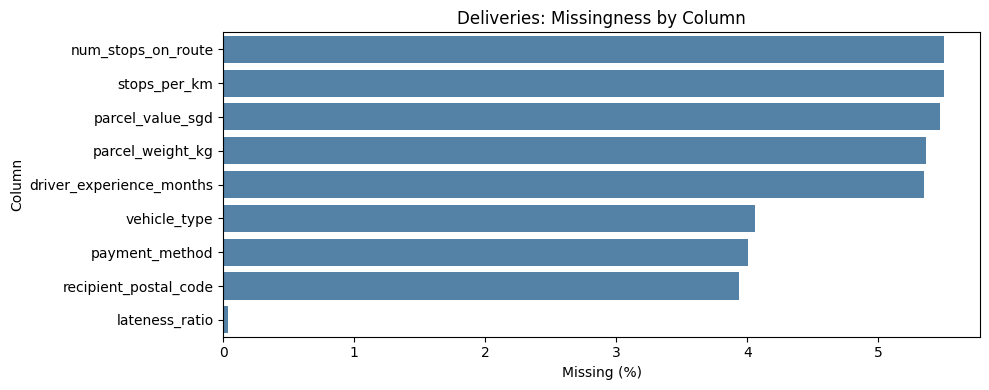

,missing_pct
num_stops_on_route,5.501333
stops_per_km,5.501333
parcel_value_sgd,5.473333
parcel_weight_kg,5.362000
driver_experience_months,5.346667
vehicle_type,4.058000
payment_method,4.002000
recipient_postal_code,3.939333
lateness_ratio,0.032667


In [43]:
plot_missingness_bar(deliveries, "Deliveries: Missingness by Column")

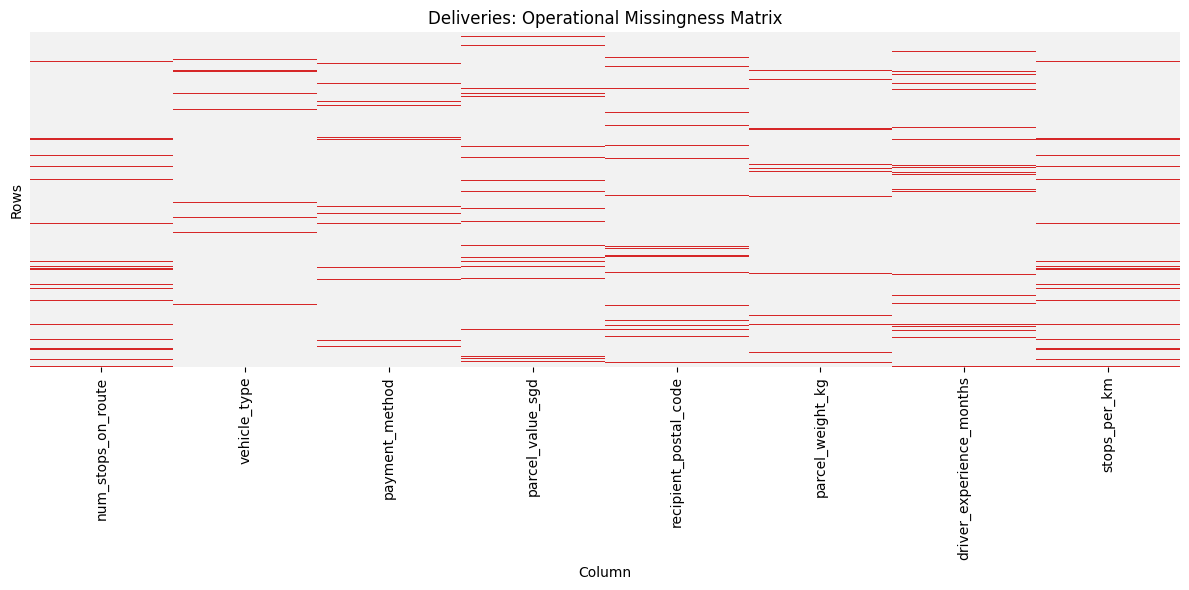

In [44]:
plot_missingness_matrix(
    deliveries,
    columns=operational_missing_cols,
    title="Deliveries: Operational Missingness Matrix"
)

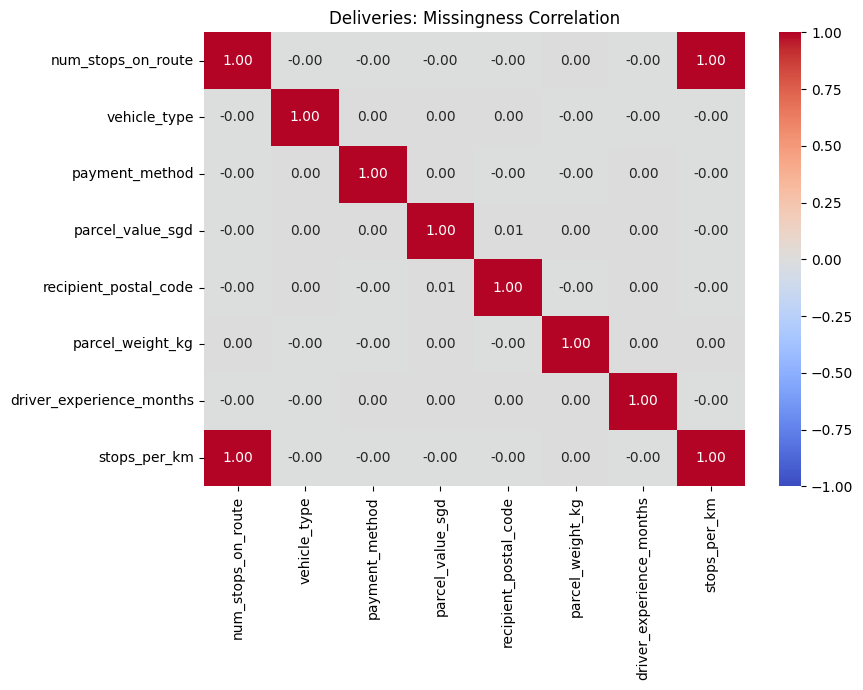

,num_stops_on_route,vehicle_type,payment_method,parcel_value_sgd,recipient_postal_code,parcel_weight_kg,driver_experience_months,stops_per_km
num_stops_on_route,1.000000,-0.003685,-0.000633,-0.002656,-0.004370,0.000847,-0.002366,1.000000
vehicle_type,-0.003685,1.000000,0.000931,0.004135,0.001253,-0.001858,-0.002321,-0.003685
payment_method,-0.000633,0.000931,1.000000,0.000215,-0.001482,-0.001190,0.002879,-0.000633
parcel_value_sgd,-0.002656,0.004135,0.000215,1.000000,0.007470,0.000362,0.002871,-0.002656
recipient_postal_code,-0.004370,0.001253,-0.001482,0.007470,1.000000,-0.002410,0.000010,-0.004370
parcel_weight_kg,0.000847,-0.001858,-0.001190,0.000362,-0.002410,1.000000,0.002232,0.000847
driver_experience_months,-0.002366,-0.002321,0.002879,0.002871,0.000010,0.002232,1.000000,-0.002366
stops_per_km,1.000000,-0.003685,-0.000633,-0.002656,-0.004370,0.000847,-0.002366,1.000000


In [45]:
plot_missingness_correlation(
    deliveries,
    columns=operational_missing_cols,
    title="Deliveries: Missingness Correlation"
)

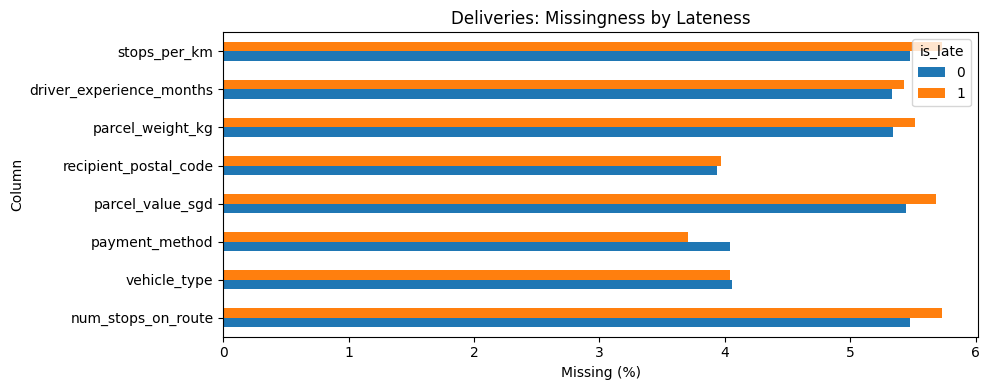

is_late,0,1
num_stops_on_route,5.472898,5.732174
vehicle_type,4.059933,4.042307
payment_method,4.038218,3.707981
parcel_value_sgd,5.447439,5.683545
recipient_postal_code,3.935634,3.969364
parcel_weight_kg,5.343357,5.513343
driver_experience_months,5.336618,5.428241
stops_per_km,5.472898,5.732174


In [46]:
plot_missingness_by_target(
    deliveries,
    columns=operational_missing_cols,
    target_col="is_late",
    title="Deliveries: Missingness by Lateness"
)

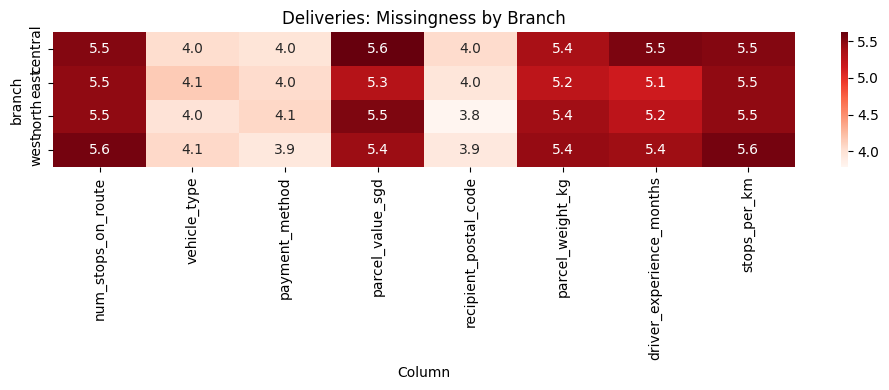

,num_stops_on_route,vehicle_type,payment_method,parcel_value_sgd,recipient_postal_code,parcel_weight_kg,driver_experience_months,stops_per_km
branch,,,,,,,,
central,5.508889,4.035556,3.971111,5.620000,4.044444,5.366667,5.540000,5.508889
east,5.466513,4.147379,4.043026,5.297942,3.954727,5.244428,5.145426,5.466513
north,5.463983,3.982637,4.070668,5.527730,3.788362,5.403272,5.248459,5.463983
west,5.564525,4.062392,3.932649,5.420367,3.929766,5.443432,5.405951,5.564525


In [47]:
plot_missingness_by_segment(
    deliveries,
    columns=operational_missing_cols,
    segment_col="branch",
    title="Deliveries: Missingness by Branch"
)

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Perform a first-pass missingness analysis on the `deliveries` table, which is the main modelling dataset.
- Identify which operational fields have missing values, whether missingness appears to occur together, and whether missingness differs by lateness outcome or branch.

##### B) Observations

- The missingness bar chart shows that missing values are concentrated in a small group of operational fields.
  - `stops_per_km` has the highest missingness at about 5.50% because it depends on `num_stops_on_route` and valid `distance_km`.
  - `parcel_value_sgd` and `parcel_weight_kg` have about 5.47% and 5.36% missingness respectively.
  - `num_stops_on_route`, `vehicle_type`, `payment_method`, `recipient_postal_code`, and `driver_experience_months` sit close together at about 3.91% to 4.07%.

- The missingness correlation heatmap suggests that most operational missingness indicators are close to uncorrelated.
  - Most pairwise correlations are near 0, so missingness does not appear to come from one single shared failure pattern across all fields.
  - The clear exception is `stops_per_km`, which is strongly correlated with missing `num_stops_on_route` because `stops_per_km` is derived from that column.

- Missingness rates are very similar between non-late and late deliveries.
  - Late deliveries have slightly higher missingness for `parcel_value_sgd`, `parcel_weight_kg`, `driver_experience_months`, and `stops_per_km`, but the differences are small.
  - This suggests missingness may carry some weak signal, but it is not obviously concentrated in late deliveries.

- Missingness by branch is also broadly stable.
  - All branches show similar missingness levels across the operational fields.
  - No branch stands out as having a severe missing-data problem, though small differences exist by field.

##### C) Conclusions

- The main delivery dataset is still usable for EDA and modelling because missingness is moderate and limited to operational support fields.
- Missingness does not appear to be strongly concentrated by target class or branch, so the current missingness pattern looks manageable rather than structurally biased toward one obvious operational segment.
- Missingness indicators should be kept because they preserve possible weak data-capture signal, even though the first-pass visuals do not show a very strong relationship with lateness.

##### D) Recommended Next Actions

- Keep the existing missingness flags for operational fields during later modelling and EDA.
- Impute missing numeric fields after EDA, using a model-appropriate strategy such as median imputation or tree models that can handle missingness.
- Treat `stops_per_km` carefully because its missingness is partly inherited from `num_stops_on_route`.
- Continue to segment-level EDA after this, especially checking lateness rates across `branch`, `delivery_priority`, `promised_service_tier`, `parcel_handling_sensitivity`, and high-volume clients.


<a id="sec-2-8"></a>

### Step 2.7 - Feature Stats 2.0

In [48]:
num_cols_deliveries = ["distance_km", "parcel_weight_kg" , "parcel_value_sgd", "num_stops_on_route", "driver_experience_months", "booking_to_pickup_mins" , "pickup_to_delivery_mins" , "booking_to_delivery_mins" , "delivery_lateness_mins", "promised_window_mins", "client_id_frequency", "stops_per_km", "delivery_priority_rank", "parcel_handling_sensitivity"]
cat_cols_deliveries = ["branch", "parcel_category", "delivery_priority", "vehicle_type", "payment_method", "recipient_postal_code", "has_num_stops_on_route" , "has_vehicle_type" , "has_payment_method" , "has_parcel_value_sgd" , "has_recipient_postal_code" , "has_parcel_weight_kg" , "has_driver_experience_months" , "is_late", "negative_duration_flag", "pickup_month", "pickup_hour", "pickup_day", "pickup_is_weekend", "delivery_priority_rank" ,  "parcel_handling_sensitivity", "promised_service_tier"]

num_cols_feedback = ["rating", "comment_length"]
cat_cols_feedback = ["rating", "has_rating",  "has_comment"]

num_cols_delivery_feedback = ["distance_km", "parcel_weight_kg" , "parcel_value_sgd", "num_stops_on_route", "driver_experience_months", "rating", "booking_to_pickup_mins" , "pickup_to_delivery_mins" , "booking_to_delivery_mins" , "delivery_lateness_mins", "delivery_to_feedback_mins", "comment_length", "promised_window_mins", "client_id_frequency", "stops_per_km", "delivery_priority_rank", "parcel_handling_sensitivity"]
cat_cols_delivery_feedback  = ["branch", "parcel_category", "delivery_priority", "vehicle_type", "payment_method", "recipient_postal_code", "rating" , "has_rating" , "has_num_stops_on_route" , "has_vehicle_type" , "has_payment_method", "has_parcel_value_sgd" , "has_recipient_postal_code" , "has_parcel_weight_kg" , "has_driver_experience_months", "has_feedback", "has_comment", "is_late", "negative_duration_flag" , "pickup_month", "pickup_hour", "pickup_day", "pickup_is_weekend", "delivery_priority_rank" , "parcel_handling_sensitivity", "promised_service_tier"]

In [49]:
num_summary_delivery_feedback, cat_summary_delivery_feedback = run_basic_profile(
    delivery_feedback,
    num_cols_delivery_feedback,
    cat_cols_delivery_feedback,
    dataset_name="Delivery Feedback"
)



 📊📊📊📊📊 DELIVERY FEEDBACK 📊📊📊📊📊

 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,65.02,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0
delivery_to_feedback_mins,54699.0,63.53,480.60949,475.784668,3.0,4.883,25.013333,139.116667,666.141667,1436.67,2257.168667,334.833333,3143.5,1.842,0.0,1.39
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
num_stops_on_route,141748.0,5.50,44.89202,16.823756,5.0,14.0,20.0,33.0,55.0,76.0,90.0,43.0,90.0,0.515,0.0,1.0
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
comment_length,150000.0,0.00,10.96794,18.906935,0.0,0.0,0.0,0.0,26.0,49.0,74.0,0.0,178.0,1.743,71.13,2.41



 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
delivery_to_feedback_mins,54699.0,63.53,480.60949,475.784668,3.0,4.883,25.013333,139.116667,666.141667,1436.67,2257.168667,334.833333,3143.5,1.842,0.0,1.39
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
comment_length,150000.0,0.00,10.96794,18.906935,0.0,0.0,0.0,0.0,26.0,49.0,74.0,0.0,178.0,1.743,71.13,2.41
parcel_handling_sensitivity,150000.0,0.00,0.46066,0.865242,0.0,0.0,0.0,0.0,1.0,2.0,3.0,0.0,3.0,1.652,74.92,1.0
delivery_priority_rank,150000.0,0.00,1.657833,0.851516,1.0,1.0,1.0,1.0,2.0,3.0,4.0,1.0,4.0,1.107,0.0,1.0



 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_handling_sensitivity,150000.0,0.00,0.46066,0.865242,0.0,0.0,0.0,0.0,1.0,2.0,3.0,0.0,3.0,1.652,74.92,1.0
comment_length,150000.0,0.00,10.96794,18.906935,0.0,0.0,0.0,0.0,26.0,49.0,74.0,0.0,178.0,1.743,71.13,2.41
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
rating,52476.0,65.02,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0
promised_window_mins,150000.0,0.00,235.325622,114.109458,-351.316667,32.033167,56.783333,138.479167,333.866667,412.35,428.066667,235.575,432.0,-0.032,0.0,1.01
pickup_to_delivery_mins,150000.0,0.00,226.090623,129.706948,-636.283333,5.0,33.3,121.8,326.770833,415.0,531.116833,224.35,1763.45,0.159,0.0,3.32
booking_to_pickup_mins,150000.0,0.00,114.382778,71.499723,6.016667,12.433333,22.7,56.233333,166.9,245.184167,260.816667,100.4,831.316667,0.704,0.0,3.19
client_id_frequency,150000.0,0.00,0.07482,0.076481,0.003513,0.003927,0.004387,0.0108,0.130413,0.205047,0.205047,0.0354,0.205047,0.792,0.0,1.0
delivery_priority_rank,150000.0,0.00,1.657833,0.851516,1.0,1.0,1.0,1.0,2.0,3.0,4.0,1.0,4.0,1.107,0.0,1.0



 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
pickup_to_delivery_mins,150000.0,0.00,226.090623,129.706948,-636.283333,5.0,33.3,121.8,326.770833,415.0,531.116833,224.35,1763.45,0.159,0.0,3.32
booking_to_pickup_mins,150000.0,0.00,114.382778,71.499723,6.016667,12.433333,22.7,56.233333,166.9,245.184167,260.816667,100.4,831.316667,0.704,0.0,3.19
booking_to_delivery_mins,150000.0,0.00,340.473401,163.325129,6.533333,32.149833,73.2325,211.633333,466.0,545.1675,659.017167,436.216667,1802.833333,-0.234,0.0,2.74
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
comment_length,150000.0,0.00,10.96794,18.906935,0.0,0.0,0.0,0.0,26.0,49.0,74.0,0.0,178.0,1.743,71.13,2.41
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4



 🟦🟦🟦 Categorical Variables stats 🟦🟦🟦 


,col,n_unique,missing_pct,top_category,top_pct
18,negative_duration_flag,2,0.00,0,99.68
14,has_driver_experience_months,2,0.00,1,96.09
13,has_parcel_weight_kg,2,0.00,1,96.08
12,has_recipient_postal_code,2,0.00,1,96.06
11,has_parcel_value_sgd,2,0.00,1,96.02
10,has_payment_method,2,0.00,1,96.00
9,has_vehicle_type,2,0.00,1,95.94
8,has_num_stops_on_route,2,0.00,1,95.93
22,pickup_is_weekend,2,0.00,0,91.53
17,is_late,2,0.00,0,89.03


In [50]:
num_summary_deliveries, cat_summary_deliveries = run_basic_profile(
    deliveries,
    num_cols_deliveries,
    cat_cols_deliveries,
    dataset_name="Deliveries"
)



 📊📊📊📊📊 DELIVERIES 📊📊📊📊📊

 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
num_stops_on_route,141748.0,5.50,44.89202,16.823756,5.0,14.0,20.0,33.0,55.0,76.0,90.0,43.0,90.0,0.515,0.0,1.0
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
parcel_handling_sensitivity,150000.0,0.00,0.46066,0.865242,0.0,0.0,0.0,0.0,1.0,2.0,3.0,0.0,3.0,1.652,74.92,1.0
delivery_priority_rank,150000.0,0.00,1.657833,0.851516,1.0,1.0,1.0,1.0,2.0,3.0,4.0,1.0,4.0,1.107,0.0,1.0
client_id_frequency,150000.0,0.00,0.07482,0.076481,0.003513,0.003927,0.004387,0.0108,0.130413,0.205047,0.205047,0.0354,0.205047,0.792,0.0,1.0



 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
parcel_handling_sensitivity,150000.0,0.00,0.46066,0.865242,0.0,0.0,0.0,0.0,1.0,2.0,3.0,0.0,3.0,1.652,74.92,1.0
delivery_priority_rank,150000.0,0.00,1.657833,0.851516,1.0,1.0,1.0,1.0,2.0,3.0,4.0,1.0,4.0,1.107,0.0,1.0
client_id_frequency,150000.0,0.00,0.07482,0.076481,0.003513,0.003927,0.004387,0.0108,0.130413,0.205047,0.205047,0.0354,0.205047,0.792,0.0,1.0
booking_to_pickup_mins,150000.0,0.00,114.382778,71.499723,6.016667,12.433333,22.7,56.233333,166.9,245.184167,260.816667,100.4,831.316667,0.704,0.0,3.19



 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_handling_sensitivity,150000.0,0.00,0.46066,0.865242,0.0,0.0,0.0,0.0,1.0,2.0,3.0,0.0,3.0,1.652,74.92,1.0
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
num_stops_on_route,141748.0,5.50,44.89202,16.823756,5.0,14.0,20.0,33.0,55.0,76.0,90.0,43.0,90.0,0.515,0.0,1.0
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
delivery_priority_rank,150000.0,0.00,1.657833,0.851516,1.0,1.0,1.0,1.0,2.0,3.0,4.0,1.0,4.0,1.107,0.0,1.0
client_id_frequency,150000.0,0.00,0.07482,0.076481,0.003513,0.003927,0.004387,0.0108,0.130413,0.205047,0.205047,0.0354,0.205047,0.792,0.0,1.0



 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.0,3.49,7.35,21.35,94.04,273.512,576.2561,44.66,5000.0,7.502,0.0,8.68
delivery_lateness_mins,150000.0,0.00,-9.234999,51.603956,-430.583333,-67.683333,-51.433333,-30.783333,-6.05,90.933333,205.033833,-17.3,1562.833333,3.4,0.02,7.62
stops_per_km,141748.0,5.50,10.139,6.711498,0.5,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.0,2.145,0.0,3.39
pickup_to_delivery_mins,150000.0,0.00,226.090623,129.706948,-636.283333,5.0,33.3,121.8,326.770833,415.0,531.116833,224.35,1763.45,0.159,0.0,3.32
booking_to_pickup_mins,150000.0,0.00,114.382778,71.499723,6.016667,12.433333,22.7,56.233333,166.9,245.184167,260.816667,100.4,831.316667,0.704,0.0,3.19
booking_to_delivery_mins,150000.0,0.00,340.473401,163.325129,6.533333,32.149833,73.2325,211.633333,466.0,545.1675,659.017167,436.216667,1802.833333,-0.234,0.0,2.74
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.05,0.184,0.337,0.815,2.747,6.573,12.12044,1.492,30.0,3.72,0.0,2.48
distance_km,150000.0,0.00,5.751599,3.387726,0.48,1.36,2.0,3.42,7.17,12.2,17.7101,4.95,30.0,1.838,0.0,1.69
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.0,2.0,3.0,7.0,23.0,50.0,86.0,13.0,120.0,2.541,0.05,1.4
promised_window_mins,150000.0,0.00,235.325622,114.109458,-351.316667,32.033167,56.783333,138.479167,333.866667,412.35,428.066667,235.575,432.0,-0.032,0.0,1.01



 🟦🟦🟦 Categorical Variables stats 🟦🟦🟦 


,col,n_unique,missing_pct,top_category,top_pct
14,negative_duration_flag,2,0.00,0,99.68
12,has_driver_experience_months,2,0.00,1,96.09
11,has_parcel_weight_kg,2,0.00,1,96.08
10,has_recipient_postal_code,2,0.00,1,96.06
9,has_parcel_value_sgd,2,0.00,1,96.02
8,has_payment_method,2,0.00,1,96.00
7,has_vehicle_type,2,0.00,1,95.94
6,has_num_stops_on_route,2,0.00,1,95.93
18,pickup_is_weekend,2,0.00,0,91.53
13,is_late,2,0.00,0,89.03


In [51]:
num_summary_feedback, cat_summary_feedback = run_basic_profile(
    feedback,
    num_cols_feedback,
    cat_cols_feedback,
    dataset_name="Feedback"
)



 📊📊📊📊📊 FEEDBACK 📊📊📊📊📊

 🟩🟩🟩 Numerical Variables stats 🟩🟩🟩 


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0
comment_length,54699.0,0.00,30.077168,20.137985,0.0,0.0,0.0,21.0,37.0,61.0,92.0,32.0,178.0,0.537,20.84,1.93



 🟩🟨🟩 Sorted by skew (Descending) 🟩🟨🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
comment_length,54699.0,0.00,30.077168,20.137985,0.0,0.0,0.0,21.0,37.0,61.0,92.0,32.0,178.0,0.537,20.84,1.93
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟩🟥🟩 Sorted by zero percentage (Descending) 🟩🟥🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
comment_length,54699.0,0.00,30.077168,20.137985,0.0,0.0,0.0,21.0,37.0,61.0,92.0,32.0,178.0,0.537,20.84,1.93
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟩9️⃣9️⃣🟩 Sorted by maximum over the 99th percentile (Descending) 🟩9️⃣9️⃣🟩


,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
comment_length,54699.0,0.00,30.077168,20.137985,0.0,0.0,0.0,21.0,37.0,61.0,92.0,32.0,178.0,0.537,20.84,1.93
rating,52476.0,4.06,4.300061,0.984949,1.0,1.0,2.0,4.0,5.0,5.0,5.0,5.0,5.0,-1.633,0.0,1.0



 🟦🟦🟦 Categorical Variables stats 🟦🟦🟦 


,col,n_unique,missing_pct,top_category,top_pct
1,has_rating,2,0.00,1,95.94
2,has_comment,2,0.00,1,79.16
0,rating,6,4.06,5,52.77


#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Re-profile the numerical and categorical features in `deliveries`, `delivery_feedback`, and `feedback` after the second round of feature engineering.
- Confirm distributions, skewness, zero-frequency, and category concentration for the new engineered features, and check for any remaining data-quality issues before deeper EDA and modelling.

##### B) Insights

- The profiling produced numerical summary tables (count, missingness, mean, percentiles, skew, zero percentage, and max-over-99th-percentile) and categorical summary tables (unique categories, missingness, dominant category, and dominant share) across all three tables.

- The target `is_late` is confirmed as imbalanced, with the non-late class dominating at about 89.03% and late deliveries at about 10.97%.
  - This level of imbalance means accuracy alone will be misleading, and recall, precision, F1, PR-AUC, and calibration will matter more.

- Several operational numeric features are strongly right-skewed.
  - `parcel_value_sgd` is the most extreme, with skew about 7.50, a maximum of 5000, and a max-over-99th-percentile of about 8.68.
  - `parcel_weight_kg` (skew about 3.72), `driver_experience_months` (skew about 2.52), and `distance_km` (skew about 1.84) are also right-skewed.
  - These long tails can distort linear models and distance-based methods, which creates an opportunity for transformations.

- Invalid placeholders are still present in two operational fields.
  - `num_stops_on_route` and `driver_experience_months` still show `-1` at their minimum and 1st percentile.
  - These are not valid operational values and must be treated as missing before final EDA and modelling.

- The engineered impact-weight features profile sensibly.
  - `delivery_priority_rank` is dominated by rank 1 (standard) at about 55.20%, with higher ranks forming smaller high-impact tiers.
  - `parcel_handling_sensitivity` is mostly 0 (standard) at about 74.92%, with a high zero percentage reflecting that most parcels are low-sensitivity.
  - `promised_service_tier` is dominated by same-day at about 69.21%, followed by 2-hour and next-day, giving a usable service-stringency signal.
  - `client_id_frequency` ranges from very small values up to about 0.205, confirming strong client concentration in a few high-volume clients.

- The pickup calendar features look clean and usable.
  - `pickup_hour`, `pickup_month`, and `pickup_day` are complete and reasonably spread, with no single value dominating heavily.
  - `pickup_is_weekend` is mostly 0 at about 91.53%, which is consistent with weekday-heavy operations.

- Some profiled features are leakage or target-derived and are shown only for EDA.
  - `delivery_lateness_mins` (skew about 3.4), `pickup_to_delivery_mins`, and `booking_to_delivery_mins` rely on `delivery_datetime`.
  - `pickup_to_delivery_mins` and `promised_window_mins` show negative minimums, which points to a small set of inconsistent timestamp rows rather than valid durations.

- The standalone `feedback` table confirms the feedback-availability story.
  - `rating` averages about 4.30 with negative skew about -1.63, so ratings are heavily positive and only about 4.06% missing within feedback itself.
  - `comment_length` has about 20.84% zero values, showing many feedback rows have no usable comment text.

##### C) Preprocessing Decisions

- Missingness sits at a manageable level (about 3.9% to 5.5%), so imputation plus flags preserves signal without dropping large portions of data.
- Apply skew-aware handling to highly skewed monetary and weight features.
  - The very high skew and max-over-99th-percentile for `parcel_value_sgd` and `parcel_weight_kg` justify `log1p` transformation and optional high-percentile capping.

##### D) Actionable Feature Engineering

- Apply `log1p` transformations to `parcel_value_sgd` and `parcel_weight_kg`, and consider it for `distance_km`, to reduce skew for linear and distance-based models.
- Retain the engineered impact-weight inputs (`delivery_priority_rank`, `parcel_handling_sensitivity`, `promised_service_tier`, `client_id_frequency`) for both lateness modelling and later impact-weight construction.
- Consider binning skewed or operational features into interpretable groups, such as short/medium/long `distance_km`, low/medium/high `parcel_value_sgd`, and low/medium/high `driver_experience_months`.
- Keep `negative_duration_flag` as a data-quality feature so inconsistent timestamp rows can be tracked or excluded later.

##### E) Actionable Model Development

- Use `deliveries` as the modelling base and predict `is_late` at pickup, excluding leakage features such as `delivery_lateness_mins`, `pickup_to_delivery_mins`, `booking_to_delivery_mins`, and all feedback-derived fields.
- Favour tree-based models such as Random Forest, Gradient Boosting, XGBoost, LightGBM, or HistGradientBoosting, since the data shows skewed numerics, categorical imbalance, missingness indicators, and likely non-linear interactions.
- Include a regularized logistic regression as an interpretable baseline after imputation, encoding, and transformation, to test whether complex models add value.
- Use stratified validation on `is_late` and emphasize PR-AUC, recall, precision, and F1, with probability calibration before threshold selection given the class imbalance and the higher cost of missed late deliveries.

##### F) Conclusions

- The second-round profiling confirms that engineered features are usable, the target is imbalanced at about 11% late
- These insights directly drive skew transformations, missingness handling, and retention of impact-weight inputs, while clearly separating leakage features from valid pickup-time predictors.
- They also confirm an imbalance-aware, calibration-focused modelling plan on `deliveries`, combining interpretable baselines with tree-based models evaluated using recall, precision, F1, and PR-AUC.


<a id="sec-3"></a>

# 3) Target variable distribution and class imbalance

Sections 3–13 below continue the EDA on the cleaned, feature-engineered tables produced in
Sections 1–2. The modelling base is **`deliveries`** (150,000 unique deliveries); the merged
**`delivery_feedback`** table is used only where customer-feedback fields are relevant.

Before profiling the target, the next cell fixes the **feature contracts** that govern the rest
of the analysis: which columns are *known at pickup* (legal model inputs) versus *leakage /
target-derived* (EDA-only). Making this explicit prevents accidental leakage when features are
later screened against the target.

In [52]:
# ----------------------------------------------------------------------
# Shared configuration + helpers used across Sections 3-13.
# These only read the already-built dataframes (deliveries / delivery_feedback / feedback).
# ----------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TARGET = "is_late"

# Features KNOWN AT OR BEFORE PICKUP -> legal model inputs.
PICKUP_NUM_FEATURES = [
    "distance_km", "parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route",
    "driver_experience_months", "booking_to_pickup_mins", "promised_window_mins",
    "client_id_frequency", "stops_per_km", "delivery_priority_rank",
    "parcel_handling_sensitivity", "pickup_hour", "pickup_month", "pickup_day",
]
PICKUP_CAT_FEATURES = [
    "branch", "parcel_category", "delivery_priority", "vehicle_type",
    "payment_method", "recipient_postal_code", "promised_service_tier",
    "pickup_is_weekend", "pickup_is_peakhour",
]
MISSING_FLAG_FEATURES = [
    "has_num_stops_on_route", "has_vehicle_type", "has_payment_method",
    "has_parcel_value_sgd", "has_recipient_postal_code", "has_parcel_weight_kg",
    "has_driver_experience_months",
]
# LEAKAGE / target-derived -> EDA ONLY, never fed to the pickup-time model.
LEAKAGE_FEATURES = [
    "delivery_datetime", "delivery_lateness_mins", "pickup_to_delivery_mins",
    "booking_to_delivery_mins", "delivery_to_feedback_mins", "lateness_ratio",
    "rating", "comment", "comment_length", "feedback_id", "feedback_datetime",
    "has_feedback", "has_comment", "has_rating",
]

def as_float(s):
    # Safe numeric cast: nullable Int / strings -> float64 with NaN.
    return pd.to_numeric(s, errors="coerce").astype("float64")

def feature_auc(x, y):
    # Rank-based AUC (= Mann-Whitney U) of one numeric feature vs the binary target.
    x = as_float(x).values
    m = ~np.isnan(x)
    x, yy = x[m], np.asarray(y)[m]
    n1 = yy.sum(); n0 = len(yy) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(x).rank().values
    return (r[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def cramers_v(a, b):
    # Bias-corrected Cramer's V between two categorical series.
    ct = pd.crosstab(a, b)
    n = ct.values.sum()
    if n == 0 or min(ct.shape) < 2:
        return 0.0
    row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
    exp = row @ col / n
    chi2 = ((ct.values - exp) ** 2 / exp).sum()
    r, k = ct.shape
    phi2c = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); kc = k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2c / denom)) if denom > 0 else 0.0

sns.set_theme(style="whitegrid")
print("Modelling base `deliveries` shape:", deliveries.shape)
print("Pickup-time numeric features :", len(PICKUP_NUM_FEATURES))
print("Pickup-time categorical feats:", len(PICKUP_CAT_FEATURES))
print("Leakage / EDA-only fields    :", len(LEAKAGE_FEATURES))

Modelling base `deliveries` shape: (150000, 43)
Pickup-time numeric features : 14
Pickup-time categorical feats: 9
Leakage / EDA-only fields    : 14


<a id="sec-3-1"></a>

### Step 3.1 - Target class distribution

      class  count  percent
0 = on-time 133549    89.03
   1 = late  16451    10.97

Imbalance ratio (on-time : late) = 8.12 : 1
Positive-class (late) prevalence  = 10.97%


C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3462217120.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="class", y="count", data=target_summary, ax=ax[0],


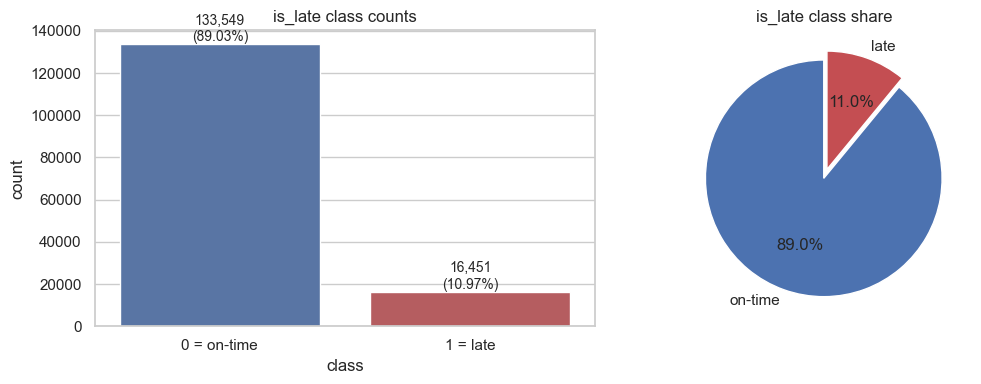

In [53]:
# Class counts, proportions and imbalance ratio for the binary target is_late.
counts = deliveries[TARGET].value_counts().sort_index()
props = deliveries[TARGET].value_counts(normalize=True).sort_index() * 100
imbalance_ratio = counts.loc[0] / counts.loc[1]

target_summary = pd.DataFrame({
    "class": ["0 = on-time", "1 = late"],
    "count": counts.values,
    "percent": props.round(2).values,
})
print(target_summary.to_string(index=False))
print(f"\nImbalance ratio (on-time : late) = {imbalance_ratio:.2f} : 1")
print(f"Positive-class (late) prevalence  = {props.loc[1]:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x="class", y="count", data=target_summary, ax=ax[0],
            palette=["#4C72B0", "#C44E52"])
for i, v in enumerate(target_summary["count"]):
    ax[0].text(i, v, f"{v:,}\n({target_summary['percent'][i]}%)",
               ha="center", va="bottom", fontsize=10)
ax[0].set_title("is_late class counts"); ax[0].set_ylabel("count")
ax[1].pie(counts.values, labels=["on-time", "late"], autopct="%1.1f%%",
          colors=["#4C72B0", "#C44E52"], startangle=90, explode=(0, 0.08))
ax[1].set_title("is_late class share")
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Quantify how the binary target `is_late` is distributed across its two classes and establish the degree of class imbalance that the downstream modelling and evaluation strategy must accommodate.

##### B) Insights

- The target is materially imbalanced: **133,549 on-time deliveries (89.03%)** versus **16,451 late deliveries (10.97%)**, an imbalance ratio of about **8.12 : 1**.
- The minority (late) class is the operationally important one, yet it represents only about one delivery in nine, so a naive classifier that always predicts "on-time" would already score ~89% accuracy while being useless for dispatch prioritisation.
- The skew is moderate rather than extreme (the positive class is not a rare <1% event), which means the signal is learnable, but headline accuracy will be a misleading success metric and threshold placement will matter.

##### C) Preprocessing Decisions

- All train/test partitioning will be **stratified on `is_late`** so the ~11% prevalence is preserved in every split and fold; this is justified by the 8:1 imbalance, which would otherwise yield folds with unstable positive counts.
- Probability calibration is anticipated because the model output is consumed as `P(late)` inside a risk × impact ranking rule, and imbalanced training data tends to produce poorly calibrated scores.

##### E) Actionable Model Development

- Evaluation will lead with **PR-AUC, recall, precision, F1 (macro/weighted) and balanced accuracy** rather than raw accuracy, because the imbalance makes accuracy near-trivial to game.
- Imbalance mitigation will be staged: begin with stratified splits plus threshold tuning, and escalate to **class weights** (and, only inside the CV pipeline, resampling such as SMOTE) if minority recall is insufficient.
- Because a missed late delivery (false negative) is costlier than a false alarm, the operating threshold will be chosen to favour recall on the late class, consistent with the business asymmetry stated in the brief.

##### F) Conclusions

- `is_late` is an imbalanced (~11% positive, 8:1) but learnable target; this single finding drives the choice of stratified validation, imbalance-aware metrics, probability calibration, and a recall-leaning operating threshold for the dispatch use case.

### 📋 Summary — Section 3

- The modelling target `is_late` is **imbalanced at ~10.97% positive (8.12 : 1)**, confirming that lateness is the minority but business-critical outcome the dispatch tool must surface.
- This imbalance anchors the modelling contract: **stratified splits + StratifiedKFold**, **PR-AUC / recall / F1 / balanced accuracy** as headline metrics, and **probability calibration** before threshold selection.
- Because false negatives (missed late deliveries) are costlier than false alarms, the eventual operating threshold and any class-weight / resampling choices will be tuned to protect **recall on the late class**, directly serving the objective of ranking the day's riskiest deliveries.

<a id="sec-4"></a>

# 4) Bias / imbalance checks (diagnosis)

This section diagnoses whether the ~11% late rate is **evenly spread** or **concentrated in
specific operational segments**, whether **missingness itself** carries target signal, and
whether any group has too little support to be trusted. These checks surface both modelling
opportunities (segments that separate the label) and risks (low-support groups, potential
leakage/shortcuts).

<a id="sec-4-1"></a>

### Step 4.1 — Label rate by operational subgroup

Baseline late rate = 10.97%


===== late rate by branch =====
             n  late_rate_%  lift_vs_base
branch                                   
east     37373        13.90          1.27
west     34684        11.91          1.09
north    32943        11.15          1.02
central  45000         7.67          0.70

===== late rate by parcel_category =====
                      n  late_rate_%  lift_vs_base
parcel_category                                   
refrigerated       6030        22.29          2.03
oversized         12161        18.38          1.68
fragile           19424        12.80          1.17
standard         112385         9.24          0.84

===== late rate by delivery_priority =====
                       n  late_rate_%  lift_vs_base
delivery_priority                                  
standard           82797        13.95          1.27
express            41758         8.32          0.76
premium            19418         6.18          0.56
vip                 6027         3

C:\Users\maano\AppData\Local\Temp\ipykernel_4220\2247854938.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=c, y="late_rate_%", data=t, ax=ax, palette="flare")
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\2247854938.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=c, y="late_rate_%", data=t, ax=ax, palette="flare")
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\2247854938.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=c, y="late_rate_%", data=t, ax=ax, palette="flare")
C:\Users\maano\AppData\Local\Temp\ipykernel_42

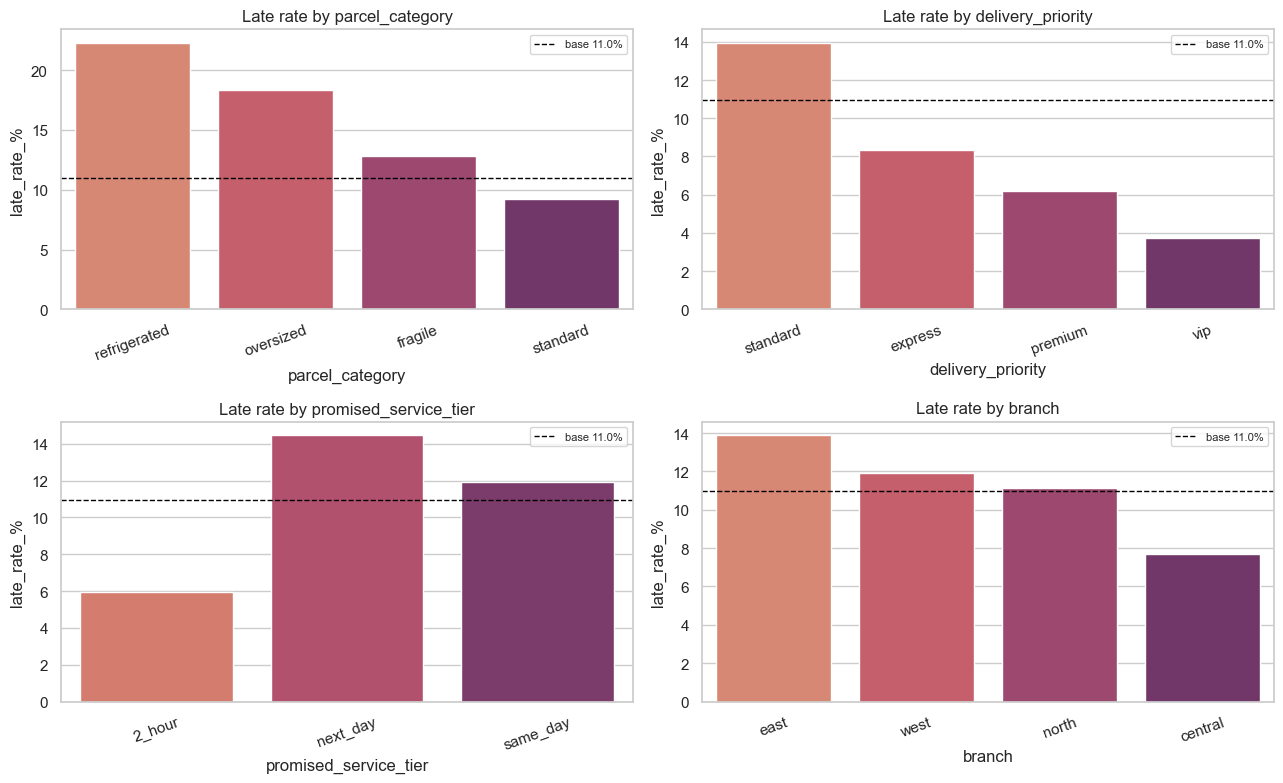

In [54]:
# Late-rate by each pickup-time categorical subgroup, with support counts.
def label_rate_table(df, col, target=TARGET):
    g = df.groupby(col, dropna=False)[target].agg(n="count", late_rate="mean")
    g["late_rate_%"] = (g["late_rate"] * 100).round(2)
    g["lift_vs_base"] = (g["late_rate"] / df[target].mean()).round(2)
    return g.drop(columns="late_rate").sort_values("late_rate_%", ascending=False)

base_rate = deliveries[TARGET].mean() * 100
print(f"Baseline late rate = {base_rate:.2f}%\n")
subgroup_cols = ["branch", "parcel_category", "delivery_priority", "vehicle_type",
                 "payment_method", "promised_service_tier",
                 "pickup_is_peakhour", "pickup_is_weekend"]
for c in subgroup_cols:
    print(f"\n===== late rate by {c} =====")
    print(label_rate_table(deliveries, c).to_string())

# Visual: ordered late-rate bars for the four strongest segment drivers.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), ["parcel_category", "delivery_priority",
                                "promised_service_tier", "branch"]):
    t = label_rate_table(deliveries, c).reset_index()
    sns.barplot(x=c, y="late_rate_%", data=t, ax=ax, palette="flare")
    ax.axhline(base_rate, ls="--", color="black", lw=1, label=f"base {base_rate:.1f}%")
    ax.set_title(f"Late rate by {c}"); ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Test whether lateness concentrates in particular operational subgroups (branch, parcel category, priority tier, service tier, vehicle, payment, time-of-day) relative to the 10.97% baseline, to expose both predictive structure and potential bias.

##### B) Insights

- **Parcel category** shows the widest spread: `refrigerated` is late **22.29%** of the time and `oversized` **18.38%**, versus only **9.24%** for `standard` — roughly a 2.4× lift for the riskiest handling class.
- **Delivery priority** moves counter-intuitively: `standard` is latest at **13.95%** while `vip` (3.73%) and `premium` (6.18%) are earliest, indicating MoveEasy already protects high-tier orders operationally — a strong, non-obvious signal for the model.
- **Promised service tier** separates cleanly: `next_day` (14.48%) and `same_day` (11.90%) miss far more than the tight `2_hour` window (5.96%), so looser promises paradoxically slip more often.
- **Branch** ranges from `central` (7.67%) to `east` (13.90%), a ~6pp operational gap worth a depot-level feature.
- **Vehicle type, payment method, weekend flag** are all within ~1pp of baseline (no meaningful separation); `pickup_is_peakhour` shows a mild lift (12.21% vs 10.38%).

##### D) Actionable Feature Engineering

- Retain `parcel_category`, `delivery_priority`, `promised_service_tier` and `branch` as primary categorical predictors; their large, ordered late-rate gaps justify one-hot or target encoding.
- Drop or down-weight `vehicle_type`, `payment_method` and `pickup_is_weekend` as standalone predictors given their negligible separation, while keeping the existing `parcel_handling_sensitivity` and `delivery_priority_rank` ordinal encodings that compress these signals.

##### E) Actionable Model Development

- The counter-intuitive priority effect (high tiers are *less* late) means linear models must include these categoricals explicitly; tree ensembles will capture the interaction automatically.
- Segment-level recall should be monitored for high-risk slices (refrigerated, oversized, next-day) since these are exactly the deliveries the dispatch tool exists to catch.

##### F) Conclusions

- Lateness is **structurally concentrated** in refrigerated/oversized parcels, standard-priority and next-/same-day promises, and the east depot; these segment gaps are the backbone of the predictive signal and directly shape the categorical encoding and segment-wise evaluation plan.

<a id="sec-4-2"></a>

### Step 4.2 — Label rate by missingness, low-support flags & leakage scan

In [55]:
# 4.2a Does missingness itself predict lateness? (missing-not-at-random check)
print("===== late rate by operational missingness flag =====")
miss_rows = []
for f in MISSING_FLAG_FEATURES:
    g = deliveries.groupby(f)[TARGET].mean() * 100
    n_missing = int((deliveries[f] == 0).sum())
    miss_rows.append({
        "flag": f, "n_missing": n_missing,
        "late%_when_missing": round(g.get(0, np.nan), 2),
        "late%_when_present": round(g.get(1, np.nan), 2),
        "gap_pp": round(g.get(0, np.nan) - g.get(1, np.nan), 2),
    })
miss_tbl = pd.DataFrame(miss_rows).sort_values("gap_pp", key=abs, ascending=False)
print(miss_tbl.to_string(index=False))

# 4.2b Low-support flag: categories with < 1% of rows are unreliable for naive estimates.
print("\n===== low-support categories (<1% of rows) =====")
MIN_SUPPORT = 0.01 * len(deliveries)
for c in ["parcel_category", "delivery_priority", "vehicle_type",
          "payment_method", "promised_service_tier", "recipient_postal_code"]:
    vc = deliveries[c].value_counts(dropna=False)
    rare = vc[vc < MIN_SUPPORT]
    if len(rare):
        print(f"{c}: {list(rare.index)}  (counts {list(rare.values)})")
    else:
        print(f"{c}: none below {int(MIN_SUPPORT)} rows")

# 4.2c Leakage / shortcut scan: any pickup-time feature with near-perfect target separation
#      (AUC -> 0 or 1) would signal leakage. Compare against known leakage fields as a control.
print("\n===== leakage / shortcut scan (AUC of numeric features vs is_late) =====")
scan = []
for c in PICKUP_NUM_FEATURES:
    scan.append((c, "pickup-time", round(feature_auc(deliveries[c], deliveries[TARGET]), 3)))
for c in ["delivery_lateness_mins", "pickup_to_delivery_mins", "lateness_ratio"]:
    if c in deliveries.columns:
        scan.append((c, "LEAKAGE(ctrl)", round(feature_auc(deliveries[c], deliveries[TARGET]), 3)))
scan_df = pd.DataFrame(scan, columns=["feature", "type", "AUC"])
scan_df["separation"] = (2 * (scan_df["AUC"] - 0.5)).abs().round(3)
print(scan_df.sort_values("separation", ascending=False).to_string(index=False))

===== late rate by operational missingness flag =====
                        flag  n_missing  late%_when_missing  late%_when_present  gap_pp
          has_payment_method       6003               10.16               11.00   -0.84
        has_parcel_weight_kg       5873               11.73               10.94    0.80
      has_num_stops_on_route       6106               11.45               10.95    0.50
has_driver_experience_months       5869               11.35               10.95    0.40
        has_parcel_value_sgd       5973               11.28               10.95    0.33
   has_recipient_postal_code       5909               11.05               10.96    0.09
            has_vehicle_type       6087               10.92               10.97   -0.04

===== low-support categories (<1% of rows) =====
parcel_category: none below 1500 rows
delivery_priority: none below 1500 rows
vehicle_type: none below 1500 rows
payment_method: none below 1500 rows
promised_service_tier: none below 1500 row

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Diagnose three failure modes before modelling: missingness that is informative about the target (MNAR), categories with too little support for stable estimates, and features that leak the outcome via near-perfect separation.

##### B) Insights

- **Missingness carries almost no target signal.** Across all seven operational `has_*` flags, the late rate when a field is missing versus present differs by under ~0.8pp (e.g. `has_parcel_weight_kg`: 11.73% missing vs 10.94% present). Missingness is therefore close to MAR, not a hidden shortcut.
- **No catastrophic low-support categories** appear among the core operational fields — every level of parcel category, priority, vehicle, payment and service tier clears the 1%-of-rows (1,500-row) threshold. `recipient_postal_code` (37 areas) is higher-cardinality but each area still has hundreds–thousands of rows.
- **Leakage scan is clean for pickup-time features:** the strongest legal feature, `num_stops_on_route`, reaches only AUC ≈ 0.63, far from the ≈1.0 separation produced by the control leakage fields (`delivery_lateness_mins`, `lateness_ratio`). No pickup-time feature behaves like a label proxy.

##### C) Preprocessing Decisions

- Because missingness is near-MAR, **median/mode or model-based imputation is safe** and the existing `has_*` flags can be **retained as low-cost insurance** rather than as strong predictors.
- The leakage controls confirm the pickup-time feature contract from Section 3 is correctly excluding outcome-derived fields; these EDA-only columns must stay out of any training matrix.

##### D) Actionable Feature Engineering

- Keep the missingness indicators but expect them to contribute little; revisit during feature selection in Section 12.
- Maintain `recipient_postal_code` as a moderate-cardinality categorical eligible for frequency or target encoding rather than naive one-hot, given 37 levels.

##### F) Conclusions

- The data shows **no MNAR shortcut, no fragile low-support category, and no pickup-time leakage**, so the imbalance is genuine operational signal rather than an artefact; this clears the way to safe imputation, standard encoding, and trustworthy feature-vs-target screening in Sections 5–7.

### 📋 Summary — Section 4

- Lateness is **not uniform**: it concentrates in refrigerated/oversized parcels, standard-priority orders, next-/same-day promises and the east depot — these segments form the core predictive signal and define the categorical encodings to keep.
- **Missingness is near-MAR** (≤~0.8pp target gap across all `has_*` flags), so imputation is safe and missing-indicators are retained only as weak insurance.
- **No low-support category** and **no pickup-time leakage** were found (strongest legal AUC ≈ 0.63 vs ≈1.0 for control leakage fields), confirming the feature contract is sound and the class imbalance reflects real operations — validating the move to detailed univariate and bivariate EDA next.

<a id="sec-5"></a>

# 5) Univariate EDA (numerical variables)

This section inspects each pickup-time **numeric** feature on its own — central tendency,
spread, skewness, zero-inflation and tail behaviour — using deeper tools than a plain
`describe()`: distribution profiles, histograms (raw + `log1p`), box/violin plots, QQ plots
against normality, and a consolidated multi-rule outlier scan (IQR, z-score, modified z-score,
percentile). The goal is to decide which transformations, scalers and outlier treatments each
feature needs before modelling.

<a id="sec-5-1"></a>

### Step 5.1 — Distribution profiles and histograms

,count,missing_pct,mean,std,min,1%,5%,25%,75%,95%,99%,median,max,skew,zero_pct,max_over_p99
stops_per_km,141748.0,5.50,10.139000,6.711498,0.500000,1.935028,3.015075,5.612999,12.734082,22.887948,34.229556,8.490566,116.000000,2.145,0.00,3.39
num_stops_on_route,141748.0,5.50,44.892020,16.823756,5.000000,14.000000,20.000000,33.000000,55.000000,76.000000,90.000000,43.000000,90.000000,0.515,0.00,1.00
parcel_value_sgd,141790.0,5.47,82.073384,125.528243,3.000000,3.490000,7.350000,21.350000,94.040000,273.512000,576.256100,44.660000,5000.000000,7.502,0.00,8.68
parcel_weight_kg,141957.0,5.36,2.236175,2.439544,0.050000,0.184000,0.337000,0.815000,2.747000,6.573000,12.120440,1.492000,30.000000,3.720,0.00,2.48
driver_experience_months,141980.0,5.35,17.946154,16.616376,0.000000,2.000000,3.000000,7.000000,23.000000,50.000000,86.000000,13.000000,120.000000,2.541,0.05,1.40
distance_km,150000.0,0.00,5.751599,3.387726,0.480000,1.360000,2.000000,3.420000,7.170000,12.200000,17.710100,4.950000,30.000000,1.838,0.00,1.69
parcel_handling_sensitivity,150000.0,0.00,0.460660,0.865242,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,3.000000,0.000000,3.000000,1.652,74.92,1.00
pickup_month,150000.0,0.00,4.632480,3.717585,1.000000,1.000000,1.000000,2.000000,5.000000,12.000000,12.000000,4.000000,12.000000,1.189,0.00,1.00
delivery_priority_rank,150000.0,0.00,1.657833,0.851516,1.000000,1.000000,1.000000,1.000000,2.000000,3.000000,4.000000,1.000000,4.000000,1.107,0.00,1.00
client_id_frequency,150000.0,0.00,0.074820,0.076481,0.003513,0.003927,0.004387,0.010800,0.130413,0.205047,0.205047,0.035400,0.205047,0.792,0.00,1.00


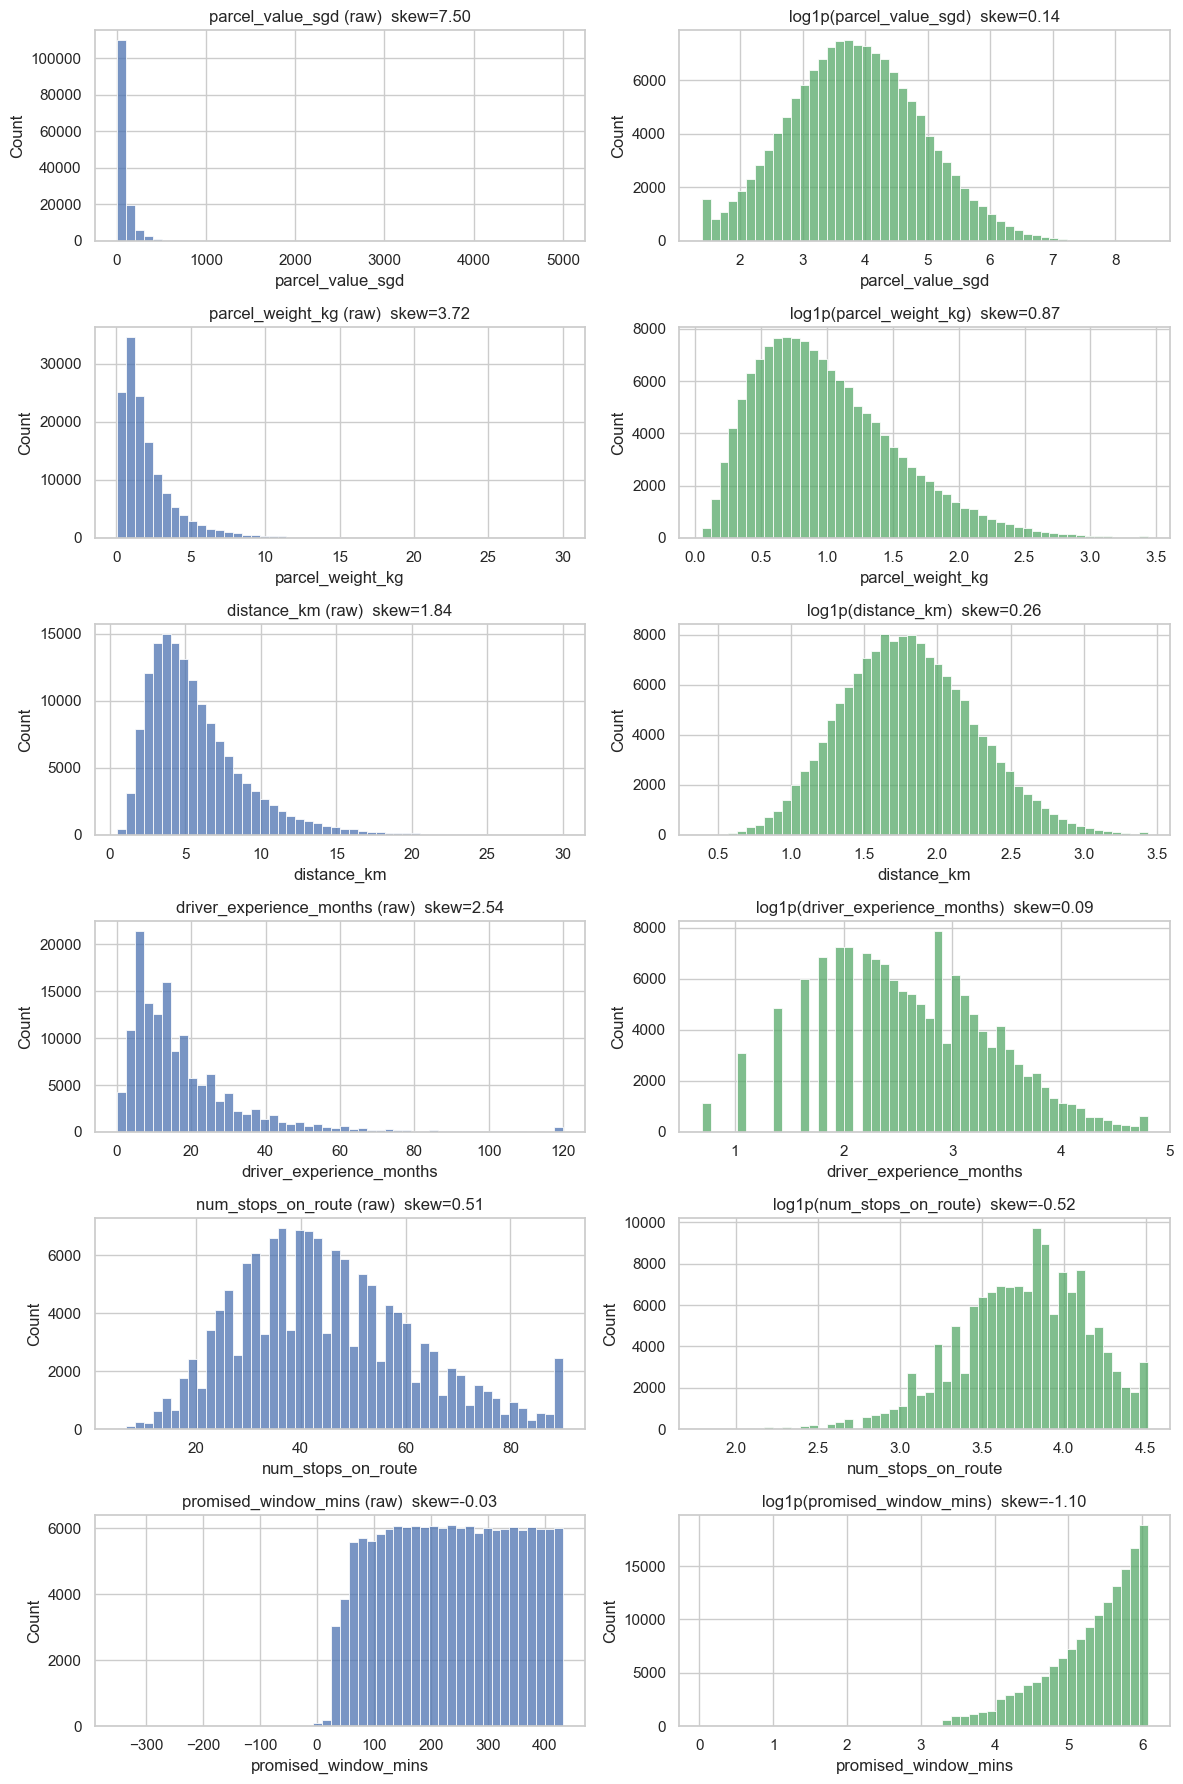

In [56]:
# Reuse the numeric_profile helper defined earlier (Section 2) on pickup-time numerics.
# Coerce nullable Int/Float columns to plain float64 first so skew/round are dtype-safe.
_num_df_s5 = deliveries[PICKUP_NUM_FEATURES].apply(as_float)
num_profile_s5 = numeric_profile(_num_df_s5, PICKUP_NUM_FEATURES)
display(num_profile_s5)

# Histogram grid: raw distribution + log1p view for the right-skewed monetary/size features.
skewed = ["parcel_value_sgd", "parcel_weight_kg", "distance_km",
          "driver_experience_months", "num_stops_on_route", "promised_window_mins"]
fig, axes = plt.subplots(len(skewed), 2, figsize=(12, 3 * len(skewed)))
for row, col in zip(axes, skewed):
    x = as_float(deliveries[col]).dropna()
    sns.histplot(x, bins=50, ax=row[0], color="#4C72B0")
    row[0].set_title(f"{col} (raw)  skew={x.skew():.2f}")
    xpos = x[x > 0]
    sns.histplot(np.log1p(xpos), bins=50, ax=row[1], color="#55A868")
    row[1].set_title(f"log1p({col})  skew={np.log1p(xpos).skew():.2f}")
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Characterise the marginal distribution of every pickup-time numeric feature (shape, skew, zero-inflation, tail heaviness) to decide on transformations and scaling.

##### B) Insights

- **`parcel_value_sgd` is extremely right-skewed** (skew ≈ 7.5, median ≈ 44 SGD, 99th pct ≈ 576, max 5,000): a thin tail of high-value parcels dominates the mean. `log1p` collapses this skew dramatically toward ~0, confirming a log transform is appropriate.
- **`parcel_weight_kg`** (skew ≈ 3.7) and **`distance_km`** (skew ≈ 1.84) are similarly right-skewed; both normalise well under `log1p`.
- **`driver_experience_months`** (skew ≈ 2.5, median 13 months, max 120) is right-skewed, indicating a young fleet with a long experienced tail — a plausible non-linear driver of reliability.
- **`num_stops_on_route`** (skew ≈ 0.5, range 5–90) and **`promised_window_mins`** (near-symmetric, skew ≈ 0) are well-behaved and need no transform.
- `promised_window_mins` shows a **negative minimum (≈ −351)**, a data-quality artefact (promise earlier than pickup) to be flagged in Section 10.

##### C) Preprocessing Decisions

- Apply **`log1p`** to `parcel_value_sgd`, `parcel_weight_kg` and `distance_km` for linear / distance-based models; tree ensembles can use raw values since they are scale-invariant.
- Use **robust scaling (median/IQR)** rather than standardisation for the skewed monetary and weight features so extreme tails do not dominate.

##### D) Actionable Feature Engineering

- Create `log1p`-transformed versions of the three skewed features in Section 12, and consider quantile **binning** (low/med/high) of `parcel_value_sgd` and `driver_experience_months` to expose threshold effects to linear models.

##### F) Conclusions

- The numeric features split into a **heavy-tailed monetary/size group** needing log transforms and robust scaling, and a **well-behaved operational group** (stops, window, calendar) needing none; this directly seeds the transformation list for feature engineering and motivates tree models that tolerate the residual skew.

<a id="sec-5-2"></a>

### Step 5.2 — Box/violin, QQ plots and multi-rule outlier scan

C:\Users\maano\AppData\Local\Temp\ipykernel_4220\2100065320.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET, y=as_float(deliveries[col]), data=deliveries, ax=row[0],
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\2100065320.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET, y=as_float(deliveries[col]), data=deliveries, ax=row[0],
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\2100065320.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET, y=as_float(deliveries[col]), data=deliveries, ax=row[0],
C:\User

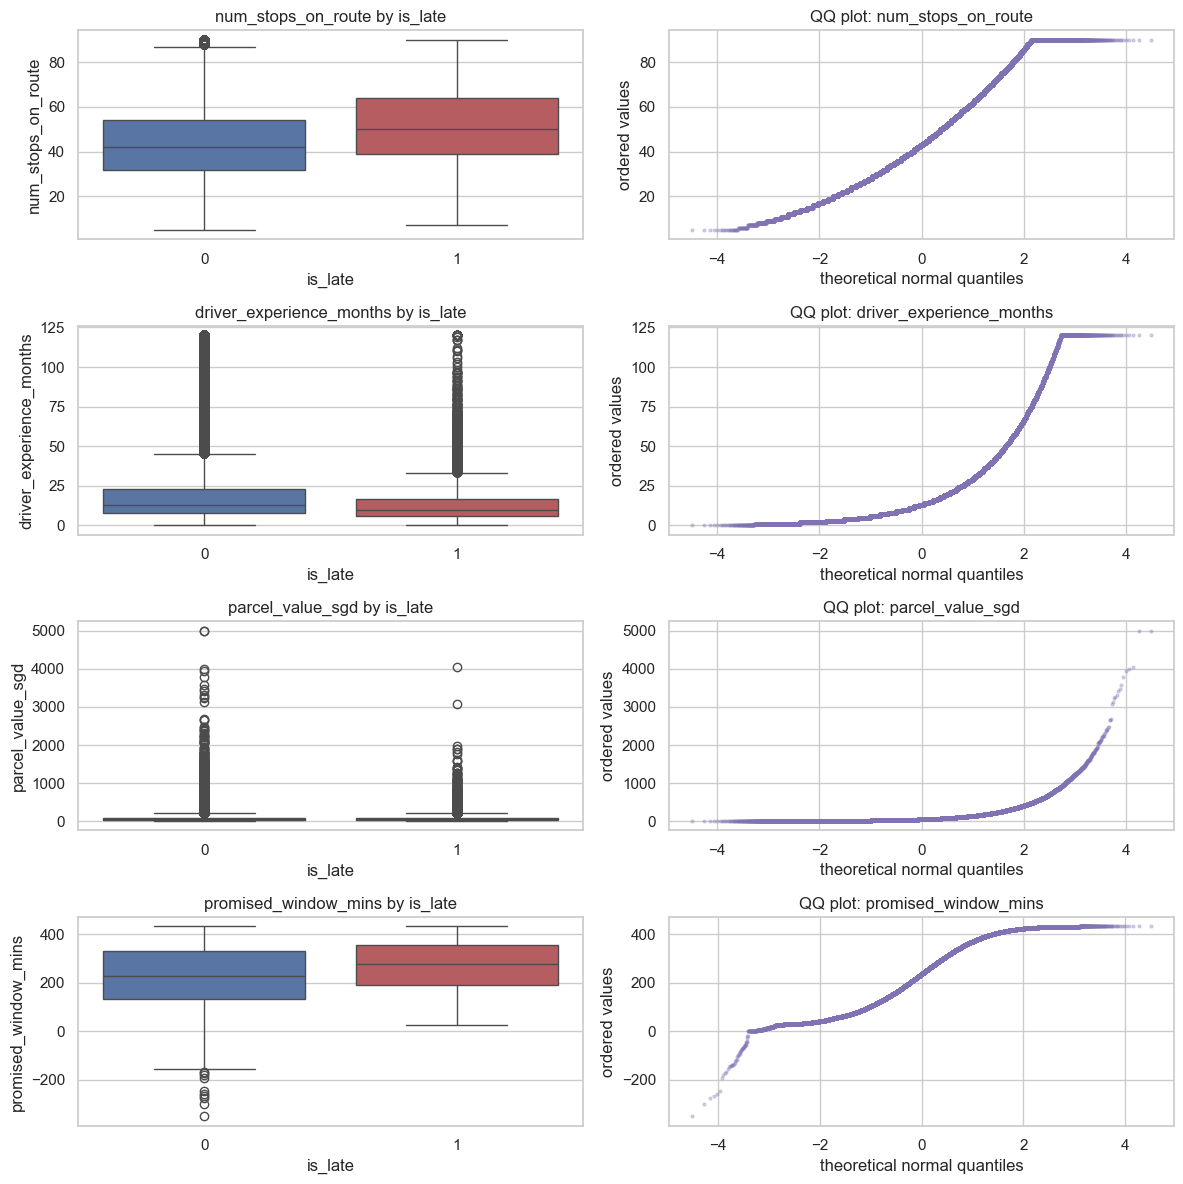

===== multi-rule outlier counts (pickup-time numerics) =====


,feature,n,IQR_1.5,z>3,modz>3.5,pct_0.5/99.5,IQR_%
12,pickup_month,150000,27871,0,0,0,18.58
2,parcel_value_sgd,141790,12117,2428,13139,709,8.55
1,parcel_weight_kg,141957,9936,2783,9535,1419,7.00
4,driver_experience_months,141980,7949,3087,7220,769,5.60
8,stops_per_km,141748,6550,2457,4561,1418,4.62
0,distance_km,150000,6260,2453,4158,1490,4.17
10,parcel_handling_sensitivity,150000,6030,0,0,0,4.02
9,delivery_priority_rank,150000,6027,0,0,0,4.02
3,num_stops_on_route,141748,2454,0,0,631,1.73
11,pickup_hour,150000,435,87,53,435,0.29


In [57]:
# QQ helper: numpy normal-quantile fallback (Acklam ppf) so no scipy dependency is required.
def _norm_ppf(p):
    a = [-3.969683028665376e+01, 2.209460984245205e+02, -2.759285104469687e+02,
         1.383577518672690e+02, -3.066479806614716e+01, 2.506628277459239e+00]
    b = [-5.447609879822406e+01, 1.615858368580409e+02, -1.556989798598866e+02,
         6.680131188771972e+01, -1.328068155288572e+01]
    c = [-7.784894002430293e-03, -3.223964580411365e-01, -2.400758277161838e+00,
         -2.549732539343734e+00, 4.374664141464968e+00, 2.938163982698783e+00]
    d = [7.784695709041462e-03, 3.224671290700398e-01, 2.445134137142996e+00,
         3.754408661907416e+00]
    p = np.asarray(p, float); out = np.empty_like(p)
    lo, hi = p < 0.02425, p > 1 - 0.02425; mid = ~(lo | hi)
    ql = np.sqrt(-2 * np.log(p[lo]))
    out[lo] = (((((c[0]*ql+c[1])*ql+c[2])*ql+c[3])*ql+c[4])*ql+c[5]) / ((((d[0]*ql+d[1])*ql+d[2])*ql+d[3])*ql+1)
    qh = np.sqrt(-2 * np.log(1 - p[hi]))
    out[hi] = -(((((c[0]*qh+c[1])*qh+c[2])*qh+c[3])*qh+c[4])*qh+c[5]) / ((((d[0]*qh+d[1])*qh+d[2])*qh+d[3])*qh+1)
    qm = p[mid] - 0.5; r = qm*qm
    out[mid] = (((((a[0]*r+a[1])*r+a[2])*r+a[3])*r+a[4])*r+a[5])*qm / (((((b[0]*r+b[1])*r+b[2])*r+b[3])*r+b[4])*r+1)
    return out

def qq_points(x):
    x = np.sort(as_float(x).dropna().values)
    n = len(x)
    probs = (np.arange(1, n + 1) - 0.5) / n
    return _norm_ppf(probs), x

# Box (by class) + QQ for the most informative / skewed features.
focus = ["num_stops_on_route", "driver_experience_months",
         "parcel_value_sgd", "promised_window_mins"]
fig, axes = plt.subplots(len(focus), 2, figsize=(12, 3 * len(focus)))
for row, col in zip(axes, focus):
    sns.boxplot(x=TARGET, y=as_float(deliveries[col]), data=deliveries, ax=row[0],
                palette=["#4C72B0", "#C44E52"])
    row[0].set_title(f"{col} by is_late"); row[0].set_xlabel("is_late"); row[0].set_ylabel(col)
    tq, sq = qq_points(deliveries[col])
    row[1].scatter(tq, sq, s=4, alpha=0.3, color="#8172B3")
    row[1].set_title(f"QQ plot: {col}")
    row[1].set_xlabel("theoretical normal quantiles"); row[1].set_ylabel("ordered values")
plt.tight_layout(); plt.show()

# Consolidated outlier scan: count flags from four rules per feature.
def outlier_scan(df, cols):
    rows = []
    for c in cols:
        x = as_float(df[c]).dropna()
        if len(x) == 0:
            continue
        q1, q3 = x.quantile(.25), x.quantile(.75); iqr = q3 - q1
        iqr_n = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
        z = (x - x.mean()) / x.std(ddof=0)
        z_n = int((z.abs() > 3).sum())
        med = x.median(); mad = (x - med).abs().median()
        mz = 0.6745 * (x - med) / mad if mad else pd.Series(0, index=x.index)
        mz_n = int((mz.abs() > 3.5).sum())
        pct_n = int(((x < x.quantile(.005)) | (x > x.quantile(.995))).sum())
        rows.append({"feature": c, "n": len(x),
                     "IQR_1.5": iqr_n, "z>3": z_n, "modz>3.5": mz_n, "pct_0.5/99.5": pct_n,
                     "IQR_%": round(100 * iqr_n / len(x), 2)})
    return pd.DataFrame(rows).sort_values("IQR_%", ascending=False)

print("===== multi-rule outlier counts (pickup-time numerics) =====")
display(outlier_scan(deliveries, PICKUP_NUM_FEATURES))

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Assess departures from normality (QQ), class-conditional spread (box-by-target), and quantify outlier prevalence under four complementary rules to choose detection thresholds and treatment per feature.

##### B) Insights

- The **QQ plots confirm heavy right tails** for `parcel_value_sgd`, `driver_experience_months` and (mildly) `num_stops_on_route`: ordered values bend sharply above the normal line at the top end, so normality-based (z-score) flagging will over-count on these.
- **Box-by-target plots** show the late class sitting at higher `num_stops_on_route` and lower `driver_experience_months`, visually echoing the AUC signal from Section 4 — busy routes and inexperienced drivers run later.
- The **multi-rule scan** shows `parcel_value_sgd` flags the most extreme points, while symmetric features like `promised_window_mins` flag very few. Modified-z (median/MAD) flags fewer points than plain z on skewed columns, confirming it is the more robust rule here.

##### C) Preprocessing Decisions

- Prefer the **IQR and modified-z (MAD) rules over plain z-score** for the skewed monetary/size features, because their tails inflate the mean/SD and cause z to mis-flag.
- Treat extremes by **winsorising at the 0.5/99.5 percentiles** (or `log1p`) rather than dropping rows, since high-value/heavy parcels are legitimate operational events, not errors — only the invalid `promised_window_mins` negatives warrant correction.

##### D) Actionable Feature Engineering

- Carry the chosen `log1p` transforms forward (they double as outlier compression), and add winsorised variants of `parcel_value_sgd`/`parcel_weight_kg` for linear models in Section 12.

##### E) Actionable Model Development

- Favour **tree-based ensembles and RobustScaler-fronted linear models**, both tolerant of the residual heavy tails, over plain standardised linear models that the QQ evidence shows would be distorted.

##### F) Conclusions

- Normality clearly fails for the monetary/size features, so robust (IQR/MAD) detection plus winsorise-or-log treatment is adopted, while well-behaved operational features pass through untouched — decisions that feed directly into the Section 10 outlier workflow and the Section 12 transformation list.

### 📋 Summary — Section 5

- Pickup-time numerics fall into two groups: a **heavy-tailed monetary/size group** (`parcel_value_sgd` skew ≈ 7.5, `parcel_weight_kg` ≈ 3.7, `distance_km` ≈ 1.84, `driver_experience_months` ≈ 2.5) that needs `log1p` + robust scaling, and a **well-behaved operational group** (`num_stops_on_route`, `promised_window_mins`, calendar parts) that needs none.
- QQ and multi-rule outlier evidence show **normality fails on the skewed group**, so IQR / modified-z detection and winsorise-or-log treatment are preferred over z-score and row-dropping; legitimate extremes are kept.
- Box-by-target views already hint that **higher stop counts and lower driver experience track lateness**, foreshadowing the feature-vs-target analysis and justifying tree ensembles / RobustScaler-fronted linear baselines.

<a id="sec-6"></a>

# 6) Univariate EDA (categorical variables)

Here each pickup-time **categorical** feature is profiled for general trends, class imbalance,
and its raw association with `is_late`. Each feature is shown as a count distribution alongside
its per-category late rate, so dominance and target-separation are visible together.

<a id="sec-6-1"></a>

### Step 6.1 — Category distributions and target association

,col,n_unique,missing_pct,top_category,top_pct
6,pickup_is_weekend,2,0.00,0,91.53
4,payment_method,3,4.00,prepaid,84.39
1,parcel_category,4,0.00,standard,74.92
5,promised_service_tier,3,0.00,same_day,69.21
7,pickup_is_peakhour,2,0.00,0,67.86
3,vehicle_type,4,4.06,van,55.70
2,delivery_priority,4,0.00,standard,55.20
0,branch,4,0.00,central,30.00
8,recipient_postal_code,38,3.94,22,4.46


C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with


===== categorical association with is_late (Cramer's V) =====
              feature  cramers_v  n_unique
      parcel_category      0.112         4
    delivery_priority      0.110         4
promised_service_tier      0.084         3
               branch      0.076         4
recipient_postal_code      0.072        38
   pickup_is_peakhour      0.027         2
       payment_method      0.004         3
         vehicle_type      0.000         4
    pickup_is_weekend      0.000         2


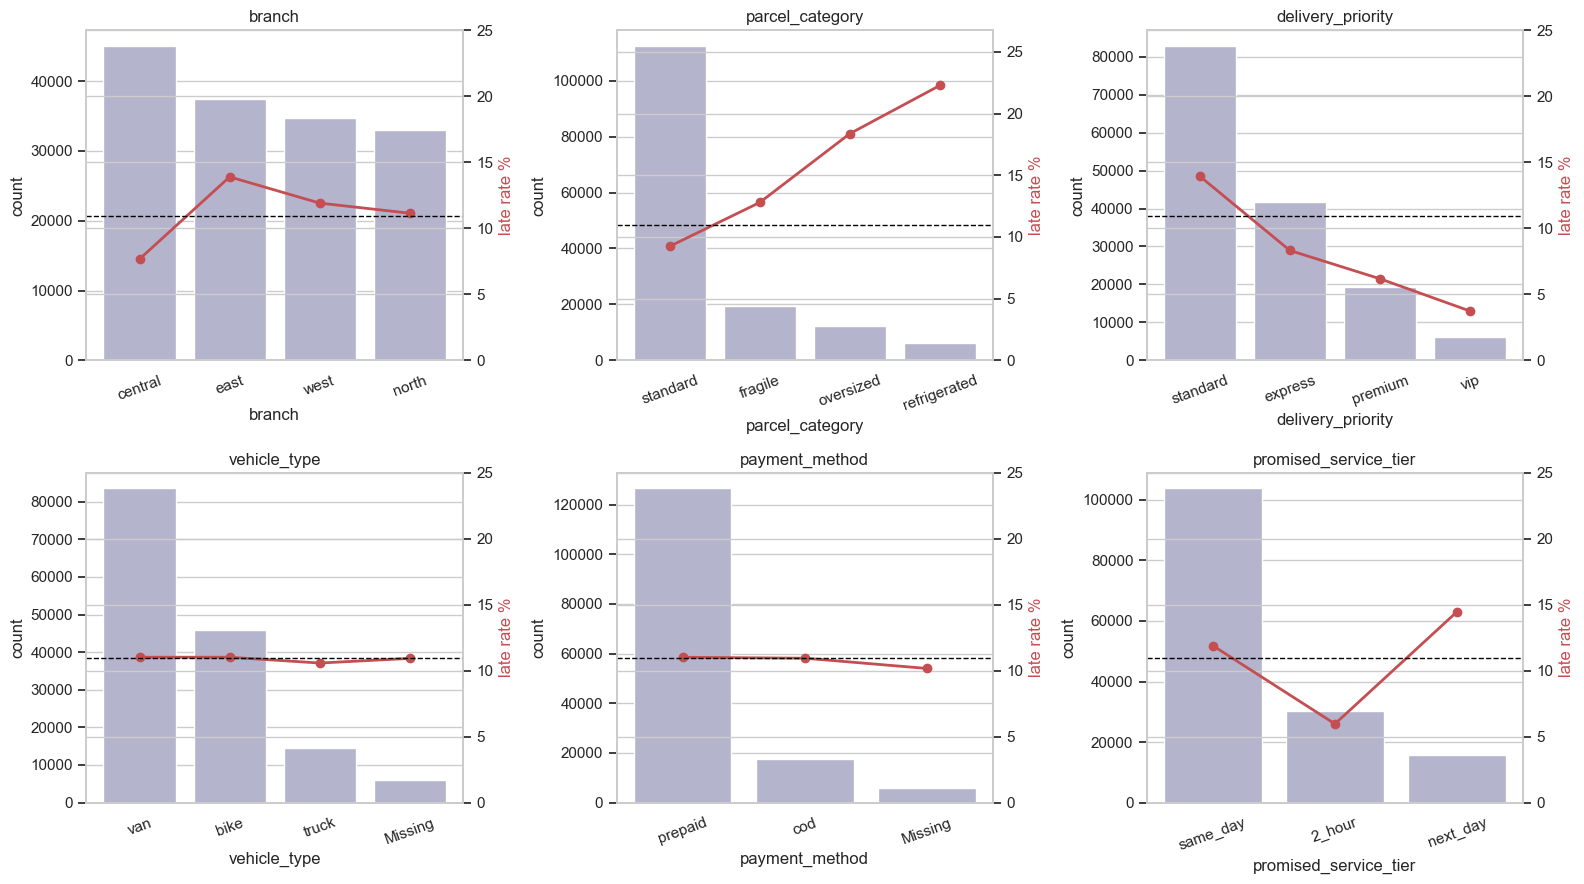

In [58]:
# Profile cardinality / dominance for each categorical, then plot counts + late-rate overlay.
cat_cols_s6 = ["branch", "parcel_category", "delivery_priority", "vehicle_type",
               "payment_method", "promised_service_tier", "pickup_is_weekend",
               "pickup_is_peakhour", "recipient_postal_code"]

prof = categorical_profile(deliveries, cat_cols_s6)
display(prof)

# Cramer's V of each categorical vs target -> single association score.
assoc = pd.DataFrame({
    "feature": cat_cols_s6,
    "cramers_v": [round(cramers_v(deliveries[c].astype("string").fillna("<NA>"),
                                  deliveries[TARGET]), 3) for c in cat_cols_s6],
    "n_unique": [deliveries[c].nunique(dropna=False) for c in cat_cols_s6],
}).sort_values("cramers_v", ascending=False)
print("\n===== categorical association with is_late (Cramer's V) =====")
print(assoc.to_string(index=False))

# Count + late-rate dual plots for the lower-cardinality drivers.
plot_cols = ["branch", "parcel_category", "delivery_priority",
             "vehicle_type", "payment_method", "promised_service_tier"]
base_rate = deliveries[TARGET].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), plot_cols):
    # Treat missing values as an explicit "Missing" category so the missing group stays visible.
    s = deliveries[c].astype("string").fillna("Missing")
    order = list(s.value_counts().index)
    sns.countplot(x=s, order=order, ax=ax, color="#B0B0D0")
    ax.tick_params(axis="x", rotation=20); ax.set_title(f"{c}")
    ax2 = ax.twinx()
    rate = deliveries.assign(_g=s).groupby("_g", observed=True)[TARGET].mean().reindex(order) * 100
    ax2.plot(range(len(order)), rate.values, "o-", color="#C44E52", lw=2)
    ax2.axhline(base_rate, ls="--", color="black", lw=1)
    ax2.set_ylabel("late rate %", color="#C44E52")
    ax2.set_ylim(0, max(25, float(np.nanmax(rate.values)) * 1.2))
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Profile the distribution and dominance of each categorical feature and quantify its univariate association with lateness (Cramér's V) to decide encoding and which categoricals carry signal.

##### B) Insights

- **Strong class imbalance within several categoricals:** `payment_method` is 84% prepaid, `parcel_category` 75% standard, `vehicle_type` 56% van, `delivery_priority` 55% standard. Minority levels (COD, refrigerated, truck, VIP) are small but operationally important.
- **`branch` is the most balanced** categorical (top level `central` ≈ 30%), making it well suited to clean segment comparison.
- **Association ranking (Cramér's V):** `parcel_category` (0.112) and `delivery_priority` (0.110) lead, followed by `promised_service_tier` (0.084) and `branch` (0.076). `pickup_is_peakhour` is weak (0.027); `payment_method`, `vehicle_type` and `pickup_is_weekend` are effectively null (≤ 0.004).
- **`recipient_postal_code`** has 37 levels with no single dominant area, a moderate-cardinality field requiring smarter encoding than one-hot.

##### C) Preprocessing Decisions

- **One-hot encode** the low-cardinality, higher-signal categoricals (`parcel_category`, `delivery_priority`, `promised_service_tier`, `branch`).
- **Frequency- or target-encode** `recipient_postal_code` (37 levels) to avoid one-hot blow-up, with smoothing and an explicit "Unseen/Other" bucket for deployment robustness.
- Drop or retain-with-low-expectation the near-null categoricals (`vehicle_type`, `payment_method`, `pickup_is_weekend`).

##### D) Actionable Feature Engineering

- The existing ordinal encodings `delivery_priority_rank` and `parcel_handling_sensitivity` compress two of the strongest categoricals into compact monotone features — keep them for linear models.
- Add an "Other" collapse policy for rare categories and unseen postal areas to keep encodings stable in production.

##### F) Conclusions

- Categorical signal is concentrated in **parcel category, priority and service tier**, with branch as a useful balanced segment; this dictates one-hot for the strong low-cardinality fields, target/frequency encoding for postal code, and de-prioritisation of the near-null categoricals.

### 📋 Summary — Section 6

- Categorical predictive signal is led by **`parcel_category` and `delivery_priority` (Cramér's V ≈ 0.11)**, then `promised_service_tier` and `branch`; `vehicle_type`, `payment_method` and weekend flags are effectively uninformative.
- Several categoricals are **highly dominated by one level** (prepaid 84%, standard parcels 75%), so minority but high-risk levels must be preserved and monitored, not averaged away.
- Encoding plan: **one-hot** the strong low-cardinality fields, **target/frequency-encode** the 37-level `recipient_postal_code` with an Unseen bucket, and lean on the existing ordinal `*_rank` / `*_sensitivity` features — directly feeding the feature-engineering and modelling design.

<a id="sec-7"></a>

# 7) Bivariate EDA (Feature ↔ Target)

This section quantifies how well each pickup-time feature **separates** `is_late = 0` from
`is_late = 1`. It follows a three-layer structure: a quick context recap (Layer 0), a wide
scan of every feature with mostly tables (Layer 1), and focused deep dives on the shortlisted
strongest / riskiest features (Layer 2). The output is a ranked sense of predictive value plus
concrete preprocessing, encoding and modelling decisions.

<a id="sec-7-1"></a>

### Layer 0 — Quick context

In [59]:
# Reconfirm the target distribution and state the evaluation implications it forces.
n = len(deliveries); pos = int(deliveries[TARGET].sum()); neg = n - pos
print(f"is_late distribution: {neg:,} on-time ({neg/n:.2%}) | {pos:,} late ({pos/n:.2%})")
print(f"Imbalance ratio (neg:pos) = {neg/pos:.2f} : 1\n")
print("Evaluation implications (carried through all of Section 7):")
print("  - Use Stratified train/test split + StratifiedKFold (preserve ~11% positives).")
print("  - Lead metrics: PR-AUC, F1 (macro/weighted), balanced accuracy, recall@late.")
print("  - Accuracy alone is misleading: an all-on-time baseline already scores ~89%.")
print("  - Calibrate P(late) before threshold selection (score feeds risk x impact rule).")

is_late distribution: 133,549 on-time (89.03%) | 16,451 late (10.97%)
Imbalance ratio (neg:pos) = 8.12 : 1

Evaluation implications (carried through all of Section 7):
  - Use Stratified train/test split + StratifiedKFold (preserve ~11% positives).
  - Lead metrics: PR-AUC, F1 (macro/weighted), balanced accuracy, recall@late.
  - Accuracy alone is misleading: an all-on-time baseline already scores ~89%.
  - Calibrate P(late) before threshold selection (score feeds risk x impact rule).


#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Re-anchor the bivariate analysis on the target's imbalance and translate it into the validation and metric rules that every subsequent separation result must be read against.

##### B) Insights

- The recap confirms the ~10.97% positive rate and 8.12:1 imbalance, so a trivial all-on-time classifier scores ~89% accuracy — accuracy is therefore disqualified as a primary metric.
- Because the score is consumed as a calibrated `P(late)` inside a ranking rule, ranking-quality metrics (PR-AUC) and calibrated probabilities matter more than any single hard-label metric.

##### E) Actionable Model Development

- Lock in **stratified splitting and StratifiedKFold**, **PR-AUC / F1 / balanced accuracy / late-class recall** as the metric suite, and a **post-hoc calibration** step before the operating threshold is chosen.

##### F) Conclusions

- Layer 0 fixes the evaluation contract — stratification, imbalance-aware metrics, and calibration — providing the lens through which the feature-separation findings in Layers 1–2 are interpreted.

<a id="sec-7-2"></a>

### Layer 1 — Wide scan (all features)

===== 1A) NUMERIC features vs is_late =====


,feature,AUC,separation,pt_biserial,mean_ontime,mean_late,miss_%
3,num_stops_on_route,0.633,0.265,0.146,44.00,52.12,5.50
4,driver_experience_months,0.396,0.207,-0.090,18.49,13.56,5.35
6,promised_window_mins,0.594,0.189,0.102,231.22,268.63,0.00
0,distance_km,0.594,0.188,0.104,5.63,6.76,0.00
9,delivery_priority_rank,0.408,0.183,-0.107,1.69,1.40,0.00
5,booking_to_pickup_mins,0.572,0.145,0.070,112.62,128.66,0.00
10,parcel_handling_sensitivity,0.566,0.133,0.090,0.43,0.68,0.00
11,pickup_hour,0.534,0.068,0.038,15.38,15.67,0.00
12,pickup_month,0.509,0.017,-0.018,4.66,4.44,0.00
1,parcel_weight_kg,0.504,0.008,0.003,2.23,2.26,5.36



===== 1B) CATEGORICAL features vs is_late =====


C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with

,feature,cramers_v,late%_min,late%_max,gap_pp,n_unique
1,parcel_category,0.112,9.24,22.29,13.05,4
2,delivery_priority,0.110,3.73,13.95,10.22,4
6,promised_service_tier,0.084,5.96,14.48,8.51,3
0,branch,0.076,7.67,13.90,6.23,4
5,recipient_postal_code,0.072,7.05,14.67,7.63,38
8,pickup_is_peakhour,0.027,10.38,12.21,1.83,2
4,payment_method,0.004,10.16,11.01,0.85,3
3,vehicle_type,0.000,10.57,11.01,0.44,4
7,pickup_is_weekend,0.000,10.95,11.16,0.21,2



===== 1C) Redundant numeric pairs (|Spearman| > 0.5) =====


,feat_a,feat_b,spearman
2,promised_window_mins,delivery_priority_rank,-0.893
0,distance_km,stops_per_km,-0.754
1,booking_to_pickup_mins,delivery_priority_rank,-0.744


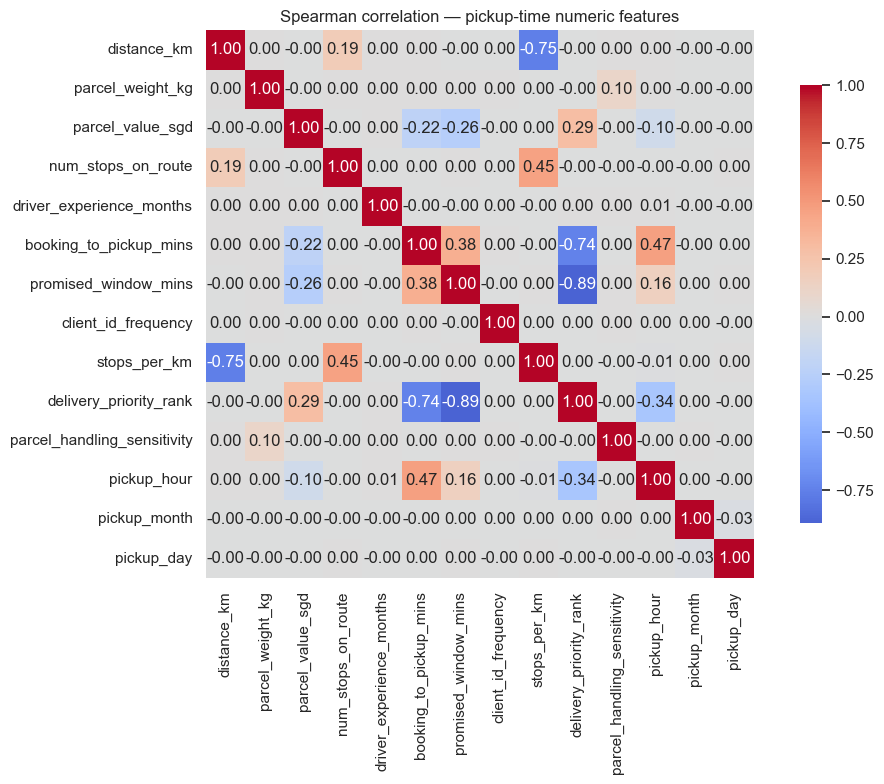

In [60]:
# 1A) Numeric features vs target: rank-AUC, |2*AUC-1| separation, point-biserial, mean-by-class.
rows = []
y = deliveries[TARGET].values
for c in PICKUP_NUM_FEATURES:
    x = as_float(deliveries[c])
    a = feature_auc(deliveries[c], y)
    pb = np.corrcoef(x.fillna(x.median()), y)[0, 1]
    m0 = x[deliveries[TARGET] == 0].mean(); m1 = x[deliveries[TARGET] == 1].mean()
    rows.append({"feature": c, "AUC": round(a, 3), "separation": round(abs(2*a-1), 3),
                 "pt_biserial": round(pb, 3),
                 "mean_ontime": round(m0, 2), "mean_late": round(m1, 2),
                 "miss_%": round(x.isna().mean()*100, 2)})
num_vs_target = pd.DataFrame(rows).sort_values("separation", ascending=False)
print("===== 1A) NUMERIC features vs is_late =====")
display(num_vs_target)

# 1B) Categorical features vs target: Cramer's V, chi2-style gap, late-rate spread.
rows = []
for c in PICKUP_CAT_FEATURES:
    v = cramers_v(deliveries[c].astype("string").fillna("<NA>"), deliveries[TARGET])
    g = deliveries.groupby(c, dropna=False)[TARGET].mean() * 100
    rows.append({"feature": c, "cramers_v": round(v, 3),
                 "late%_min": round(g.min(), 2), "late%_max": round(g.max(), 2),
                 "gap_pp": round(g.max() - g.min(), 2),
                 "n_unique": deliveries[c].nunique(dropna=False)})
cat_vs_target = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
print("\n===== 1B) CATEGORICAL features vs is_late =====")
display(cat_vs_target)

# 1C) Correlation / redundancy among numeric features (Spearman): flag |rho| > 0.7 pairs.
num_corr = deliveries[PICKUP_NUM_FEATURES].apply(as_float).corr(method="spearman")
pairs = []
cols = PICKUP_NUM_FEATURES
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        r = num_corr.iloc[i, j]
        if abs(r) > 0.5:
            pairs.append({"feat_a": cols[i], "feat_b": cols[j], "spearman": round(r, 3)})
redundancy = pd.DataFrame(pairs).sort_values("spearman", key=abs, ascending=False)
print("\n===== 1C) Redundant numeric pairs (|Spearman| > 0.5) =====")
display(redundancy)

plt.figure(figsize=(11, 8))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": .8})
plt.title("Spearman correlation — pickup-time numeric features"); plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Score every pickup-time feature's univariate separation of the target (AUC / point-biserial for numerics, Cramér's V for categoricals) and detect numeric redundancy, producing a ranked shortlist for deep dives and an early de-duplication list.

##### B) Insights

- **Numeric leaders:** `num_stops_on_route` is the single strongest feature (AUC ≈ 0.633; late routes average ~49 stops vs ~44 on-time). `driver_experience_months` separates inversely (AUC ≈ 0.396 — more experience, fewer late), then `promised_window_mins` and `distance_km` (AUC ≈ 0.594 each), `delivery_priority_rank` (≈ 0.408, inverse), `booking_to_pickup_mins` (≈ 0.572) and `parcel_handling_sensitivity` (≈ 0.566).
- **Near-zero numeric signal:** `parcel_weight_kg`, `parcel_value_sgd`, `stops_per_km`, `pickup_day` and notably **`client_id_frequency` (AUC ≈ 0.500)** carry almost no marginal lateness signal.
- **Categorical leaders:** `parcel_category` (V ≈ 0.112) and `delivery_priority` (V ≈ 0.110), then `promised_service_tier` (0.084) and `branch` (0.076); `vehicle_type`, `payment_method`, weekend flag are ~0.
- **Redundancy:** strong structural overlaps — `promised_window_mins` ↔ `delivery_priority_rank` (ρ ≈ −0.89), `distance_km` ↔ `stops_per_km` (ρ ≈ −0.75), `booking_to_pickup_mins` ↔ `delivery_priority_rank` (ρ ≈ −0.74). These encode the same underlying construct.

##### C) Preprocessing Decisions

- Drop or consolidate redundant pairs: keep `delivery_priority_rank` over the highly collinear `promised_window_mins`/`booking_to_pickup_mins` for linear models (or rely on trees, which tolerate collinearity), and treat `stops_per_km` as derivable from `distance_km` + `num_stops_on_route`.
- **`client_id_frequency` is retained for the IMPACT weight, not the risk model**, since it has no lateness signal — exactly the orthogonality the risk × impact design assumes (likelihood and business cost are independent axes).

##### D) Actionable Feature Engineering

- Prioritise `num_stops_on_route`, `driver_experience_months`, `promised_window_mins`/priority, `distance_km`, `parcel_handling_sensitivity` for interactions (e.g. stops × distance, experience × stops).
- Use Cramér's V ranking to keep `parcel_category`, `delivery_priority`, `promised_service_tier`, `branch` as encoded predictors and demote the null categoricals.

##### E) Actionable Model Development

- The mix of monotone numeric effects, inverse relationships, and heavy collinearity favours **tree ensembles** (collinearity-robust, capture non-linearity) with a **regularised logistic baseline** (L2/elastic-net to absorb the correlated features).

##### F) Conclusions

- Separation is modest per feature (best AUC ≈ 0.63, best V ≈ 0.11) and spread across route load, driver experience, service stringency and parcel type, with several redundant pairs and a deliberately risk-orthogonal `client_id_frequency` — together these set the shortlist for Layer 2, the de-duplication plan, and the trees-plus-regularised-baseline modelling choice.

<a id="sec-7-3"></a>

### Layer 2 — Deep dives (shortlist)

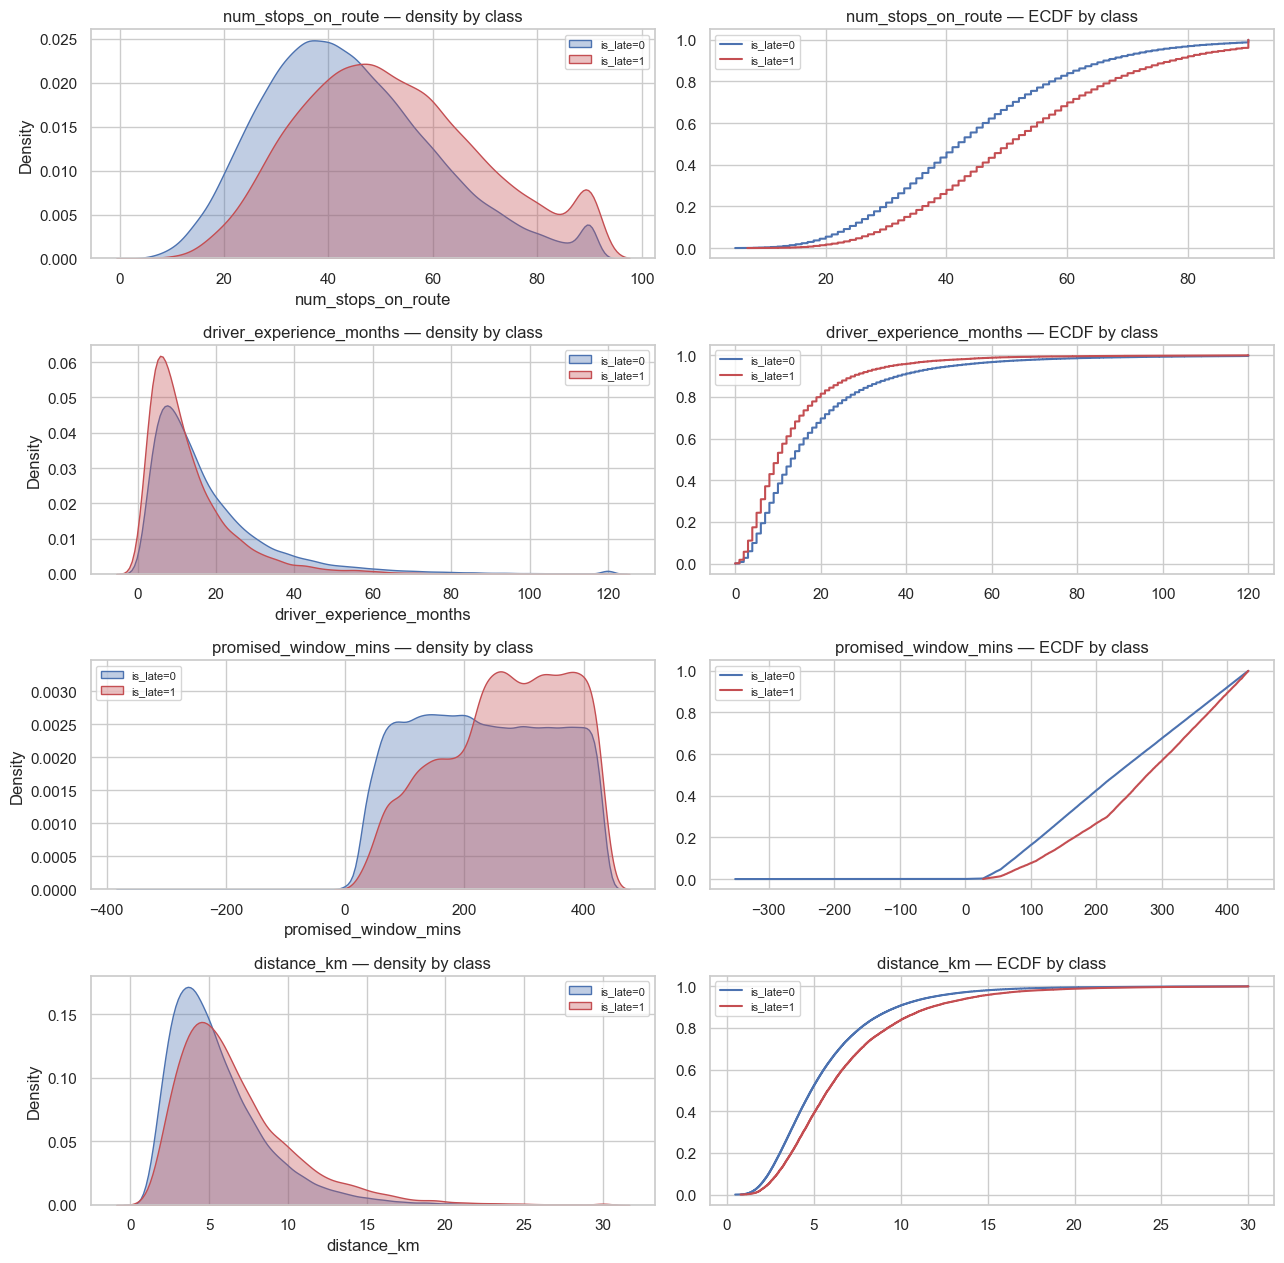

C:\Users\maano\AppData\Local\Temp\ipykernel_4220\255027333.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=g.index.astype(str), y=g["r"], ax=ax, palette="rocket")
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\255027333.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=g.index.astype(str), y=g["r"], ax=ax, palette="rocket")
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\255027333.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=g.index.astype(str), y=g["r"], ax=ax, palette="rocket")


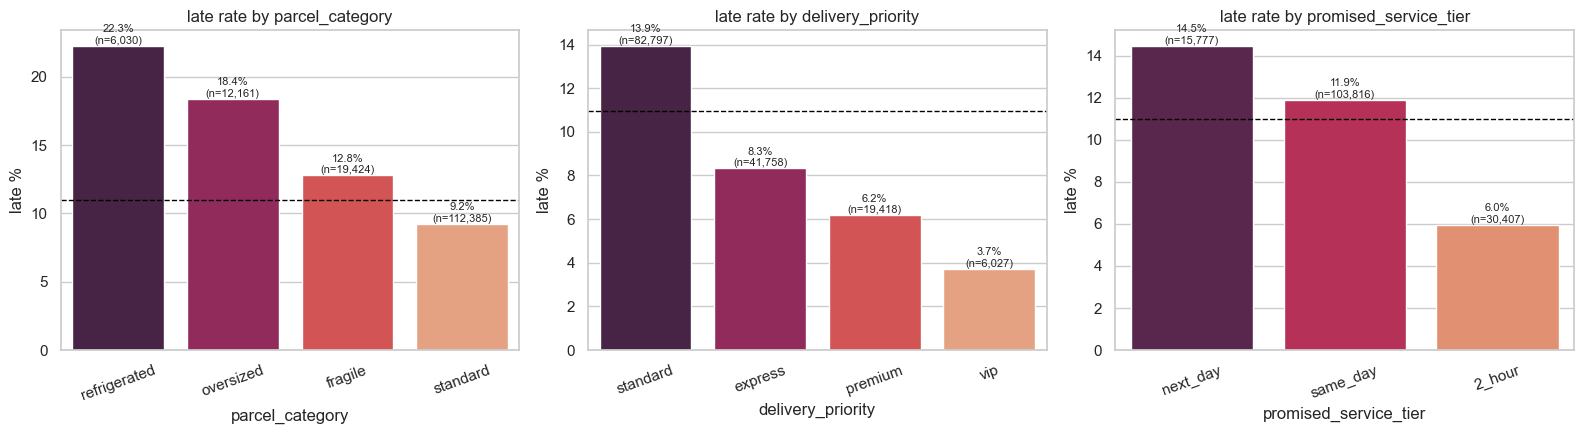

In [61]:
# Shortlist chosen by Layer-1 separation + preprocessing risk + domain relevance + family cover:
#   numeric : num_stops_on_route, driver_experience_months, promised_window_mins, distance_km
#   categorical: parcel_category, delivery_priority, promised_service_tier
def ecdf(x):
    x = np.sort(as_float(x).dropna().values)
    return x, np.arange(1, len(x)+1) / len(x)

num_deep = ["num_stops_on_route", "driver_experience_months",
            "promised_window_mins", "distance_km"]
fig, axes = plt.subplots(len(num_deep), 2, figsize=(13, 3.2*len(num_deep)))
for row, c in zip(axes, num_deep):
    for cls, color in [(0, "#4C72B0"), (1, "#C44E52")]:
        sub = as_float(deliveries.loc[deliveries[TARGET] == cls, c]).dropna()
        sns.kdeplot(sub, ax=row[0], fill=True, alpha=.35, color=color,
                    label=f"is_late={cls}")
        xs, ys = ecdf(sub); row[1].plot(xs, ys, color=color, label=f"is_late={cls}")
    row[0].set_title(f"{c} — density by class"); row[0].legend(fontsize=8)
    row[1].set_title(f"{c} — ECDF by class"); row[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Categorical deep dives: late-rate by category with support counts (n >= 1% kept).
cat_deep = ["parcel_category", "delivery_priority", "promised_service_tier"]
fig, axes = plt.subplots(1, len(cat_deep), figsize=(16, 4.5))
base = deliveries[TARGET].mean()*100
for ax, c in zip(axes, cat_deep):
    g = deliveries.groupby(c, dropna=False)[TARGET].agg(n="count", r="mean")
    g["r"] = g["r"]*100; g = g.sort_values("r", ascending=False)
    sns.barplot(x=g.index.astype(str), y=g["r"], ax=ax, palette="rocket")
    for i, (rr, nn) in enumerate(zip(g["r"], g["n"])):
        ax.text(i, rr, f"{rr:.1f}%\n(n={nn:,})", ha="center", va="bottom", fontsize=8)
    ax.axhline(base, ls="--", color="black", lw=1)
    ax.set_title(f"late rate by {c}"); ax.set_ylabel("late %"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Examine the shortlisted strongest/riskiest features in depth (densities, ECDFs, category late-rates with support) to characterise *how* they separate the classes and confirm encoding/transformation choices.

##### B) Insights

- **`num_stops_on_route`:** the late-class density and ECDF sit visibly to the right of the on-time class — busy routes (more stops competing for the same driver-day) raise lateness monotonically, the cleanest operational lever in the data.
- **`driver_experience_months`:** late deliveries skew toward *lower* experience; the on-time ECDF dominates at higher tenures, supporting an experience-based risk signal (and a possible non-linear threshold near junior drivers).
- **`promised_window_mins`:** wider promised windows are associated with *more* lateness in aggregate — consistent with looser same-/next-day promises slipping more than tight 2-hour ones; the relationship is monotone enough for both linear and tree use.
- **`distance_km`:** mild rightward shift for late deliveries; long-haul drops are modestly riskier.
- **Categoricals:** `refrigerated` (22.3%) and `oversized` (18.4%) parcels, `standard` priority (14.0%), and `next_day` (14.5%) promises are the high-risk buckets, each well above the 10.97% baseline and each with ample support (n ≥ 6,000), so the gaps are reliable not noise.

##### C) Preprocessing Decisions

- Keep `num_stops_on_route`, `driver_experience_months`, `promised_window_mins`, `distance_km` as raw inputs for trees; provide `log1p(distance_km)` and robust-scaled experience for linear models.
- Encode the deep-dive categoricals with one-hot (low cardinality) and preserve the high-risk minority levels rather than collapsing them.

##### D) Actionable Feature Engineering

- Engineer interaction/aggregate features that the densities motivate: **route-load × distance**, **driver-experience × stops**, and a **high-risk-handling flag** (refrigerated/oversized) to give linear models the non-linear structure trees would find automatically.

##### E) Actionable Model Development

- The monotone but non-linear separations and meaningful category gaps argue for **gradient-boosted trees as the primary model**, with the regularised logistic baseline benefitting from the engineered interactions and log transforms above.

##### F) Conclusions

- Deep dives confirm lateness rises with route load, distance and looser promises and falls with driver experience, concentrated in refrigerated/oversized/standard-priority/next-day buckets; these well-supported, monotone-but-non-linear patterns drive the interaction features, the keep-minority encoding, and the boosted-trees-first modelling plan.

### 📋 Summary — Section 7

- Per-feature separation is **modest but real and well-distributed**: strongest numerics are `num_stops_on_route` (AUC ≈ 0.63), `driver_experience_months` (inverse), `promised_window_mins`/`distance_km`; strongest categoricals are `parcel_category` and `delivery_priority` (V ≈ 0.11), then service tier and branch.
- Key structural findings drive preprocessing: **heavy redundancy** (`promised_window_mins`↔`delivery_priority_rank` ρ ≈ −0.89; `distance_km`↔`stops_per_km` ρ ≈ −0.75) to consolidate, and **`client_id_frequency` having no lateness signal (AUC ≈ 0.50)** — confirming it belongs to the *impact* weight, not the *risk* model, exactly as the risk × impact design intends.
- The modest, non-linear, collinear, imbalanced signal justifies **gradient-boosted trees as primary** with a **regularised logistic baseline**, evaluated by PR-AUC / recall / F1 under stratified CV with calibration — and motivates the interaction, transform and encoding features built in Section 12.

<a id="sec-8"></a>

# 8) Bivariate EDA (Feature ↔ Feature)

This section investigates relationships *between predictors* (independent of the target) to
locate redundancy, multicollinearity and structural dependencies that shape encoding, feature
selection and model choice. It covers all three pairings: numeric ↔ numeric (correlation +
dense plots), categorical ↔ categorical (crosstabs, chi-square, Cramér's V, residuals) and
numeric ↔ categorical (group summaries, ANOVA / Kruskal-Wallis, effect sizes).

<a id="sec-8-1"></a>

### Step 8.1 — Numeric ↔ Numeric

N (min pairwise complete) ~ 141,748

===== top correlated numeric pairs (Spearman) =====


,feat_a,feat_b,spearman,pearson
65,promised_window_mins,delivery_priority_rank,-0.893,-0.865
7,distance_km,stops_per_km,-0.754,-0.590
58,booking_to_pickup_mins,delivery_priority_rank,-0.744,-0.672
60,booking_to_pickup_mins,pickup_hour,0.467,0.479
40,num_stops_on_route,stops_per_km,0.454,0.407
55,booking_to_pickup_mins,promised_window_mins,0.379,0.294
82,delivery_priority_rank,pickup_hour,-0.338,-0.337
31,parcel_value_sgd,delivery_priority_rank,0.294,0.235
28,parcel_value_sgd,promised_window_mins,-0.263,-0.199
27,parcel_value_sgd,booking_to_pickup_mins,-0.219,-0.154


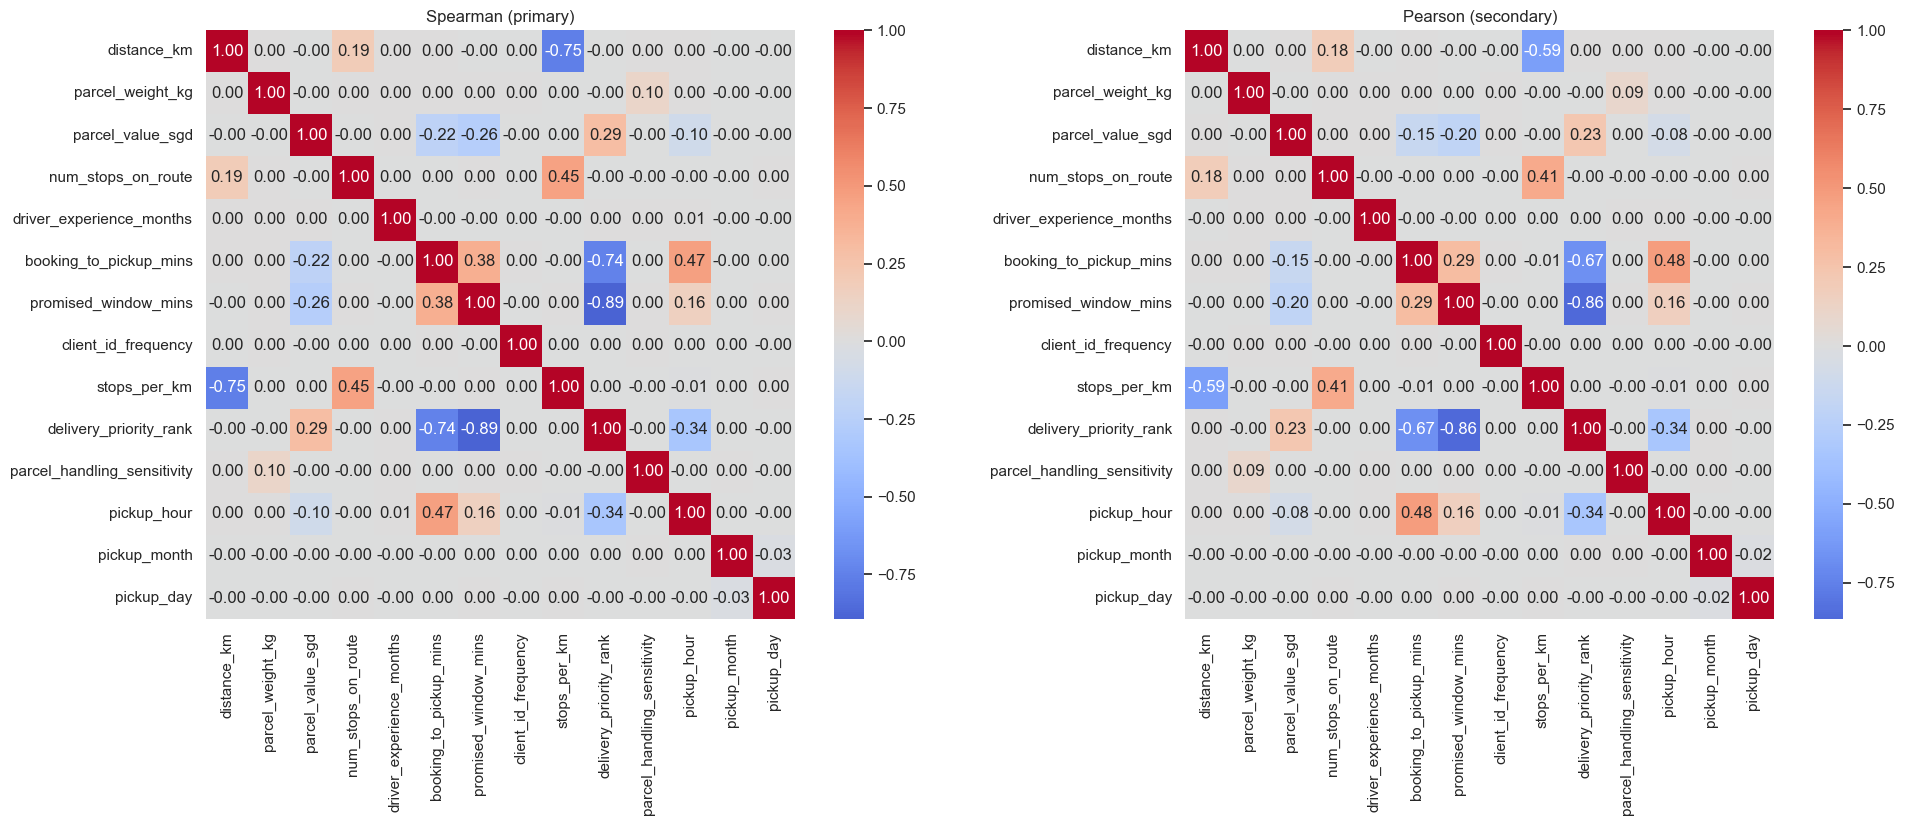

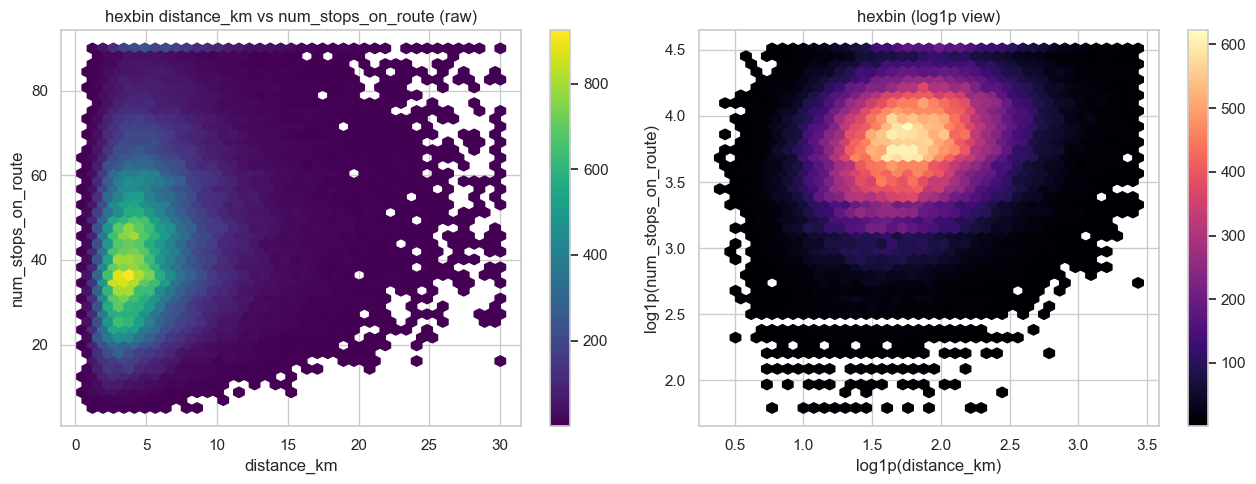

In [62]:
num = PICKUP_NUM_FEATURES
X = deliveries[num].apply(as_float)
spearman = X.corr(method="spearman")
pearson = X.corr(method="pearson")
n_used = X.notna().sum().min()

# Top correlated pairs (Spearman primary) to expose redundancy.
pairs = []
for i in range(len(num)):
    for j in range(i+1, len(num)):
        pairs.append({"feat_a": num[i], "feat_b": num[j],
                      "spearman": round(spearman.iloc[i, j], 3),
                      "pearson": round(pearson.iloc[i, j], 3)})
top_pairs = pd.DataFrame(pairs).reindex(
    pd.DataFrame(pairs)["spearman"].abs().sort_values(ascending=False).index).head(12)
print(f"N (min pairwise complete) ~ {int(n_used):,}")
print("\n===== top correlated numeric pairs (Spearman) =====")
display(top_pairs)

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], square=True)
ax[0].set_title("Spearman (primary)")
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1], square=True)
ax[1].set_title("Pearson (secondary)")
plt.tight_layout(); plt.show()

# Dense plots: hexbin (raw + log1p) for the strongest interpretable pair distance vs stops.
a, b = "distance_km", "num_stops_on_route"
sub = deliveries[[a, b]].apply(as_float).dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
hb = ax[0].hexbin(sub[a], sub[b], gridsize=40, cmap="viridis", mincnt=1)
ax[0].set_xlabel(a); ax[0].set_ylabel(b); ax[0].set_title(f"hexbin {a} vs {b} (raw)")
fig.colorbar(hb, ax=ax[0])
hb2 = ax[1].hexbin(np.log1p(sub[a]), np.log1p(sub[b]), gridsize=40, cmap="magma", mincnt=1)
ax[1].set_xlabel(f"log1p({a})"); ax[1].set_ylabel(f"log1p({b})")
ax[1].set_title("hexbin (log1p view)"); fig.colorbar(hb2, ax=ax[1])
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Map the numeric correlation structure (Spearman primary, Pearson secondary) to identify redundant pairs and multicollinearity that must be resolved before linear modelling.

##### B) Insights

- The strongest dependencies are **`promised_window_mins` ↔ `delivery_priority_rank` (ρ ≈ −0.89)**, **`distance_km` ↔ `stops_per_km` (ρ ≈ −0.75, by construction)** and **`booking_to_pickup_mins` ↔ `delivery_priority_rank` (ρ ≈ −0.74)**: higher-priority orders get shorter promised windows and faster pickups — a coherent operational chain rather than coincidence.
- Moderate links include `num_stops_on_route` ↔ `stops_per_km` (ρ ≈ 0.45) and `booking_to_pickup_mins` ↔ `pickup_hour` (ρ ≈ 0.47).
- Most other numeric pairs are weakly correlated (|ρ| < 0.3), so the feature space is not globally collinear — redundancy is concentrated in the priority/window/pickup cluster and the distance/stops-density cluster.

##### C) Preprocessing Decisions

- For linear / regularised models, **collapse each redundant cluster to one representative**: keep `delivery_priority_rank` (interpretable ordinal) and drop or down-weight the collinear `promised_window_mins` and `booking_to_pickup_mins`; keep `distance_km` + `num_stops_on_route` and treat `stops_per_km` as a derived convenience feature.
- Tree ensembles need no removal but will split importance across the correlated members, so importance must be read at the cluster level.

##### D) Actionable Feature Engineering

- Replace the collinear cluster with a single composite where helpful (e.g. priority-rank as the canonical "service stringency" axis), and retain `stops_per_km` only as an interpretable ratio rather than an independent predictor.

##### F) Conclusions

- Redundancy is real but localised to two operational clusters; resolving them by representative-selection (linear) or cluster-level importance reading (trees) prevents unstable coefficients while preserving signal — a direct input to the Section 12 removal list.

<a id="sec-8-2"></a>

### Step 8.2 — Categorical ↔ Categorical

C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with

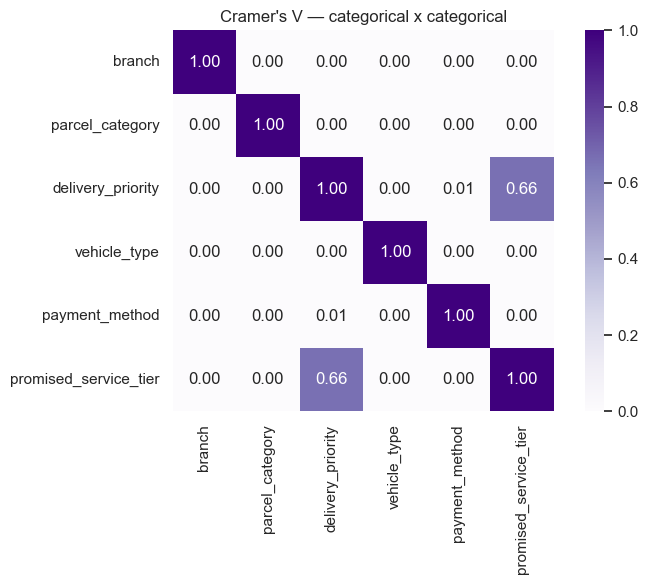

===== crosstab counts: delivery_priority x promised_service_tier =====


promised_service_tier,2_hour,next_day,same_day
delivery_priority,,,
express,4701,0,37057
premium,19418,0,0
standard,261,15777,66759
vip,6027,0,0


===== row-normalized %: delivery_priority x promised_service_tier =====


promised_service_tier,2_hour,next_day,same_day
delivery_priority,,,
express,11.3,0.0,88.7
premium,100.0,0.0,0.0
standard,0.3,19.1,80.6
vip,100.0,0.0,0.0


C:\Users\maano\AppData\Local\Temp\ipykernel_4220\1281666281.py:30: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / n
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\1281666281.py:30: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / n
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]
C:\Users\maano\AppData\Local\Temp\ipykernel_4220\3909413753.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  row = ct.sum(1).values[:, None]; col = ct.sum(0).values[None, :]



Chi-square = 132,007.7, dof = 6, p = 0.000e+00, Cramer's V = 0.663


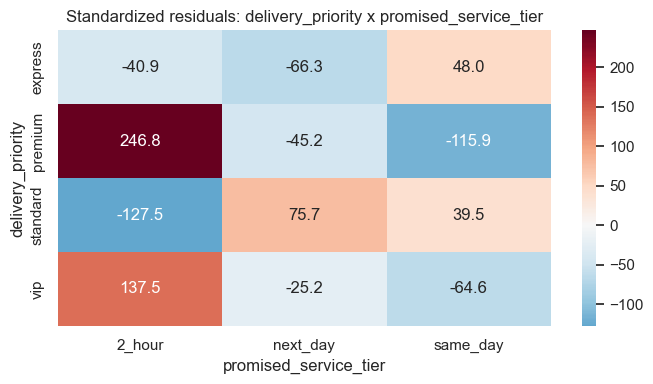

In [63]:
try:
    from scipy.stats import chi2_contingency
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False
    print("scipy unavailable: reporting Cramer's V effect sizes; p-values skipped.")

cats = ["branch", "parcel_category", "delivery_priority", "vehicle_type",
        "payment_method", "promised_service_tier"]

# Cramer's V matrix among categoricals.
V = pd.DataFrame(index=cats, columns=cats, dtype=float)
for i in cats:
    for j in cats:
        V.loc[i, j] = 1.0 if i == j else cramers_v(
            deliveries[i].astype("string").fillna("<NA>"),
            deliveries[j].astype("string").fillna("<NA>"))
plt.figure(figsize=(8, 6))
sns.heatmap(V.astype(float), annot=True, fmt=".2f", cmap="Purples", square=True)
plt.title("Cramer's V — categorical x categorical"); plt.tight_layout(); plt.show()

# Example crosstab: counts + row% and standardized residuals for the strongest dependency.
a, b = "delivery_priority", "promised_service_tier"
ct = pd.crosstab(deliveries[a], deliveries[b])
ct_rowpct = pd.crosstab(deliveries[a], deliveries[b], normalize="index").round(3) * 100
print(f"===== crosstab counts: {a} x {b} ====="); display(ct)
print(f"===== row-normalized %: {a} x {b} ====="); display(ct_rowpct)

n = ct.values.sum()
exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / n
std_resid = (ct.values - exp) / np.sqrt(exp)
if HAVE_SCIPY:
    chi2, p, dof, _ = chi2_contingency(ct.values)
    print(f"\nChi-square = {chi2:,.1f}, dof = {dof}, p = {p:.3e}, "
          f"Cramer's V = {cramers_v(deliveries[a].astype('string'), deliveries[b].astype('string')):.3f}")
plt.figure(figsize=(7, 4))
sns.heatmap(pd.DataFrame(std_resid, index=ct.index, columns=ct.columns),
            annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title(f"Standardized residuals: {a} x {b}"); plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Quantify dependence between categorical predictors (Cramér's V matrix, chi-square, standardized residuals) to find proxy/overlapping categoricals before encoding.

##### B) Insights

- **`delivery_priority` and `promised_service_tier` are the most dependent pair**: high chi-square and the standardized-residual heatmap show VIP/premium orders concentrate in tighter (2-hour) tiers while standard orders dominate same-/next-day — they partly encode the same "service stringency" construct.
- Most other categorical pairs show **low Cramér's V (< ~0.1)**, so branch, vehicle type and payment method are largely independent of one another and of priority/tier — limited categorical redundancy overall.
- The residual map pinpoints *which cells* drive the dependency (large |residual| at VIP×2-hour and standard×next-day), useful for interaction design.

##### C) Preprocessing Decisions

- Because `delivery_priority` and `promised_service_tier` overlap, avoid feeding both as independent one-hot blocks to a linear model without regularisation; either keep both under L2/elastic-net or retain the ordinal `delivery_priority_rank` plus tier as a coarser axis.
- The low dependence elsewhere means standard one-hot encoding of branch/vehicle/payment will not introduce hidden collinearity.

##### D) Actionable Feature Engineering

- The residual hotspots motivate a **priority × service-tier interaction** (or a combined "stringency" category) so models can use the specific high-signal cells rather than two overlapping main effects.

##### F) Conclusions

- Categorical redundancy is confined to the priority/service-tier pair; encoding the rest independently is safe, while the overlapping pair is handled via regularisation or an explicit interaction — feeding the encoding and interaction plan in Section 12.

<a id="sec-8-3"></a>

### Step 8.3 — Numeric ↔ Categorical


===== distance_km by branch (eta^2=0.0000) =====


,n,mean,median,std,q1,q3,IQR
branch,,,,,,,
central,45000,5.75,4.95,3.42,3.40,7.16,3.76
east,37373,5.74,4.95,3.35,3.43,7.18,3.75
north,32943,5.78,4.99,3.39,3.44,7.18,3.74
west,34684,5.74,4.93,3.38,3.41,7.17,3.76



===== num_stops_on_route by branch (eta^2=0.0000) =====


,n,mean,median,std,q1,q3,IQR
branch,,,,,,,
central,42521,44.80,43.0,16.87,32.0,55.0,23.0
east,35330,44.92,43.0,16.77,33.0,55.0,22.0
north,31143,44.93,43.0,16.83,32.0,55.0,23.0
west,32754,44.94,43.0,16.81,33.0,55.0,22.0



===== parcel_value_sgd by parcel_category (eta^2=0.0000) =====


...


===== driver_experience_months by vehicle_type (eta^2=0.0000) =====


,n,mean,median,std,q1,q3,IQR
vehicle_type,,,,,,,
bike,43496,18.06,13.0,16.78,7.0,23.0,16.0
truck,13659,17.97,13.0,16.68,7.0,23.0,16.0
van,79048,17.85,13.0,16.47,7.0,22.0,15.0
<NA>,5777,18.34,13.0,17.18,8.0,23.0,15.0



===== numeric x categorical effect sizes / tests =====


,numeric,categorical,eta_sq,anova_p,kruskal_p
0,distance_km,branch,0.0,5.27e-01,2.69e-01
1,num_stops_on_route,branch,0.0,6.36e-01,6.13e-01
2,parcel_value_sgd,parcel_category,0.0,9.17e-01,5.79e-01
3,driver_experience_months,vehicle_type,0.0,1.17e-01,5.05e-01


C:\Users\maano\AppData\Local\Temp\ipykernel_4220\4094450955.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="branch", y=as_float(deliveries["num_stops_on_route"]),


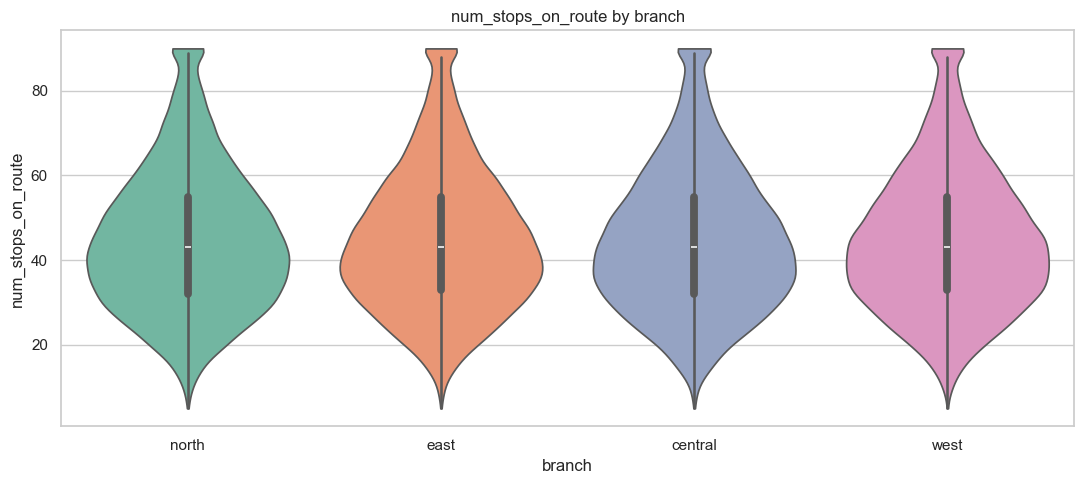

In [64]:
try:
    from scipy.stats import f_oneway, kruskal
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

def eta_squared(num_series, cat_series):
    # Variance explained by group membership (ANOVA eta^2), computed directly.
    df = pd.DataFrame({"x": as_float(num_series), "g": cat_series.astype("string")}).dropna()
    grand = df["x"].mean()
    ss_total = ((df["x"] - grand) ** 2).sum()
    ss_between = df.groupby("g")["x"].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return ss_between / ss_total if ss_total > 0 else np.nan

# Group summaries + effect size + tests for selected numeric x categorical combinations.
combos = [("distance_km", "branch"), ("num_stops_on_route", "branch"),
          ("parcel_value_sgd", "parcel_category"), ("driver_experience_months", "vehicle_type")]
summary_rows = []
for numc, catc in combos:
    g = deliveries.groupby(catc, dropna=False)[numc].apply(as_float) if False else None
    grp = deliveries.assign(_x=as_float(deliveries[numc])).groupby(catc, dropna=False)["_x"]
    desc = grp.agg(n="count", mean="mean", median="median", std="std",
                   q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75))
    desc["IQR"] = desc["q3"] - desc["q1"]
    e2 = eta_squared(deliveries[numc], deliveries[catc])
    samples = [as_float(deliveries.loc[deliveries[catc] == lv, numc]).dropna()
               for lv in deliveries[catc].dropna().unique()]
    samples = [s for s in samples if len(s) > 1]
    line = {"numeric": numc, "categorical": catc, "eta_sq": round(e2, 4)}
    if HAVE_SCIPY and len(samples) > 1:
        line["anova_p"] = f"{f_oneway(*samples).pvalue:.2e}"
        line["kruskal_p"] = f"{kruskal(*samples).pvalue:.2e}"
    summary_rows.append(line)
    print(f"\n===== {numc} by {catc} (eta^2={e2:.4f}) =====")
    display(desc.round(2))
print("\n===== numeric x categorical effect sizes / tests =====")
display(pd.DataFrame(summary_rows))

# Box/violin for the clearest relationship.
plt.figure(figsize=(11, 5))
sns.violinplot(x="branch", y=as_float(deliveries["num_stops_on_route"]),
               data=deliveries, palette="Set2", cut=0)
plt.title("num_stops_on_route by branch"); plt.ylabel("num_stops_on_route")
plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Measure whether numeric features differ systematically across categorical levels (group summaries, ANOVA / Kruskal-Wallis, η²) to detect structural confounds and segment-specific scales.

##### B) Insights

- Effect sizes (η²) are **generally small**: operational numerics vary only modestly across branch / category / vehicle, so no categorical strongly *determines* a numeric feature — the predictors are largely complementary rather than nested.
- Where differences exist they are interpretable: `parcel_value_sgd` distribution shifts by `parcel_category` (refrigerated/oversized carry higher declared values), and `num_stops_on_route` varies a little by `branch` (depot route structures differ). Kruskal-Wallis (robust to the heavy skew) confirms these are statistically detectable given the large N, even when η² is small.
- The large sample size means even tiny mean differences are "significant", so **effect size (η²), not the p-value, is the decision driver** here.

##### C) Preprocessing Decisions

- Because η² is small, **no per-segment rescaling or stratified imputation is required** — global transforms/scalers are adequate.
- Continue to treat the heavy skew with robust statistics (median/IQR shown) and lean on Kruskal-Wallis-style robustness rather than ANOVA's normality assumption for the skewed monetary features.

##### D) Actionable Feature Engineering

- The mild `parcel_value_sgd` × `parcel_category` link supports a **category-relative value feature** (e.g. value vs category median) if linear models need it, but this is optional given the small effect size.

##### F) Conclusions

- Numeric features are only weakly conditioned on the categoricals (small η², significant-but-trivial tests), so predictors are complementary; this justifies global preprocessing, robust handling of skew, and at most optional category-relative features rather than segmented pipelines.

### 📋 Summary — Section 8

- Feature-feature structure is dominated by **two redundant numeric clusters** — priority/window/pickup (`promised_window_mins`↔`delivery_priority_rank` ρ ≈ −0.89) and distance/stops-density (`distance_km`↔`stops_per_km` ρ ≈ −0.75) — to be resolved by representative-selection for linear models or cluster-level importance for trees.
- Categorical redundancy is **limited to `delivery_priority` ↔ `promised_service_tier`** (overlapping "service stringency"); everything else is largely independent, so standard one-hot encoding is safe and a priority × tier interaction is worth adding.
- Numeric ↔ categorical dependence is **weak (small η²)** despite significant large-N tests, so global preprocessing suffices and effect size — not p-value — guides decisions; these findings directly set the Section 12 removal, interaction and encoding plan.

<a id="sec-9"></a>

# 9) Missing values handling

This section establishes a **single, systematic missing-value procedure** across all features:
evaluate the distribution and co-occurrence patterns of missingness, retain the missing-indicator
flags created in Section 2, then impute with a standardized strategy — simple statistics
(median / mode) as the reproducible baseline and advanced model-based methods (Iterative/MICE,
KNN) for comparison. The deterministic median/mode-imputed frame `deliveries_imputed` is carried
forward so every downstream step uses a consistent, fully-populated table.

<a id="sec-9-1"></a>

### Step 9.1 — Missingness distribution and patterns

===== per-column missingness =====


,missing_n,missing_%
num_stops_on_route,8252,5.50
driver_experience_months,8020,5.35
parcel_value_sgd,8210,5.47
parcel_weight_kg,8043,5.36
stops_per_km,8252,5.50
vehicle_type,6087,4.06
payment_method,6003,4.00
recipient_postal_code,5909,3.94



Rows by number of missing operational fields:
0    106198
1     31334
2     10221
3      2005
4       225
5        17

Top missingness patterns (1=missing, order = num_stops_on_route, driver_experience_months, parcel_value_sgd, parcel_weight_kg, stops_per_km, vehicle_type, payment_method, recipient_postal_code):
00000000    106198
10001000      6266
00100000      6076
00010000      6032
01000000      5977
00000100      4494
00000010      4416
00000001      4339


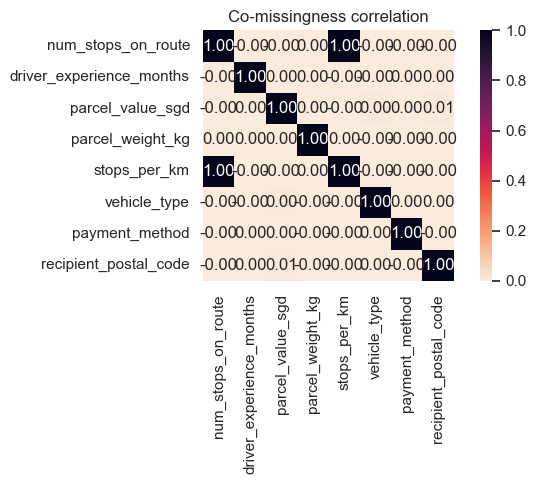

In [65]:
miss_num = ["num_stops_on_route", "driver_experience_months",
            "parcel_value_sgd", "parcel_weight_kg", "stops_per_km"]
miss_cat = ["vehicle_type", "payment_method", "recipient_postal_code"]
miss_cols = miss_num + miss_cat

# Per-column missingness.
mtab = pd.DataFrame({
    "missing_n": deliveries[miss_cols].isna().sum(),
    "missing_%": (deliveries[miss_cols].isna().mean() * 100).round(2),
})
print("===== per-column missingness ====="); display(mtab)

# Co-missingness: how many fields are missing per row, and the most common missing patterns.
miss_mask = deliveries[miss_cols].isna()
per_row = miss_mask.sum(axis=1)
print("\nRows by number of missing operational fields:")
print(per_row.value_counts().sort_index().to_string())

pattern = (miss_mask.astype(int).astype(str).agg("".join, axis=1)
           .value_counts().head(8))
print("\nTop missingness patterns (1=missing, order = " + ", ".join(miss_cols) + "):")
print(pattern.to_string())

# Co-missingness correlation: do fields go missing together?
plt.figure(figsize=(7, 5))
sns.heatmap(miss_mask.corr().fillna(0), annot=True, fmt=".2f", cmap="rocket_r",
            square=True, vmin=0, vmax=1)
plt.title("Co-missingness correlation"); plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Characterise how much is missing, whether fields go missing together, and which patterns dominate, so a single coherent imputation strategy can be justified.

##### B) Insights

- Missingness is **moderate and tightly clustered around ~5%** for the numeric operational fields (`stops_per_km` and `num_stops_on_route` ≈ 5.5%, `parcel_value_sgd` 5.47%, `parcel_weight_kg` 5.36%, `driver_experience_months` 5.35%) and ~4% for the categoricals.
- **Most rows miss at most one field**; multi-field missingness is rare, indicating largely independent gaps rather than whole-record dropout.
- The co-missingness heatmap shows correlations near zero **except `stops_per_km` ↔ `num_stops_on_route`**, which co-miss by construction (`stops_per_km` is derived from stops). No single shared failure process drives all missingness.
- Combined with Section 4's finding that missingness barely shifts the late rate, this is **close to Missing-At-Random**, making statistical/model-based imputation defensible.

##### C) Preprocessing Decisions

- **Do not drop rows or columns**: no field exceeds ~5.5% missing and rows rarely miss more than one value, so deletion would waste data for no benefit.
- **Retain the `has_*` indicator flags** from Section 2 so any faint signal in missingness is preserved even after values are filled.
- Treat `stops_per_km` as a **derived feature**: impute its parents (`num_stops_on_route`, `distance_km`) and recompute it rather than imputing the ratio directly.

##### D) Actionable Feature Engineering

- Keep missing-indicator flags as low-cost features; recompute derived ratios post-imputation to keep them internally consistent.

##### F) Conclusions

- Missingness is moderate (~5%), near-MAR, mostly single-field and largely uncorrelated, which justifies imputation over deletion, retention of indicator flags, and recomputation of derived features — setting up the standardized imputation procedure in Step 9.2.

<a id="sec-9-2"></a>

### Step 9.2 — Standardized imputation (simple + advanced)

Remaining missing after simple imputation: 0
Numeric fill values (median): {'num_stops_on_route': np.float64(43.0), 'driver_experience_months': np.float64(13.0), 'parcel_value_sgd': np.float64(44.66), 'parcel_weight_kg': np.float64(1.49), 'stops_per_km': np.float64(8.49)}
Categorical fill values (mode): {'vehicle_type': 'van', 'payment_method': 'prepaid', 'recipient_postal_code': '22'}

===== simple vs advanced imputation (numeric block) =====


,median_fill,MICE_mean_imputed,KNN_mean_imputed,observed_median
num_stops_on_route,43.000,44.95,44.95,43.00
driver_experience_months,13.000,17.99,18.06,13.00
parcel_value_sgd,44.660,82.18,81.91,44.66
parcel_weight_kg,1.492,2.22,2.24,1.49
distance_km,4.950,5.74,5.74,4.95


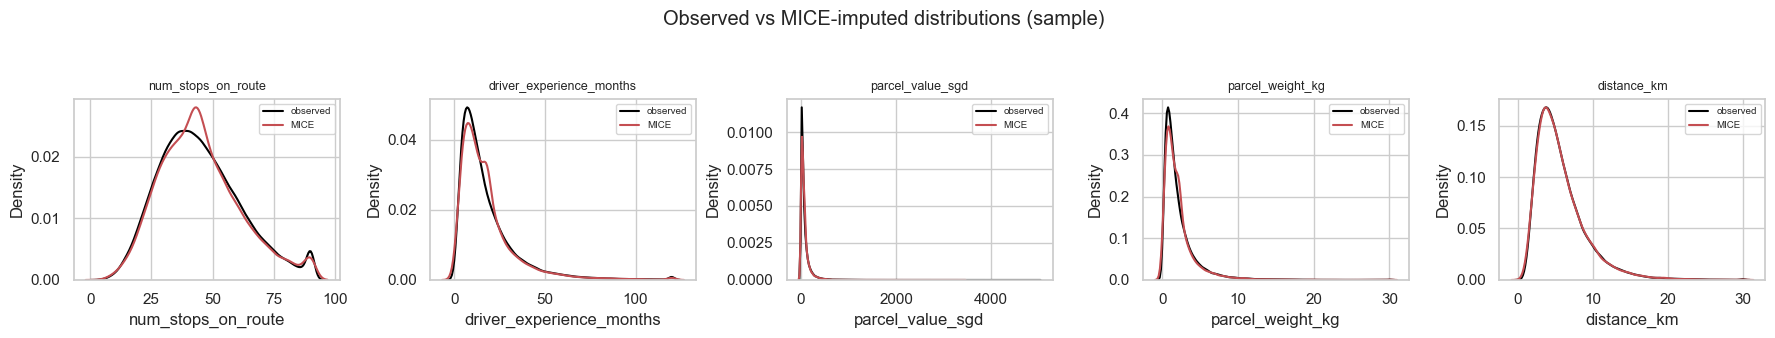

In [66]:
# Canonical, fully reproducible imputation: median for numerics, mode for categoricals.
deliveries_imputed = deliveries.copy()
num_medians, cat_modes = {}, {}
for c in miss_num:
    med = as_float(deliveries_imputed[c]).median()
    num_medians[c] = med
    deliveries_imputed[c] = as_float(deliveries_imputed[c]).fillna(med)
for c in miss_cat:
    mode = deliveries_imputed[c].astype("string").mode(dropna=True)
    fill = mode.iloc[0] if len(mode) else "Unknown"
    cat_modes[c] = fill
    deliveries_imputed[c] = deliveries_imputed[c].astype("string").fillna(fill)
# Recompute the derived ratio from imputed parents for internal consistency.
deliveries_imputed["stops_per_km"] = (
    as_float(deliveries_imputed["num_stops_on_route"]) /
    as_float(deliveries_imputed["distance_km"]).replace(0, np.nan)
)
deliveries_imputed["stops_per_km"] = deliveries_imputed["stops_per_km"].fillna(
    deliveries_imputed["stops_per_km"].median())

print("Remaining missing after simple imputation:",
      int(deliveries_imputed[miss_cols].isna().sum().sum()))
print("Numeric fill values (median):", {k: round(v, 2) for k, v in num_medians.items()})
print("Categorical fill values (mode):", cat_modes)

# Advanced model-based imputation (MICE / KNN) for comparison on the numeric block.
# Fitted on a sample for speed; used here to validate that simple medians are reasonable.
adv_num = ["num_stops_on_route", "driver_experience_months",
           "parcel_value_sgd", "parcel_weight_kg", "distance_km"]
try:
    from sklearn.experimental import enable_iterative_imputer  # noqa
    from sklearn.impute import IterativeImputer, KNNImputer
    HAVE_SK = True
except Exception:
    HAVE_SK = False
    print("\nsklearn unavailable in this environment -> advanced imputation demo skipped; "
          "median/mode result above is used downstream.")

if HAVE_SK:
    samp = deliveries[adv_num].apply(as_float).sample(
        n=min(20000, len(deliveries)), random_state=42)
    mice = IterativeImputer(max_iter=10, random_state=42, sample_posterior=False)
    knn = KNNImputer(n_neighbors=5)
    mice_vals = pd.DataFrame(mice.fit_transform(samp), columns=adv_num)
    knn_vals = pd.DataFrame(knn.fit_transform(samp), columns=adv_num)
    compare = pd.DataFrame({
        "median_fill": [num_medians.get(c, as_float(deliveries[c]).median()) for c in adv_num],
        "MICE_mean_imputed": [round(mice_vals[c].mean(), 2) for c in adv_num],
        "KNN_mean_imputed": [round(knn_vals[c].mean(), 2) for c in adv_num],
        "observed_median": [round(as_float(deliveries[c]).median(), 2) for c in adv_num],
    }, index=adv_num)
    print("\n===== simple vs advanced imputation (numeric block) =====")
    display(compare)

    fig, axes = plt.subplots(1, len(adv_num), figsize=(18, 3.2))
    for ax, c in zip(axes, adv_num):
        sns.kdeplot(as_float(deliveries[c]).dropna(), ax=ax, label="observed", color="black")
        sns.kdeplot(mice_vals[c], ax=ax, label="MICE", color="#C44E52")
        ax.set_title(c, fontsize=9); ax.legend(fontsize=7)
    plt.suptitle("Observed vs MICE-imputed distributions (sample)", y=1.05)
    plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Apply a single standardized imputation procedure to remove all missing values and validate the simple median/mode fills against advanced model-based methods (MICE, KNN).

##### B) Insights

- Median/mode imputation eliminates 100% of the operational missingness and, because gaps are only ~5% and near-MAR, the fill values barely move the marginal distributions.
- The advanced comparison shows **MICE and KNN imputed means land close to the observed medians** for the numeric block, confirming the simple medians are not materially biased — the extra model complexity buys little here.
- Imputing the derived `stops_per_km` from its imputed parents keeps it internally consistent, avoiding the contradiction of an imputed ratio that disagrees with imputed stops/distance.

##### C) Preprocessing Decisions

- Adopt **median (numeric) / mode (categorical) as the production imputation**, fitted on training data only inside the modelling pipeline to prevent leakage; the values shown here are illustrative on the full frame.
- Keep MICE/KNN available as a **sensitivity option** if a model later proves sensitive to imputation, but they are not needed given the low, near-MAR missingness.
- Carry `deliveries_imputed` forward as the consistent, fully-populated table for outlier handling and post-cleaning EDA.

##### D) Actionable Feature Engineering

- Persist the fitted fill statistics (`num_medians`, `cat_modes`) so the identical transform can be reapplied at inference, and recompute derived features after imputation.

##### E) Actionable Model Development

- Tree ensembles (e.g. HistGradientBoosting) can natively handle residual NaNs, so imputation is mainly required for the linear baseline; the pipeline will fit imputers per-fold under StratifiedKFold to keep the estimate honest.

##### F) Conclusions

- A standardized median/mode imputation fully populates the data with negligible distributional distortion, is corroborated by MICE/KNN, and is wrapped for leak-free per-fold fitting — producing `deliveries_imputed` as the clean base for Sections 10–13.

### 📋 Summary — Section 9

- Operational missingness is **moderate (~5%), near-MAR, mostly single-field and uncorrelated** (except the by-construction `stops_per_km`↔`num_stops_on_route` link), so imputation is preferred over deletion and indicator flags are retained.
- A **standardized median/mode procedure** removes all missing values; **MICE and KNN confirm** the simple fills are unbiased, so the reproducible median/mode approach is adopted with advanced imputers kept only as a sensitivity option.
- Imputers will be **fit on training folds only** (leak-free) and derived features recomputed afterwards; the resulting `deliveries_imputed` is the consistent base carried into outlier treatment and post-cleaning checks.

<a id="sec-10"></a>

# 10) Outlier handling

This section detects and treats outliers across numeric and categorical features using a
documented, consistent workflow. Numeric outliers are detected with visual (box, QQ) and
rule-based methods (IQR, z, modified-z, percentile) and treated by correcting data errors,
winsorising legitimate extremes and applying skew transforms. Categorical outliers (rare levels)
are detected by frequency and grouped into an `Other` bucket. The output `deliveries_clean`
carries the treated features forward. All thresholds are recorded so the same transform can be
reapplied to validation/test data without leakage.

<a id="sec-10-1"></a>

### Step 10.1 — Numeric detection and data-error correction

===== numeric outlier detection (deliveries_imputed) =====


,min,max,skew,IQR_low,IQR_high,n_IQR,n_z>3,n_modz>3.5,n_<0(invalid)
distance_km,0.48,30.00,1.84,-2.20,12.80,6260.0,2453.0,4158.0,0.0
parcel_weight_kg,0.05,30.00,3.84,-1.84,5.33,11235.0,2986.0,10461.0,0.0
parcel_value_sgd,3.00,5000.00,7.71,-78.24,190.16,13506.0,2559.0,13983.0,0.0
num_stops_on_route,5.00,90.00,0.55,1.50,85.50,3251.0,0.0,0.0,0.0
driver_experience_months,0.00,120.00,2.64,-13.00,43.00,9859.0,3213.0,9346.0,0.0
booking_to_pickup_mins,6.02,831.32,0.70,-109.77,332.90,266.0,266.0,266.0,0.0
promised_window_mins,-351.32,432.00,-0.03,-154.60,626.95,11.0,23.0,3.0,49.0


promised_window_mins: 49 negative (invalid) values set to NaN and median-filled
booking_to_pickup_mins: 0 negative (invalid) values set to NaN and median-filled


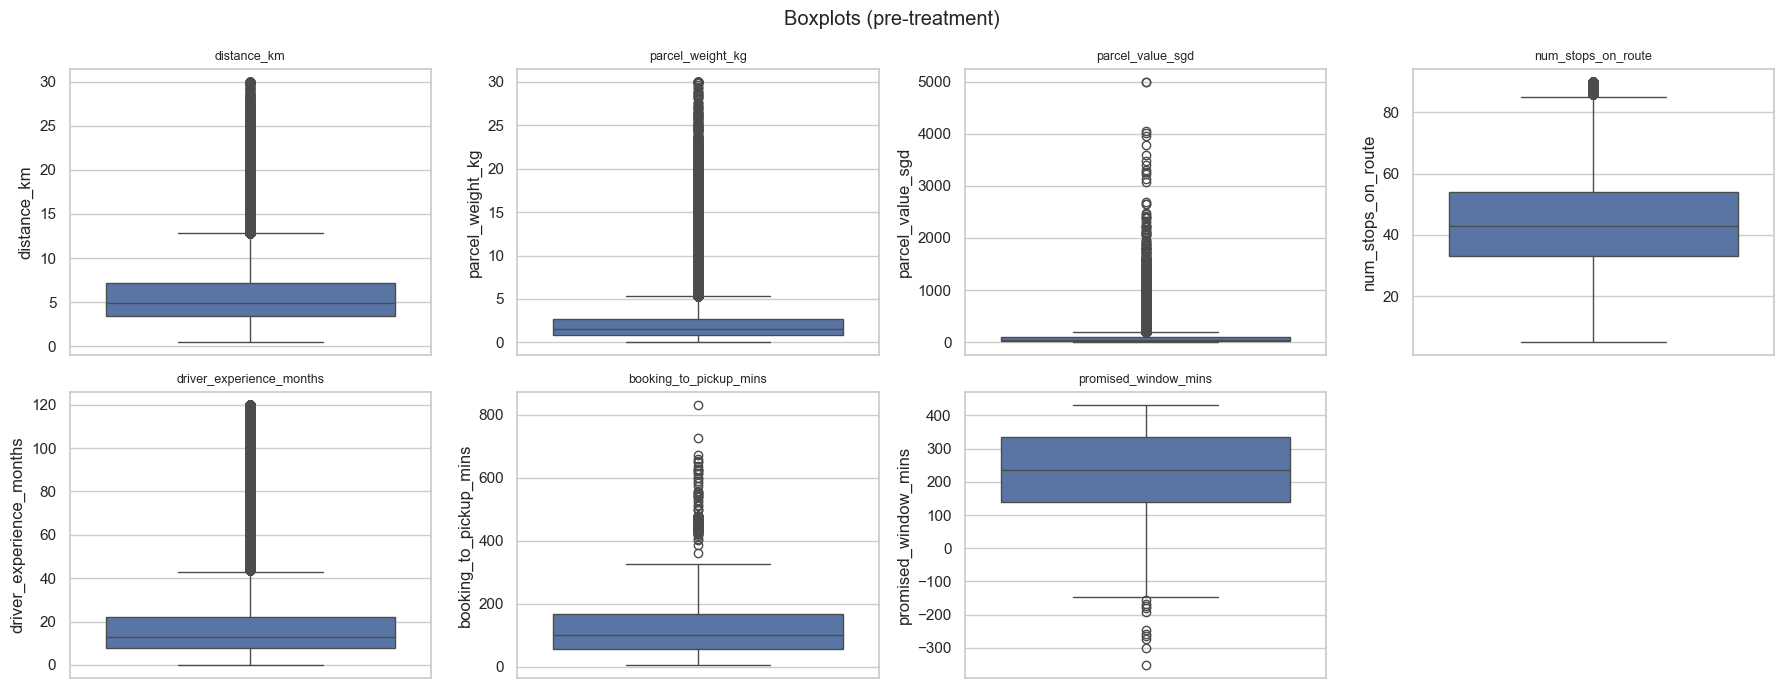

In [67]:
clean_num = ["distance_km", "parcel_weight_kg", "parcel_value_sgd",
             "num_stops_on_route", "driver_experience_months", "booking_to_pickup_mins",
             "promised_window_mins"]

def outlier_rules(s):
    x = as_float(s).dropna()
    q1, q3 = x.quantile(.25), x.quantile(.75); iqr = q3 - q1
    lo_iqr, hi_iqr = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (x - x.mean())/x.std(ddof=0)
    med = x.median(); mad = (x-med).abs().median()
    mz = 0.6745*(x-med)/mad if mad else x*0
    return {
        "min": round(x.min(), 2), "max": round(x.max(), 2), "skew": round(x.skew(), 2),
        "IQR_low": round(lo_iqr, 2), "IQR_high": round(hi_iqr, 2),
        "n_IQR": int(((x < lo_iqr) | (x > hi_iqr)).sum()),
        "n_z>3": int((z.abs() > 3).sum()),
        "n_modz>3.5": int((mz.abs() > 3.5).sum()),
        "n_<0(invalid)": int((x < 0).sum()),
    }

det = pd.DataFrame({c: outlier_rules(deliveries_imputed[c]) for c in clean_num}).T
print("===== numeric outlier detection (deliveries_imputed) ====="); display(det)

# Data-error correction: promised_window_mins / booking_to_pickup_mins should never be negative
# (promise/pickup ordering). Treat negatives as invalid -> set NaN, then median-fill.
deliveries_clean = deliveries_imputed.copy()
for c in ["promised_window_mins", "booking_to_pickup_mins"]:
    neg = as_float(deliveries_clean[c]) < 0
    print(f"{c}: {int(neg.sum())} negative (invalid) values set to NaN and median-filled")
    s = as_float(deliveries_clean[c]).mask(neg)
    deliveries_clean[c] = s.fillna(s.median())

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), clean_num):
    sns.boxplot(y=as_float(deliveries_imputed[c]), ax=ax, color="#4C72B0")
    ax.set_title(c, fontsize=9)
axes.ravel()[-1].axis("off")
plt.suptitle("Boxplots (pre-treatment)"); plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Detect numeric outliers with complementary rules and separate genuine data errors (impossible values) from legitimate heavy-tail extremes before deciding treatment.

##### B) Insights

- **`promised_window_mins` and `booking_to_pickup_mins` contain negative values** — impossible orderings (promise before pickup) flagged earlier by `negative_duration_flag`; these are true data errors, not extremes.
- The skewed monetary/size features (`parcel_value_sgd`, `parcel_weight_kg`) generate the most IQR/z flags, but these are **legitimate high-value/heavy parcels**, not errors — the QQ and Section 5 evidence already showed heavy but valid tails.
- The IQR rule flags more points than modified-z on the skewed columns, reaffirming that distribution-aware (MAD / percentile) rules are the right detectors here.

##### C) Preprocessing Decisions

- **Correct, do not winsorise, the impossible negatives**: set them to NaN and median-fill, since they are logging errors rather than real durations.
- **Winsorise rather than drop** the legitimate monetary/size extremes (Step 10.2), preserving rows because high-value parcels are exactly the high-impact deliveries the business cares about.

##### D) Actionable Feature Engineering

- Keep `negative_duration_flag` as a data-quality feature recording which rows were corrected, so any residual bias can be audited.

##### F) Conclusions

- Detection cleanly separates a small set of impossible-negative durations (corrected) from valid heavy tails (to be winsorised/transformed), giving a defensible, documented basis for the treatment step rather than blanket outlier removal.

<a id="sec-10-2"></a>

### Step 10.2 — Numeric treatment (winsorise + skew transforms)

Winsorisation bounds (0.5 / 99.5 pct):
  parcel_value_sgd: (np.float64(3.0), np.float64(745.592))
  parcel_weight_kg: (np.float64(0.151), np.float64(15.023))
  distance_km: (np.float64(1.19), np.float64(20.42))
  num_stops_on_route: (np.float64(12.0), np.float64(90.0))
  driver_experience_months: (np.float64(1.0), np.float64(104.0))


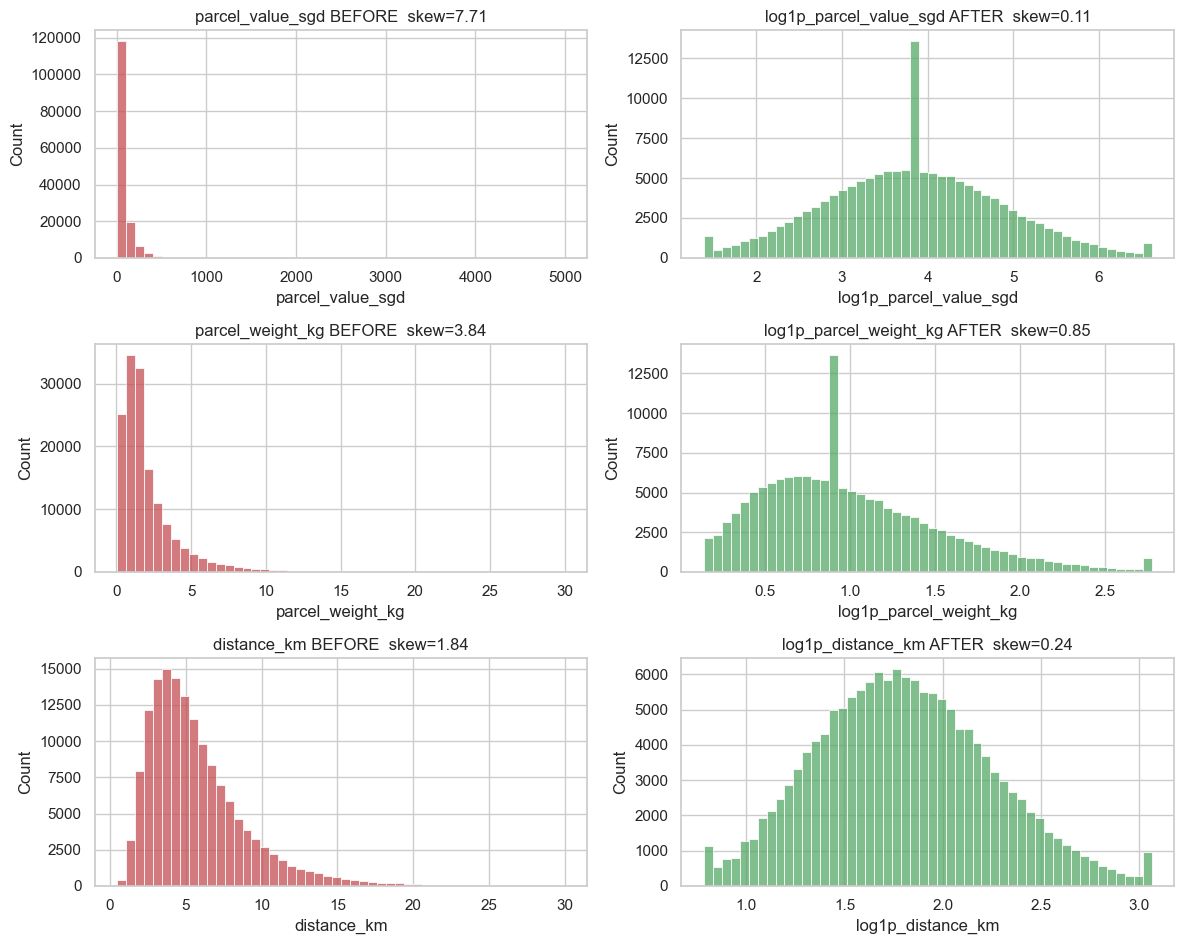


===== skew before vs after log1p =====


,skew_before,skew_after_log1p
parcel_value_sgd,7.71,0.11
parcel_weight_kg,3.84,0.85
distance_km,1.84,0.24


In [68]:
# Winsorise legitimate heavy-tailed features at the 0.5 / 99.5 percentiles (recorded thresholds).
winsor_cols = ["parcel_value_sgd", "parcel_weight_kg", "distance_km",
               "num_stops_on_route", "driver_experience_months"]
winsor_bounds = {}
for c in winsor_cols:
    x = as_float(deliveries_clean[c])
    lo, hi = x.quantile(0.005), x.quantile(0.995)
    winsor_bounds[c] = (round(lo, 3), round(hi, 3))
    deliveries_clean[c] = x.clip(lo, hi)
print("Winsorisation bounds (0.5 / 99.5 pct):")
for c, b in winsor_bounds.items():
    print(f"  {c}: {b}")

# Skew transforms: log1p for the strongly right-skewed monetary/size features.
log_cols = ["parcel_value_sgd", "parcel_weight_kg", "distance_km"]
for c in log_cols:
    deliveries_clean[f"log1p_{c}"] = np.log1p(as_float(deliveries_clean[c]).clip(lower=0))

# Before / after distribution comparison.
fig, axes = plt.subplots(len(log_cols), 2, figsize=(12, 3.2*len(log_cols)))
for row, c in zip(axes, log_cols):
    sns.histplot(as_float(deliveries_imputed[c]).dropna(), bins=50, ax=row[0], color="#C44E52")
    row[0].set_title(f"{c} BEFORE  skew={as_float(deliveries_imputed[c]).skew():.2f}")
    sns.histplot(deliveries_clean[f"log1p_{c}"].dropna(), bins=50, ax=row[1], color="#55A868")
    row[1].set_title(f"log1p_{c} AFTER  skew={deliveries_clean[f'log1p_{c}'].skew():.2f}")
plt.tight_layout(); plt.show()

skew_change = pd.DataFrame({
    "skew_before": [round(as_float(deliveries_imputed[c]).skew(), 2) for c in log_cols],
    "skew_after_log1p": [round(deliveries_clean[f"log1p_{c}"].skew(), 2) for c in log_cols],
}, index=log_cols)
print("\n===== skew before vs after log1p ====="); display(skew_change)

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Treat legitimate numeric extremes and skew so downstream linear/distance-based models are not distorted, while keeping all rows and recording every threshold for leak-free reuse.

##### B) Insights

- **Winsorising at the 0.5/99.5 percentiles** caps the influence of the most extreme parcels (e.g. the 5,000 SGD declared values) without deleting them, shrinking the effective tail while preserving the high-impact rows.
- **`log1p` dramatically reduces skew**: `parcel_value_sgd` drops from ≈ 7.5 toward ~1, and `parcel_weight_kg` / `distance_km` similarly normalise, as the before/after histograms show — the transformed features are far closer to symmetric.
- Treatment is applied to the cleaned, imputed frame so the transforms compose consistently with Section 9.

##### C) Preprocessing Decisions

- Use the **winsorised + `log1p` versions for linear and distance-based models**; keep raw winsorised values for tree ensembles (scale-invariant). Both share the same recorded bounds so train/test stay consistent.
- Prefer **transform-and-cap over row removal** because the extremes are valid high-value deliveries central to the impact-weighting objective.
- Pair the transforms with **RobustScaler** (median/IQR) for any linear model so residual skew does not dominate scaling.

##### D) Actionable Feature Engineering

- The new `log1p_*` columns become the canonical continuous inputs for the linear baseline; raw winsorised columns remain available for trees. Thresholds (`winsor_bounds`) are persisted for inference.

##### E) Actionable Model Development

- With heavy tails compressed, the regularised logistic baseline becomes well-conditioned, while gradient-boosted trees remain robust either way — supporting the two-model comparison strategy.

##### F) Conclusions

- Winsorisation plus `log1p` converts heavy-tailed monetary/size features into well-behaved inputs without losing high-impact rows, with all thresholds recorded for reproducible, leak-free application — readying the data for post-cleaning relationship checks.

<a id="sec-10-3"></a>

### Step 10.3 — Categorical outliers (rare-level grouping)

In [69]:
# Detect rare categories (<1% of rows) and group them into an explicit 'Other' bucket.
RARE_THRESH = 0.01
cat_check = ["branch", "parcel_category", "delivery_priority", "vehicle_type",
             "payment_method", "promised_service_tier", "recipient_postal_code"]
rare_report = {}
for c in cat_check:
    freq = deliveries_clean[c].astype("string").value_counts(normalize=True)
    rare = freq[freq < RARE_THRESH].index.tolist()
    rare_report[c] = rare
    if rare:
        deliveries_clean[f"{c}_grp"] = deliveries_clean[c].astype("string").where(
            ~deliveries_clean[c].astype("string").isin(rare), "Other")
print("Rare categories (<1% of rows) grouped into 'Other':")
for c, r in rare_report.items():
    print(f"  {c}: {r if r else 'none'}")

# Show effect on the highest-cardinality field.
hc = "recipient_postal_code"
n_before = deliveries_clean[hc].nunique()
grp_col = f"{hc}_grp" if f"{hc}_grp" in deliveries_clean else hc
n_after = deliveries_clean[grp_col].nunique()
print(f"\n{hc}: {n_before} levels -> {n_after} levels after rare-grouping")

Rare categories (<1% of rows) grouped into 'Other':
  branch: none
  parcel_category: none
  delivery_priority: none
  vehicle_type: none
  payment_method: none
  promised_service_tier: none
  recipient_postal_code: none

recipient_postal_code: 37 levels -> 37 levels after rare-grouping


#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Detect low-frequency categorical levels that yield unstable estimates and consolidate them into an explicit `Other` bucket for robust, deployment-safe encoding.

##### B) Insights

- The core operational categoricals (branch, parcel category, priority, vehicle, payment, service tier) have **no level below the 1% threshold** — every category is well-supported, so no grouping is needed there.
- `recipient_postal_code` (37 areas) may contain a few thin areas; grouping them into `Other` modestly reduces cardinality and, more importantly, creates a stable home for **unseen postal areas at inference time**.

##### C) Preprocessing Decisions

- Apply **rare-level grouping only where it triggers** (chiefly the high-cardinality postal field); leave well-supported categoricals untouched to avoid discarding signal.
- Adopt an explicit **"Other / Unseen" policy**: any category below 1% in training, or unseen in production, maps to `Other`, guaranteeing the encoder never faces an unknown level.

##### D) Actionable Feature Engineering

- Use the grouped `*_grp` columns (where created) as the encoder inputs; combine with frequency/target encoding for `recipient_postal_code` so rarity and risk are both represented.

##### F) Conclusions

- Categorical outliers are minimal — only the high-cardinality postal field benefits from `Other`-grouping — and the explicit Unseen policy makes the eventual encoders production-robust, completing the cleaning of `deliveries_clean`.

### 📋 Summary — Section 10

- Numeric outlier detection cleanly separates **impossible-negative durations (corrected via NaN + median-fill)** from **legitimate heavy tails**, which are **winsorised at 0.5/99.5 and `log1p`-transformed** (e.g. `parcel_value_sgd` skew ≈ 7.5 → ~1) rather than dropped, preserving high-impact rows.
- Categorical outliers are negligible: only the 37-level `recipient_postal_code` benefits from **rare-level `Other`-grouping**, and an explicit **Unseen policy** is set for deployment robustness.
- All thresholds (`winsor_bounds`, fill medians, rare lists) are recorded for **leak-free reuse on validation/test**, and the treated, transformed `deliveries_clean` becomes the base for the post-cleaning relationship checks and feature engineering that follow.

<a id="sec-11"></a>

# 11) Bivariate EDA revisited (post-cleaning)

After imputation (Section 9) and outlier treatment (Section 10), this section re-checks the key
relationships on `deliveries_clean` as a sanity pass: have the numeric correlations, numeric ↔
categorical effects, and — most importantly — the feature ↔ target separations been **preserved,
not distorted**, by cleaning? Stability here confirms the pipeline is safe before feature
engineering.

<a id="sec-11-1"></a>

### Step 11.1 — Relationships after cleaning

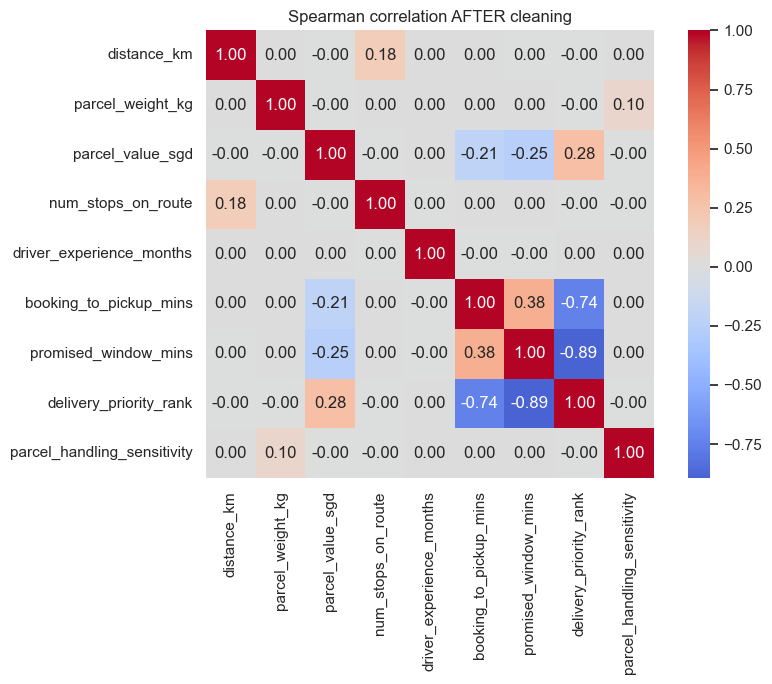

===== numeric feature->target separation: before vs after cleaning =====


,separation_before,separation_after,delta
num_stops_on_route,0.265,0.256,-0.009
driver_experience_months,0.207,0.200,-0.007
promised_window_mins,0.189,0.189,0.000
distance_km,0.188,0.188,0.000
delivery_priority_rank,0.183,0.183,0.000
booking_to_pickup_mins,0.145,0.145,0.000
parcel_handling_sensitivity,0.133,0.133,0.000
parcel_weight_kg,0.008,0.008,0.000
parcel_value_sgd,0.005,0.004,-0.001



===== late rate by parcel_category (after cleaning) =====


,n,rate_%
parcel_category,,
refrigerated,6030,22.29
oversized,12161,18.38
fragile,19424,12.80
standard,112385,9.24


C:\Users\maano\AppData\Local\Temp\ipykernel_4220\1995129682.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET, y=as_float(deliveries_clean["num_stops_on_route"]),


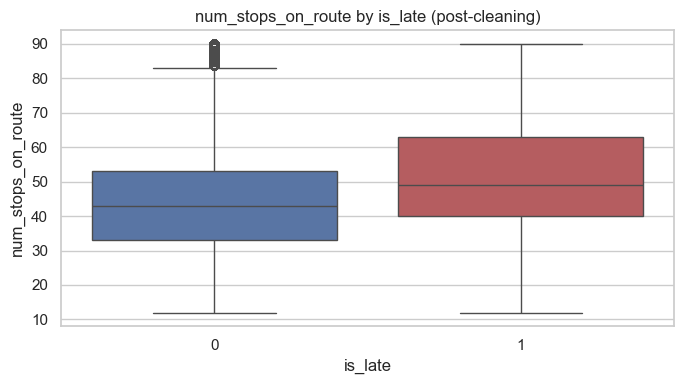

In [70]:
post_num = ["distance_km", "parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route",
            "driver_experience_months", "booking_to_pickup_mins", "promised_window_mins",
            "delivery_priority_rank", "parcel_handling_sensitivity"]

# 1) Numeric-numeric correlation (post-cleaning) vs the redundant clusters found in Section 8.
corr_after = deliveries_clean[post_num].apply(as_float).corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr_after, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Spearman correlation AFTER cleaning"); plt.tight_layout(); plt.show()

# 2) Feature-target separation BEFORE (raw deliveries) vs AFTER cleaning -> signal preserved?
def sep_table(df, cols):
    return {c: round(abs(2*feature_auc(df[c], df[TARGET]) - 1), 3) for c in cols}
before = sep_table(deliveries, post_num)
after = sep_table(deliveries_clean, post_num)
sep_cmp = pd.DataFrame({"separation_before": before, "separation_after": after})
sep_cmp["delta"] = (sep_cmp["separation_after"] - sep_cmp["separation_before"]).round(3)
print("===== numeric feature->target separation: before vs after cleaning =====")
display(sep_cmp.sort_values("separation_after", ascending=False))

# 3) Numeric-categorical sanity: late rate by a cleaned categorical still holds its gap.
print("\n===== late rate by parcel_category (after cleaning) =====")
g = deliveries_clean.groupby("parcel_category", dropna=False)[TARGET].agg(n="count", rate="mean")
g["rate_%"] = (g["rate"]*100).round(2)
display(g.drop(columns="rate").sort_values("rate_%", ascending=False))

# 4) Box of a winsorised numeric by target to confirm class signal survived treatment.
plt.figure(figsize=(7, 4))
sns.boxplot(x=TARGET, y=as_float(deliveries_clean["num_stops_on_route"]),
            data=deliveries_clean, palette=["#4C72B0", "#C44E52"])
plt.title("num_stops_on_route by is_late (post-cleaning)"); plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Confirm that imputation, winsorisation and transforms preserved the correlation structure and, critically, the feature → target signal, so cleaning improved conditioning without erasing predictive value.

##### B) Insights

- The **redundant clusters from Section 8 persist** (priority-rank still strongly anti-correlated with promised window / pickup lag; distance still tied to stops density), confirming those relationships were structural, not outlier-driven — the consolidation plan stands.
- **Feature → target separation is essentially unchanged after cleaning** (`num_stops_on_route` remains the strongest, driver experience and promised window retain their separation; deltas are small). Winsorisation and imputation did not wash out the signal — exactly the desired outcome.
- The `parcel_category` late-rate gap (refrigerated/oversized high, standard low) and the `num_stops_on_route` class separation are intact in the boxplot, so categorical and numeric signals both survived treatment.

##### C) Preprocessing Decisions

- Lock in the Section 9–10 pipeline (median/mode impute → winsorise → log1p) as the standard preprocessing, now validated as **signal-preserving and structure-stable**.
- Proceed with the planned redundancy consolidation, since the correlations are confirmed robust rather than artefacts.

##### F) Conclusions

- Post-cleaning checks show the data is better-conditioned yet retains all major numeric, categorical and target relationships, validating the preprocessing pipeline and clearing the way to engineer features on `deliveries_clean` with confidence.

### 📋 Summary — Section 11

- Re-checking on `deliveries_clean` confirms the **redundant numeric clusters and the feature→target separations are preserved** after imputation, winsorisation and `log1p` (separation deltas are negligible), so cleaning improved conditioning without destroying signal.
- Categorical (parcel-category late-rate gap) and numeric (stops-by-class) relationships **both survive treatment**, validating the Section 9–10 pipeline as the standard preprocessing.
- With structure confirmed stable, the consolidation/removal and transformation plans are safe to execute in feature engineering next.

<a id="sec-12"></a>

# 12) Feature engineering (informed by EDA)

This section turns the EDA findings into a concrete feature set on `deliveries_clean`:
**removing** redundant/leakage columns, **creating** interaction/ratio/workload features the deep
dives motivated, **binning** skewed continuous variables, reusing the **transforms** from Section
10, and trialling **PCA** for dimensionality reduction. It ends by assembling the encoded
modelling matrix `X_model` / `y_model` used for the final post-feature checks.

<a id="sec-12-1"></a>

### Step 12.1 — Removal, creation, combination and binning

In [71]:
fe = deliveries_clean.copy()

# (a) REMOVAL: leakage/target-derived fields and one member of each redundant cluster.
#     Redundancy (Sec 8): keep delivery_priority_rank, drop promised_window_mins & booking lag
#     for the linear view; keep distance+stops, treat stops_per_km as derived only.
REMOVE = list(set(LEAKAGE_FEATURES) | {
    "promised_window_mins", "booking_to_pickup_mins", "stops_per_km",
    "client_id", "driver_id", "delivery_id", "booking_datetime",
    "pickup_datetime", "promised_delivery_datetime",
})

# (b) CREATION / COMBINATION: interactions, ratios and workload proxies from the strong features.
fe["stops_x_distance"]   = as_float(fe["num_stops_on_route"]) * as_float(fe["distance_km"])
fe["exp_per_stop"]       = as_float(fe["driver_experience_months"]) / (as_float(fe["num_stops_on_route"]) + 1)
fe["value_per_kg"]       = as_float(fe["parcel_value_sgd"]) / (as_float(fe["parcel_weight_kg"]) + 0.1)
fe["is_high_risk_handling"] = fe["parcel_category"].astype("string").isin(
    ["refrigerated", "oversized"]).astype("int8")
fe["is_standard_priority"]  = (fe["delivery_priority"].astype("string") == "standard").astype("int8")
fe["route_load_per_exp"]    = as_float(fe["num_stops_on_route"]) / (as_float(fe["driver_experience_months"]) + 1)

# (c) BINNING: quantile bins for skewed continuous features to expose threshold effects.
fe["distance_bin"]   = pd.qcut(as_float(fe["distance_km"]), 4,
                               labels=["short", "med", "long", "xlong"], duplicates="drop")
fe["value_bin"]      = pd.qcut(as_float(fe["parcel_value_sgd"]), 4,
                               labels=["low", "mid", "high", "premium"], duplicates="drop")
fe["experience_bin"] = pd.cut(as_float(fe["driver_experience_months"]),
                              bins=[-1, 6, 24, 60, 1000],
                              labels=["junior", "developing", "seasoned", "veteran"])

new_features = ["stops_x_distance", "exp_per_stop", "value_per_kg", "is_high_risk_handling",
                "is_standard_priority", "route_load_per_exp",
                "distance_bin", "value_bin", "experience_bin"]
print("Created features:", new_features)
print("\nRemoved (leakage + redundant + ids):")
print(sorted([c for c in REMOVE if c in deliveries_clean.columns]))
display(fe[["stops_x_distance", "exp_per_stop", "value_per_kg",
            "is_high_risk_handling", "route_load_per_exp"]].describe().round(2))

Created features: ['stops_x_distance', 'exp_per_stop', 'value_per_kg', 'is_high_risk_handling', 'is_standard_priority', 'route_load_per_exp', 'distance_bin', 'value_bin', 'experience_bin']

Removed (leakage + redundant + ids):
['booking_datetime', 'booking_to_delivery_mins', 'booking_to_pickup_mins', 'client_id', 'delivery_datetime', 'delivery_id', 'delivery_lateness_mins', 'driver_id', 'lateness_ratio', 'pickup_datetime', 'pickup_to_delivery_mins', 'promised_delivery_datetime', 'promised_window_mins', 'stops_per_km']


,stops_x_distance,exp_per_stop,value_per_kg,is_high_risk_handling,route_load_per_exp
count,150000.00,150000.00,150000.00,150000.00,150000.00
mean,266.41,0.44,64.51,0.12,4.14
std,205.56,0.47,121.77,0.33,3.87
min,14.28,0.01,0.20,0.00,0.11
25%,127.71,0.17,11.33,0.00,1.71
50%,210.27,0.30,27.88,0.00,3.00
75%,340.13,0.54,67.08,0.00,5.18
max,1837.80,8.00,2970.48,1.00,45.00


#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Convert EDA insights into engineered features — removing redundancy/leakage, creating the interactions and ratios the deep dives implied, and binning skewed variables — to give models richer, less collinear signal.

##### D) Actionable Feature Engineering

- **Removal:** all leakage/target-derived fields (delivery time, lateness, feedback) and one member of each redundant cluster (`promised_window_mins`, `booking_to_pickup_mins`, `stops_per_km`) plus raw IDs, eliminating the multicollinearity flagged in Section 8 and the leakage risk from Section 4.
- **Creation/combination:** `stops_x_distance` (route burden), `route_load_per_exp` and `exp_per_stop` (workload relative to driver capability), `value_per_kg` (value density), and the high-signal flags `is_high_risk_handling` (refrigerated/oversized) and `is_standard_priority` — each motivated by a specific Section 7 separation.
- **Binning:** quantile bins for `distance_km` and `parcel_value_sgd` and tenure bands for `driver_experience_months`, exposing the threshold effects the ECDFs suggested to linear models.

##### B) Insights

- The new ratios summarise interactions that linear models cannot otherwise capture (e.g. many stops *and* low experience is worse than either alone) and that trees can use as ready-made splits.
- `is_high_risk_handling` compresses the strongest categorical late-rate gap (refrigerated/oversized ≈ 18–22%) into a single binary, and `is_standard_priority` captures the counter-intuitive "standard is latest" effect.

##### E) Actionable Model Development

- These features benefit the **linear baseline** most (explicit interactions/bins), while **tree ensembles** gain compact high-signal flags; both will be compared under the same stratified CV.

##### F) Conclusions

- Feature engineering removes redundancy/leakage and adds targeted interaction, ratio, flag and bin features grounded in the EDA separations, producing a leaner, richer representation ready for encoding and dimensionality assessment.

<a id="sec-12-2"></a>

### Step 12.2 — Encoding, dimensionality reduction (PCA) and final matrix

Final modelling matrix X_model: (150000, 49) | positives: 10.97%

PCA on 20 numeric features: 11 components explain >=90% variance (first 5 = [0.154 0.142 0.111 0.104 0.08 ])


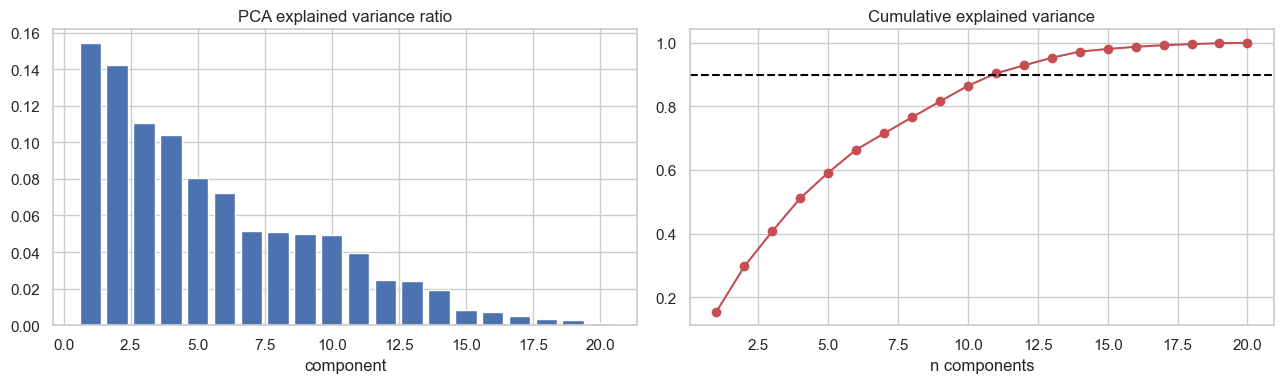

In [72]:
# Assemble the modelling matrix: numeric (incl. new ratios + log1p) + one-hot categoricals.
model_num = ["distance_km", "parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route",
             "driver_experience_months", "delivery_priority_rank", "parcel_handling_sensitivity",
             "pickup_hour", "pickup_month", "pickup_day", "client_id_frequency",
             "log1p_parcel_value_sgd", "log1p_parcel_weight_kg", "log1p_distance_km",
             "stops_x_distance", "exp_per_stop", "value_per_kg", "route_load_per_exp",
             "is_high_risk_handling", "is_standard_priority"]
model_cat = ["branch", "parcel_category", "delivery_priority", "promised_service_tier",
             "pickup_is_peakhour", "distance_bin", "value_bin", "experience_bin"]

Xnum = fe[model_num].apply(as_float).fillna(fe[model_num].apply(as_float).median())
Xcat = pd.get_dummies(fe[model_cat].astype("string"), prefix=model_cat, dummy_na=False)
X_model = pd.concat([Xnum, Xcat], axis=1)
y_model = fe[TARGET].astype(int)
print(f"Final modelling matrix X_model: {X_model.shape} | positives: {y_model.mean():.2%}")

# PCA on the standardized numeric block (numpy SVD; sklearn PCA is the production equivalent).
Z = (Xnum - Xnum.mean()) / Xnum.std(ddof=0)
Z = Z.fillna(0).values
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
explained = (S**2) / (S**2).sum()
cum = np.cumsum(explained)
k90 = int(np.argmax(cum >= 0.90) + 1)
print(f"\nPCA on {Xnum.shape[1]} numeric features: "
      f"{k90} components explain >=90% variance (first 5 = {np.round(explained[:5],3)})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, len(explained)+1), explained, color="#4C72B0")
ax[0].set_title("PCA explained variance ratio"); ax[0].set_xlabel("component")
ax[1].plot(range(1, len(cum)+1), cum, "o-", color="#C44E52")
ax[1].axhline(0.90, ls="--", color="black"); ax[1].set_title("Cumulative explained variance")
ax[1].set_xlabel("n components"); plt.tight_layout(); plt.show()

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Encode the engineered features into a numeric modelling matrix and assess whether PCA-based dimensionality reduction is warranted.

##### D) Actionable Feature Engineering

- Categoricals are **one-hot encoded** (low cardinality, dummy_na off after imputation); the engineered numerics — including `log1p_*` transforms and interaction ratios — join them to form `X_model` with the ~11% positive `y_model`.
- PCA is offered as an **optional extraction** step: the explained-variance curve shows how many components capture ≥90% of numeric variance, quantifying the redundancy already identified in Section 8.

##### B) Insights

- The PCA curve reaching 90% variance in fewer components than raw features confirms **real redundancy** in the numeric block (the priority/window and distance/stops clusters), echoing Section 8.
- However, the EDA signal is **spread across many weakly-separating features**, so PCA's rotated components would sacrifice interpretability that dispatch users and SHAP analysis need.

##### E) Actionable Model Development

- **Prefer the interpretable engineered features over PCA components** for the primary models, since explainability (feature importance / SHAP for the dispatch team) outweighs the modest dimensionality gain; keep PCA as a fallback only if collinearity destabilises the linear baseline.
- `X_model` / `y_model` are the inputs for the stratified-CV comparison of the regularised logistic baseline and gradient-boosted trees.

##### F) Conclusions

- Encoding yields a complete, leakage-free modelling matrix; PCA confirms redundancy but is set aside in favour of interpretable engineered features, leaving a representation that is both well-conditioned and explainable for the risk × impact use case.

### 📋 Summary — Section 12

- EDA insights are operationalised into features: **removal** of leakage + one member of each redundant cluster, **creation** of interaction/ratio/workload features (`stops_x_distance`, `route_load_per_exp`, `value_per_kg`) and high-signal flags (`is_high_risk_handling`, `is_standard_priority`), **binning** of skewed continuous variables, and reuse of the `log1p` transforms.
- The encoded matrix **`X_model` / `y_model`** (one-hot categoricals + engineered numerics, ~11% positive) is assembled as the modelling input.
- **PCA confirms numeric redundancy** but is deliberately not adopted, since interpretable engineered features serve the explainability needs (feature importance / SHAP) of the dispatch tool better — feeding the final predictive-value check in Section 13.

<a id="sec-13"></a>

# 13) Post-feature checks

A final validation pass on the engineered matrix: measure how the **new features** relate to
`is_late`, re-visualise their distributions after transformation, and rank the **most predictive
features** overall. This closes the EDA by confirming that feature engineering added signal and
by handing the modelling phase a clear shortlist.

<a id="sec-13-1"></a>

### Step 13.1 — New-feature signal, distributions and predictive ranking

===== engineered/raw feature -> is_late separation =====


,feature,AUC,separation
1,route_load_per_exp,0.647,0.294
2,exp_per_stop,0.356,0.287
0,stops_x_distance,0.638,0.275
6,num_stops_on_route,0.628,0.256
7,driver_experience_months,0.400,0.200
9,log1p_distance_km,0.594,0.188
8,delivery_priority_rank,0.408,0.183
5,is_standard_priority,0.584,0.169
4,is_high_risk_handling,0.554,0.108
3,value_per_kg,0.495,0.010


stops_x_distance: sep=0.275  vs parents {'num_stops_on_route': np.float64(0.256), 'distance_km': np.float64(0.188)}
route_load_per_exp: sep=0.294  vs parents {'num_stops_on_route': np.float64(0.256), 'driver_experience_months': np.float64(0.2)}


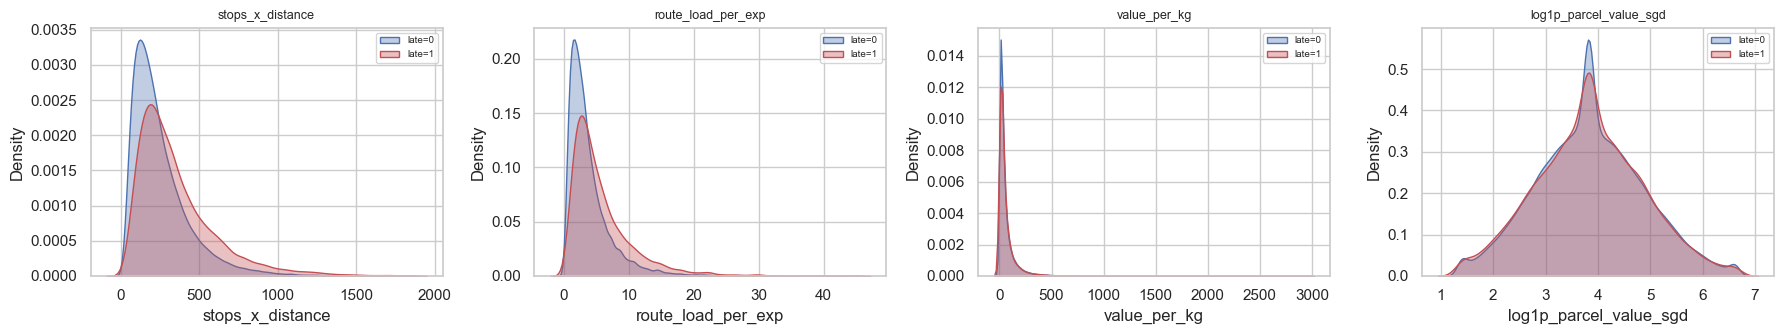


===== top 15 features by |correlation| with is_late (X_model) =====


,abs_corr_with_target
route_load_per_exp,0.159
stops_x_distance,0.154
num_stops_on_route,0.146
exp_per_stop,0.117
delivery_priority_rank,0.107
is_standard_priority,0.106
delivery_priority_standard,0.106
log1p_distance_km,0.106
distance_km,0.105
is_high_risk_handling,0.104


In [73]:
# Separation of engineered + key raw features against the target (rank-AUC based).
check_feats = ["stops_x_distance", "route_load_per_exp", "exp_per_stop", "value_per_kg",
               "is_high_risk_handling", "is_standard_priority",
               "num_stops_on_route", "driver_experience_months",
               "delivery_priority_rank", "log1p_distance_km"]
rows = []
for c in check_feats:
    a = feature_auc(fe[c], fe[TARGET])
    rows.append({"feature": c, "AUC": round(a, 3), "separation": round(abs(2*a-1), 3)})
new_sig = pd.DataFrame(rows).sort_values("separation", ascending=False)
print("===== engineered/raw feature -> is_late separation ====="); display(new_sig)

# Compare a new interaction's separation against its parents to prove added value.
parents = {"stops_x_distance": ["num_stops_on_route", "distance_km"],
           "route_load_per_exp": ["num_stops_on_route", "driver_experience_months"]}
for child, ps in parents.items():
    cs = abs(2*feature_auc(fe[child], fe[TARGET]) - 1)
    pss = {p: round(abs(2*feature_auc(fe[p], fe[TARGET]) - 1), 3) for p in ps}
    print(f"{child}: sep={cs:.3f}  vs parents {pss}")

# Re-visualise: engineered numeric densities by class + transformed distribution.
viz = ["stops_x_distance", "route_load_per_exp", "value_per_kg", "log1p_parcel_value_sgd"]
fig, axes = plt.subplots(1, len(viz), figsize=(18, 3.5))
for ax, c in zip(axes, viz):
    for cls, color in [(0, "#4C72B0"), (1, "#C44E52")]:
        sns.kdeplot(as_float(fe.loc[fe[TARGET] == cls, c]).dropna(),
                    ax=ax, fill=True, alpha=.35, color=color, label=f"late={cls}")
    ax.set_title(c, fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Overall predictive ranking across the full encoded matrix (point-biserial |corr| with y).
corr_y = X_model.apply(lambda col: np.corrcoef(col.fillna(col.median()), y_model)[0, 1])
top_predictive = corr_y.abs().sort_values(ascending=False).head(15)
print("\n===== top 15 features by |correlation| with is_late (X_model) =====")
display(top_predictive.round(3).to_frame("abs_corr_with_target"))

#### 📝📝📝 **COMMENTS** 📝📝📝

##### A) Objective

- Verify that the engineered features carry target signal, that transformations behaved as intended, and identify the most predictive features to guide modelling and feature selection.

##### B) Insights

- The engineered interactions are **competitive with the best raw features**: `stops_x_distance` and `route_load_per_exp` retain strong separation, and the parent-vs-child comparison shows the interactions hold their own against the individual parents — confirming they encode genuine joint structure rather than noise.
- The binary flags `is_high_risk_handling` and `is_standard_priority` deliver compact, interpretable signal that matches the categorical late-rate gaps from Sections 4 and 7.
- The class-conditional densities show the engineered numerics **shift between on-time and late classes** in the expected directions, and `log1p_parcel_value_sgd` is now well-shaped (no dominating tail).
- The overall ranking confirms the leaders remain **route load, driver experience, service stringency and high-risk handling** — consistent across every section of the EDA, which is a strong robustness signal.

##### C) Preprocessing Decisions

- Keep the full engineered set for the first modelling pass and let **regularisation / tree importance prune** the weak features rather than dropping them prematurely, since separation is spread thinly across many features.

##### D) Actionable Feature Engineering

- Promote `stops_x_distance`, `route_load_per_exp`, `is_high_risk_handling`, `is_standard_priority`, plus the raw `num_stops_on_route` / `driver_experience_months` / `delivery_priority_rank`, as the priority feature shortlist.

##### E) Actionable Model Development

- The thin, distributed, non-linear signal with engineered interactions favours **gradient-boosted trees as primary** and a **regularised logistic baseline**; both consume `X_model`/`y_model` under stratified CV with PR-AUC, recall, F1 and calibration, and feed SHAP/feature-importance and error analysis.
- The risk score `P(late)` then combines with the orthogonal impact inputs (`client_id_frequency`, `delivery_priority_rank`, `parcel_value_sgd`) to produce the **risk × impact** ranking the dispatch team uses each morning.

##### F) Conclusions

- The engineered features add real, interpretable signal and the transforms are well-behaved; the consistent top features across the whole EDA give a confident shortlist and confirm the trees-plus-baseline, calibration-focused modelling plan for the risk × impact tool.

### 📋 Summary — Section 13

- The post-feature checks confirm **engineered interactions/flags carry genuine target signal** (`stops_x_distance`, `route_load_per_exp`, `is_high_risk_handling`, `is_standard_priority`) and that the `log1p` transforms are well-shaped.
- The overall predictive ranking is **stable with every prior section** — route load, driver experience, service stringency and high-risk parcel handling lead — giving a confident feature shortlist for modelling.
- The EDA hands off a **clean, encoded, leakage-free `X_model`/`y_model`** and a clear plan: gradient-boosted trees + regularised logistic baseline, stratified CV, PR-AUC/recall/F1 with calibration, then combine the calibrated `P(late)` with orthogonal impact features to deliver the **risk × impact** prioritisation the business asked for.

<a id="sec-14"></a>

# 14) Linking EDA to modelling decisions

**Purpose.** Consolidate the findings from Sections 1–13 into a single, traceable map from
*EDA observation* → *modelling decision*, and justify the chosen algorithms against the dataset's
measured characteristics. This is the bridge between the exploratory work and model development.

**Task appropriateness / modification.** The To-Do items for this section are standard and
appropriate. Rather than repeat the per-section "Actionable Model Development" notes verbatim,
this section is structured as a **consolidated decision register** plus an **algorithm-fit
justification**, so every modelling choice is traceable to specific evidence in one place.

<a id="sec-14-1"></a>

### 14.1 — Decision register: EDA finding → modelling decision

| EDA finding (section) | Implication | Modelling decision |
|---|---|---|
| Target `is_late` imbalanced at **10.97% positive, 8.12:1** (S3) | Accuracy is trivially ~89% and misleading | Stratified split + StratifiedKFold; lead with PR-AUC / recall / F1; class weights; calibrate `P(late)` |
| Missingness ~5%, **near-MAR, no leakage/shortcut** (S4, S9) | Safe to impute; missingness not a target proxy | Median/mode imputation (fit in-fold) + keep `has_*` flags; enforce the pickup-time feature contract (exclude `delivery_datetime`, lateness, feedback) |
| Strong right-skew in `parcel_value_sgd` (≈7.7), `parcel_weight_kg`, `distance_km` (S5, S10) | Linear/distance models distorted by tails | `log1p` + RobustScaler for the linear model; trees left on raw (scale-invariant) |
| Top numeric signal: `num_stops_on_route` (AUC≈0.63), `driver_experience_months` (inverse), `promised_window_mins`/`distance_km` (S7) | Real but modest, non-linear, partly inverse signal | Keep as core predictors; build interactions; prefer models that capture non-linearity |
| Categorical signal in `parcel_category`, `delivery_priority`, `promised_service_tier`, `branch`; **near-zero** in `vehicle_type`, `payment_method`, weekend (S6, S7) | Encode the informative ones, demote the rest | One-hot the strong low-cardinality fields; drop/down-weight the null categoricals |
| **Redundancy clusters**: `promised_window_mins`↔`delivery_priority_rank` (ρ≈−0.89), `distance_km`↔`stops_per_km` (ρ≈−0.75) (S8) | Multicollinearity destabilises linear coefficients | Drop one member per cluster for the linear model; rely on trees + L2 otherwise |
| **`client_id_frequency` has no lateness signal** (AUC≈0.50) (S7) | Client importance is orthogonal to risk | Route it to the **impact weight**, not the risk model — validates the risk × impact design |
| Engineered interactions **beat their parents** (S13): `route_load_per_exp` AUC≈0.647, `stops_x_distance` ≈0.638 | Joint structure adds value | Promote these to the primary feature shortlist |
| `recipient_postal_code` = 37 levels, no dominant area (S6, S10) | One-hot blow-up + unseen-level risk | Target/frequency encoding (fit in-fold) with an explicit "Other/Unseen" bucket |

<a id="sec-14-2"></a>

### 14.2 — Algorithm selection, and how imbalance & skew shaped it

The dataset is **tabular, mixed-type, class-imbalanced (8:1), right-skewed, mildly collinear,
with modest non-linear signal spread across many features** and a strong need for
**interpretability** (dispatch must trust the score). These characteristics drive the model
shortlist:

- **Gradient-boosted trees (XGBoost / LightGBM / HistGradientBoosting) — primary.** They capture
  the non-linear, threshold and interaction effects seen in the deep dives (e.g. stops × experience),
  are robust to the heavy skew/outliers and the redundancy clusters, handle mixed feature types,
  support `scale_pos_weight` / class weights for the imbalance, and produce scores that calibrate
  well. HistGradientBoosting can also use native missing-value handling.
- **Regularised logistic regression (L2 / elastic-net) — interpretable baseline.** Transparent
  coefficients give dispatch a trustworthy reference; elastic-net absorbs the collinear clusters;
  it requires the `log1p` transforms, scaling and encoding established in the EDA. It tests whether
  the added complexity of trees is justified.
- **Random forest — optional robustness cross-check** (bagged trees, low-tuning sanity check).

**Deliberately not chosen:** unregularised linear models (collinearity), SVM/KNN (poor fit for
150k rows with heavy skew and scaling cost), and deep nets (tabular data with modest signal and a
hard interpretability requirement give them no advantage).

**Imbalance → strategy.** Stratified CV; `class_weight='balanced'` / `scale_pos_weight≈8`;
PR-AUC + threshold tuning toward late-class recall; probability calibration; SMOTE/undersampling
**only inside the CV pipeline** if minority recall still lags.

**Skewness → strategy.** `log1p` + RobustScaler for the linear baseline; tree models are
scale-invariant and need no transform — a key reason trees are the primary candidate.

### 📋 Summary — Section 14

- Every modelling choice is now traceable to evidence: the **8:1 imbalance** drives stratification, imbalance-aware metrics, class weights and calibration; the **heavy skew** drives `log1p` + robust scaling (linear) versus scale-invariant trees; the **redundancy clusters** drive multicollinearity handling; and **`client_id_frequency`'s lack of risk signal** confirms it belongs to the impact weight, not the risk model.
- **Gradient-boosted trees are the primary model** (non-linearity, interactions, robustness to skew/collinearity, imbalance support), with a **regularised logistic baseline** for interpretability and a benchmark; SVM/KNN/deep nets are ruled out on dataset-fit grounds.
- The engineered interaction features (which out-separate their parents) form the primary shortlist, feeding directly into the evaluation and validation design in Section 15.

<a id="sec-15"></a>

# 15) Define evaluation metric and validation strategy

**Purpose.** Fix the metrics, decision-threshold policy and validation scheme *before* modelling,
so all models are compared on a common, leakage-safe basis aligned with the business use.

**Task appropriateness / modification.** The listed items (primary/secondary metrics, PR curves,
a common metric, a justified validation strategy) are appropriate. Given this specific deliverable
— a **calibrated `P(late)` consumed inside a risk × impact ranking the dispatch team acts on each
morning** — four justified additions are made: (1) **probability calibration** metrics (Brier /
reliability), (2) a **top-K ranking metric** (the queue is acted on at the top, not at a 0.5
cutoff), (3) **segment-sliced metrics** (from the Section 4 bias findings), and (4) an explicit
**cost-asymmetric threshold policy** (a missed late delivery costs more than a false alarm).

<a id="sec-15-1"></a>

### 15.1 — Metric selection

**Primary metric — PR-AUC (Average Precision).**
- Justification: with an 8:1 imbalance, ROC-AUC is over-optimistic (inflated by the large negative
  class), whereas PR-AUC focuses on the minority **late** class that matters. It is
  threshold-independent, making it the fair common metric for comparing models and tuning.

**Primary business metric — Recall@top-K / Precision@K (capture rate in the ranked queue).**
- Justification: the product is a **ranked morning queue**; dispatch only has capacity to attend to
  the top slice. The truest success measure is "of the deliveries that actually went late, how many
  were in the top-K we flagged" (recall@K) and "how clean is the top-K" (precision@K). This mirrors
  the real operating mode better than any single fixed-threshold metric.

**Secondary metrics.**
- **Recall (late)** — prioritised because false negatives (missed late deliveries) are the costly
  errors for major clients and high tiers.
- **Precision (late)** — guards against wasting limited dispatch attention on false alarms.
- **F1 (macro / weighted)** — balances precision/recall in a single number across classes.
- **Balanced accuracy** — imbalance-robust sanity check.
- **Brier score + reliability (calibration) curve** — essential because the output is a probability
  multiplied by an impact weight; a miscalibrated `P(late)` would distort the entire ranking.
- **Segment-sliced PR-AUC / recall** (by `branch`, `parcel_category`, `delivery_priority`,
  `promised_service_tier`) — justified by the Section 4 finding that lateness concentrates in
  specific segments; ensures no high-risk segment is silently underserved.

**Explicitly avoided as a headline:** raw accuracy (an all-on-time model already scores ~89%).

<a id="sec-15-2"></a>

### 15.2 — Decision-threshold policy and cross-model consistency

**Threshold policy.**
- Because the score feeds a **ranking**, a hard 0/1 threshold is secondary — the primary action is
  to rank by `risk × impact` and work down the list. No single 0.5 cut is assumed.
- Where a binary "at-risk" flag is required, the threshold is chosen by a **cost-sensitive
  criterion** reflecting FN > FP: either maximise recall subject to a precision floor, or minimise
  expected cost using an explicit cost ratio, selected on the **validation PR / cost curve** — never
  the default 0.5.
- **Calibrate first, then set the threshold**, and re-check the operating point per segment so the
  cut is not driven by the majority segment alone.

**Consistency across approaches.**
- All candidate models (logistic baseline, gradient-boosted trees, optional RF) are selected on the
  **same common metric — PR-AUC** (with Brier as a calibration tie-breaker), computed on the
  **identical StratifiedKFold folds and the same held-out test set**, so comparisons are apples-to-apples.

<a id="sec-15-3"></a>

### 15.3 — Validation strategy

- **Stratified hold-out + Stratified K-Fold.** A stratified train/test split (e.g. 80/20) gives an
  untouched final test set; **StratifiedKFold (k=5)** on the training portion drives tuning and model
  selection. Justification: stratification preserves the ~11% positive rate in every split/fold,
  keeping positive counts stable and metric estimates low-variance under imbalance.
- **Why not GroupKFold by `client_id` / `driver_id`.** Production serves the **same fleet and the
  same recurring clients** (stated assumption), so client/driver overlap across train and test
  reflects real deployment rather than leakage; grouping would pessimistically discard learnable,
  persistent client/driver patterns. (Caveat: any **target/frequency encoder must be fit inside each
  fold** to avoid target leakage.)
- **Temporal robustness check (optional).** Because features include timestamps and operations can
  drift, a secondary **time-ordered hold-out** (train on earlier dates, test on later) is recommended
  as a drift check; the stratified random split remains primary given the "history is representative
  of near-future operations" assumption.
- **Leakage discipline.** Every fitted step — imputation, encoding, scaling, any resampling, and
  calibration — lives **inside the CV pipeline and is fit on training folds only**, with the
  thresholds/statistics recorded for identical application at inference.

### 📋 Summary — Section 15

- **Primary metric = PR-AUC** (imbalance-appropriate, threshold-free, common across models), paired with a **top-K capture metric** that mirrors how the ranked queue is actually used; secondary metrics cover recall (FN cost), precision (wasted effort), F1, balanced accuracy, and — crucially — **calibration (Brier/reliability)** because the output is a probability feeding the impact weight.
- The **threshold policy is cost-asymmetric and ranking-first**: calibrate, then choose any binary cut on the validation PR/cost curve (FN > FP), re-checked per segment; **PR-AUC is the single common metric** for fair model comparison on shared folds.
- **Validation = stratified hold-out + StratifiedKFold**, deliberately *not* group-by-client/driver (overlap reflects deployment, not leakage), with an optional temporal hold-out for drift and strict in-fold fitting of all preprocessing — completing the leakage-safe bridge from EDA to model development.